# **HAM10000 Skin Lesion Classification — Data Analysis of the Training Results**

This notebook is the **data-analysis notebook of the project**. The heavy, long-running work (building the dataset and training the EfficientNet models) is done by standalone Python scripts (`balance_dataset_new.py`, `entrenamiento_binario_mel.py`, `sparse_categorical_crossentropy.py`), which we ran remotely inside `tmux` on a machine with a more powerful GPU. This notebook **reads what those scripts produce** (split metadata, per-image predictions, training histories and the saved models) and analyses it.

> **Where to start: jump to Section 10 or 11.** That is where the results presented in class are; **Section 11 has the final, leakage-free results**. Run cells 11.1 and 11.2 first, because the later cells reuse their results.

## Final results (Sections 10 and 11)

The final experiments (Section 11) use a dataset split **by `lesion_id` into 70 / 15 / 15** (train / validation / test) **before** any processing, so that no lesion is shared between subsets. They compare an EfficientNet-B4 trained with **four preprocessing pipelines** (Baseline, DullRazor, Shades of Gray, Contrast-Focused) at **two input resolutions** (128×128 and 224×224), for two tasks: **melanoma vs. non-melanoma** and the **7 HAM10000 classes**.

| Section | What it gives |
|---|---|
| **10** | Visual comparison of the four preprocessing pipelines on the same images, and a first comparison of the binary melanoma classifier across the pipelines. It reads the runs in `runs/`, trained **before** the leakage fix; Section 11 repeats the comparison with the corrected split. |
| **11.1 – 11.2** | Run discovery and **validity audit**: all 16 runs found, no lesion shared between splits, the same validation images for every run, and `--preprocessing` as the only configuration difference. |
| **11.3** | **Binary classifier:** AUC, average precision and specificity at the clinical operating point (sensitivity ≥ 85%), with 95% lesion-level bootstrap intervals and paired differences vs. Baseline. |
| **11.4** | **7-class classifier:** macro-F1, balanced accuracy, melanoma recall, per-class recall and confusion matrices. |
| **11.5** | Effect of the input resolution (128×128 vs. 224×224). |
| **11.6** | Dedicated binary model vs. the multiclass model's P(mel) as melanoma detectors. |
| **11.7 – 11.8** | Before/after comparison of the leakage fix (descriptive only) and a summary of the selected pipelines. |
| **11.9 – 11.11** | **Independent test set** (224×224): final evaluation of the multiclass and binary models, including the binary models at the threshold frozen from validation. |

## Data not included in the git repository

Because of their size, some of the folders and files that this notebook reads are **not stored in the git repository**. They are available in this Google Drive folder:

**https://drive.google.com/drive/folders/1b68CgDD96FoCi3ejsCHjlcvXKuAGB6NU?usp=drive_link**


## Earlier exploratory work (Sections 1–9)

Sections 1–6 explore the dataset (metadata, class distribution, example images, preprocessing steps). Sections 7–9 document a **first balancing approach** (`balance_dataset.py`) and the models trained on it. That approach built the balanced set from the whole dataset before splitting it, which caused **data leakage** between training and validation (m.5). It was later replaced by the lesion-level split, so **these sections are kept for reference only, and their results are not the final ones.**

**Requirements.** Most sections only need NumPy, pandas, Matplotlib, seaborn, OpenCV, Pillow, SciPy and scikit-learn. The test-set evaluation (11.9 and 11.10) loads the trained `.keras` models, so it also needs TensorFlow.

**How to use it:** check the paths in section 1 and at the start of Section 11, then run the sections you need. Most sections first check that their inputs exist and, if they don't, print a `[skipped]` message instead of failing.

> Educational use only — not suitable for clinical diagnosis.

**Contents**
1. Setup and configuration
2. About the dataset
3. Metadata exploration
4. Train / validation organisation
5. Example images
6. Image preprocessing
7. Class balancing analysis *(first balancing approach, with leakage)*
8. Training results (binary melanoma classifier) *(trained on the first balanced dataset)*
9. Notes and caveats
10. **Final comparison: binary melanoma classifier and four preprocessing pipelines**
11. **Results after the data-leakage fix: binary and multiclass classifiers** (final results, including the independent test set)

## 1. Setup and configuration
Only light dependencies are needed: NumPy, pandas, Matplotlib, seaborn, OpenCV, Pillow and scikit-learn.
The default paths match the ones used by `balance_dataset.py` and `entrenamiento_binario_mel.py` (everything relative to the working directory).

In [1]:
import json
import os
import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# ---- Paths: adjust them if your layout is different -----------------------------------------
BASE_DIR     = Path(".")
METADATA_CSV = BASE_DIR / "HAM10000_metadata.csv"
IMAGE_DIRS   = [BASE_DIR / "HAM10000_images_part_1", BASE_DIR / "HAM10000_images_part_2"]
DATASET_DIR  = BASE_DIR / "Datasets"                          # training/<class>/ and validation/<class>/
BALANCED_DIR = BASE_DIR / "balancing" / "dataset_balanced"    # output of balance_dataset.py
RUNS_DIR     = BASE_DIR / "runs"                              # output of entrenamiento_binario_mel.py
RUN_DIR      = RUNS_DIR / "B1_binario_B4_128_20261009_171524"   # None = most recent run inside RUNS_DIR; or e.g. RUNS_DIR / "B1_binario_B4_128_20261010_120000"
RESULTS_CSV  = BASE_DIR / "results.csv"                       # earlier 7-class experiments (for comparison)

TRAIN_DIR, VAL_DIR = DATASET_DIR / "training", DATASET_DIR / "validation"

# ---- Classes ---------------------------------------------------------------------------------
CLASS_INFO = {
    "akiec": "Actinic keratoses and intraepithelial carcinoma (Bowen's disease)",
    "bcc":   "Basal cell carcinoma",
    "bkl":   "Benign keratosis-like lesions (solar lentigines, seborrheic keratoses, lichen-planus-like keratoses)",
    "df":    "Dermatofibroma",
    "mel":   "Melanoma",
    "nv":    "Melanocytic nevi",
    "vasc":  "Vascular lesions (angiomas, angiokeratomas, pyogenic granulomas, haemorrhage)",
}
CLASSES = list(CLASS_INFO)
CLASS_COLORS = dict(zip(CLASSES, plt.get_cmap("viridis")(np.linspace(0, 1, len(CLASSES)))))


# ---- Small helpers used throughout the notebook ----------------------------------------------
def image_ext(name):
    return name.lower().endswith((".jpg", ".jpeg", ".png"))


def strip_aug(name):
    # "ISIC_0001234_aug_12.jpg" -> "ISIC_0001234" (augmented copies keep the id of their source image)
    return re.sub(r"_aug_\d+$", "", Path(name).stem)


def read_rgb(path):
    # imdecode + fromfile also works with non-ASCII paths on Windows
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def list_images(folder):
    # Inventory of a folder organised as <folder>/<class>/<file>.jpg
    folder = Path(folder)
    rows = []
    for c in sorted(p.name for p in folder.iterdir() if p.is_dir()):
        for f in sorted(os.listdir(folder / c)):
            if image_ext(f):
                rows.append((strip_aug(f), c, f, "_aug_" in f))
    return pd.DataFrame(rows, columns=["image_id", "cls", "file", "augmented"])


def find_run_dir(runs_dir=RUNS_DIR):
    # Most recent run folder that contains the per-epoch history
    runs_dir = Path(runs_dir)
    if not runs_dir.exists():
        return None
    cands = [d for d in runs_dir.iterdir() if d.is_dir() and (d / "historial_epocas.csv").exists()]
    return max(cands, key=lambda d: d.stat().st_mtime) if cands else None


status = pd.DataFrame(
    [(name, str(p), "found" if Path(p).exists() else "MISSING") for name, p in [
        ("metadata CSV", METADATA_CSV), ("images part 1", IMAGE_DIRS[0]), ("images part 2", IMAGE_DIRS[1]),
        ("training split", TRAIN_DIR), ("validation split", VAL_DIR), ("balanced dataset", BALANCED_DIR),
        ("runs folder", RUNS_DIR), ("previous results", RESULTS_CSV)]],
    columns=["input", "path", "status"])
status

,input,path,status
0,metadata CSV,HAM10000_metadata.csv,found
1,images part 1,HAM10000_images_part_1,found
2,images part 2,HAM10000_images_part_2,found
3,training split,Datasets/training,found
4,validation split,Datasets/validation,found
5,balanced dataset,balancing/dataset_balanced,found
6,runs folder,runs,found
7,previous results,results.csv,found


## 2. About the dataset

**HAM10000** ("Human Against Machine with 10000 training images", Tschandl, Rosendahl & Kittler, *Scientific Data*, 2018) is a public collection of **dermoscopic images** of pigmented skin lesions: about 10,000 JPEG images of 600×450 pixels. They come from two sources, the Medical University of Vienna (Austria) and the skin-cancer practice of Cliff Rosendahl in Queensland (Australia). The diagnosis of each lesion was established by histopathology (for more than half of them), expert consensus, follow-up examination or confocal microscopy; this is recorded in the `dx_type` column.

### The seven diagnostic classes

| Code | Diagnosis | Nature |
|---|---|---|
| `akiec` | Actinic keratoses and intraepithelial carcinoma (Bowen's disease) | Pre-cancerous / in situ |
| `bcc` | Basal cell carcinoma | Malignant |
| `bkl` | Benign keratosis-like lesions (solar lentigines, seborrheic keratoses, lichen-planus-like keratoses) | Benign |
| `df` | Dermatofibroma | Benign |
| `mel` | **Melanoma** | Malignant — clinically the most critical class |
| `nv` | Melanocytic nevi (common moles) | Benign |
| `vasc` | Vascular lesions (angiomas, angiokeratomas, pyogenic granulomas, haemorrhage) | Benign |

### The metadata file (`HAM10000_metadata.csv`)

| Column | Meaning |
|---|---|
| `lesion_id` | Identifier of the **physical lesion**. One lesion can have several photos. |
| `image_id` | Identifier of the image (the file name without `.jpg`). |
| `dx` | Diagnosis = the class label (see table above). |
| `dx_type` | How the diagnosis was confirmed: `histo`, `follow_up`, `consensus` or `confocal`. |
| `age`, `sex`, `localization` | Patient age, sex and body site of the lesion. |

### Why these characteristics matter for this project
1. **Strong class imbalance.** `nv` is about two thirds of the data, while `df` and `vasc` have only a hundred or so images each. A model can reach a high accuracy by predicting `nv` almost always, so we look at recall / sensitivity and macro metrics instead of accuracy, and we balance the classes (section 7).
2. **Several images per lesion.** If photos of the same lesion fall in both training and validation, the validation results are inflated (*data leakage*). All splits are therefore made **by `lesion_id`**.
3. **Melanoma is the key class.** Missing a melanoma (false negative) is much worse than a false alarm, which is why the final evaluation focuses on sensitivity, specificity and the decision threshold (section 8).

## 3. Metadata exploration
Everything in this section comes from `HAM10000_metadata.csv` only (no images are read).

In [3]:
meta = pd.read_csv(METADATA_CSV) if METADATA_CSV.exists() else None

if meta is None:
    print(f"[skipped] metadata CSV not found: {METADATA_CSV}")
else:
    display(meta.head())
    n_lesions = meta["lesion_id"].nunique()
    overview = pd.Series({
        "images": len(meta),
        "unique lesions": n_lesions,
        "images per lesion (mean)": round(len(meta) / n_lesions, 2),
        "classes": meta["dx"].nunique(),
        "missing age": int(meta["age"].isna().sum()),
        "sex = unknown": int((meta["sex"] == "unknown").sum()),
    }, name="value")
    display(overview.to_frame())

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


,value
images,10015.00
unique lesions,7470.00
images per lesion (mean),1.34
classes,7.00
missing age,57.00
sex = unknown,57.00


### 3.1 Class distribution
This is the imbalance that motivates class weights / balancing: `nv` dominates and `df`, `vasc` and `akiec` are rare.

,diagnosis,images,share (%)
akiec,Actinic keratoses and intraepithelial carcinom...,327,3.3
bcc,Basal cell carcinoma,514,5.1
bkl,Benign keratosis-like lesions (solar lentigine...,1099,11.0
df,Dermatofibroma,115,1.1
mel,Melanoma,1113,11.1
nv,Melanocytic nevi,6705,66.9
vasc,"Vascular lesions (angiomas, angiokeratomas, py...",142,1.4
TOTAL,,10015,100.0


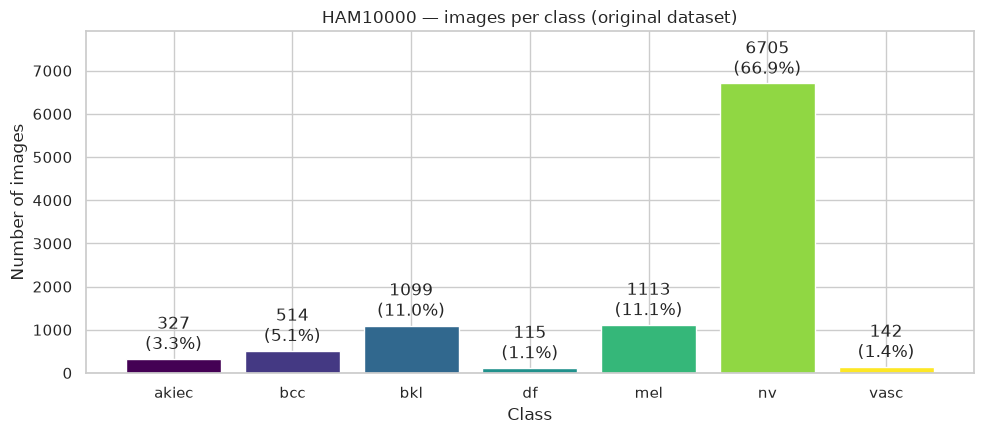

Imbalance ratio (largest / smallest class): 58 : 1


In [4]:
if meta is not None:
    counts = meta["dx"].value_counts().reindex(CLASSES)
    table = pd.DataFrame({"diagnosis": pd.Series(CLASS_INFO), "images": counts,
                          "share (%)": (100 * counts / counts.sum()).round(1)})
    table.loc["TOTAL"] = ["", counts.sum(), 100.0]
    display(table)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES])
    ax.bar_label(bars, labels=[f"{n}\n({100 * n / counts.sum():.1f}%)" for n in counts.values], padding=3)
    ax.set(title="HAM10000 — images per class (original dataset)", xlabel="Class", ylabel="Number of images",
           ylim=(0, counts.max() * 1.18))
    plt.tight_layout()
    plt.show()
    print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.0f} : 1")

### 3.2 How was each diagnosis confirmed? (`dx_type`)
The reliability of the label depends on how it was obtained. Histopathology is the gold standard; `follow_up` and `consensus` are weaker.

In [5]:
if meta is not None:
    ct = pd.crosstab(meta["dx"], meta["dx_type"]).reindex(CLASSES)
    display(ct)
    display((100 * ct.div(ct.sum(axis=1), axis=0)).round(1).add_suffix(" (%)"))

dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0,0,0,327
bcc,0,0,0,514
bkl,69,264,0,766
df,0,60,0,55
mel,0,0,0,1113
nv,0,503,3704,2498
vasc,0,75,0,67


dx_type,confocal (%),consensus (%),follow_up (%),histo (%)
dx,,,,
akiec,0.0,0.0,0.0,100.0
bcc,0.0,0.0,0.0,100.0
bkl,6.3,24.0,0.0,69.7
df,0.0,52.2,0.0,47.8
mel,0.0,0.0,0.0,100.0
nv,0.0,7.5,55.2,37.3
vasc,0.0,52.8,0.0,47.2


### 3.3 Age, sex and body site

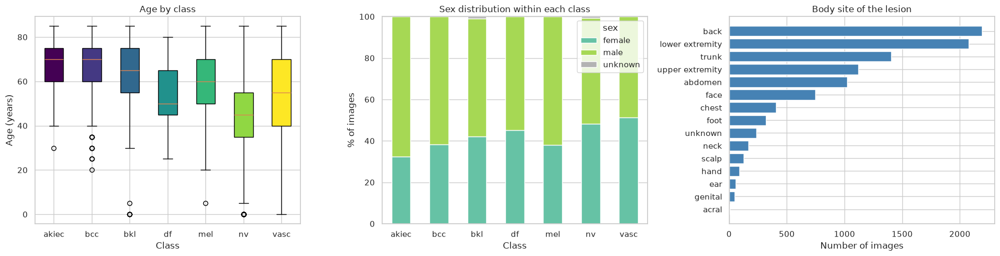

In [6]:
if meta is not None:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    # Age per class
    data = [meta.loc[meta["dx"] == c, "age"].dropna().values for c in CLASSES]
    bp = axes[0].boxplot(data, patch_artist=True)
    axes[0].set_xticklabels(CLASSES)
    for patch, c in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLORS[c])
    axes[0].set(title="Age by class", xlabel="Class", ylabel="Age (years)")

    # Sex per class (share inside each class)
    sex = pd.crosstab(meta["dx"], meta["sex"], normalize="index").reindex(CLASSES) * 100
    sex.plot.bar(stacked=True, ax=axes[1], rot=0, colormap="Set2")
    axes[1].set(title="Sex distribution within each class", xlabel="Class", ylabel="% of images")
    axes[1].legend(title="sex")

    # Body site
    loc_counts = meta["localization"].value_counts().sort_values()
    axes[2].barh(loc_counts.index, loc_counts.values, color="steelblue")
    axes[2].set(title="Body site of the lesion", xlabel="Number of images")
    plt.tight_layout()
    plt.show()

### 3.4 Several images per lesion
Many lesions were photographed more than once. This is the reason why the train/validation split must be done **by lesion** and not by image (section 4).

images per lesion,1,2,3,4,5,6
lesions,5514,1423,490,34,5,4


,lesions,images,share_with_several_images
dx,,,
akiec,228,327,0.338
bcc,327,514,0.465
bkl,727,1099,0.395
df,73,115,0.466
mel,614,1113,0.625
nv,5403,6705,0.183
vasc,98,142,0.347


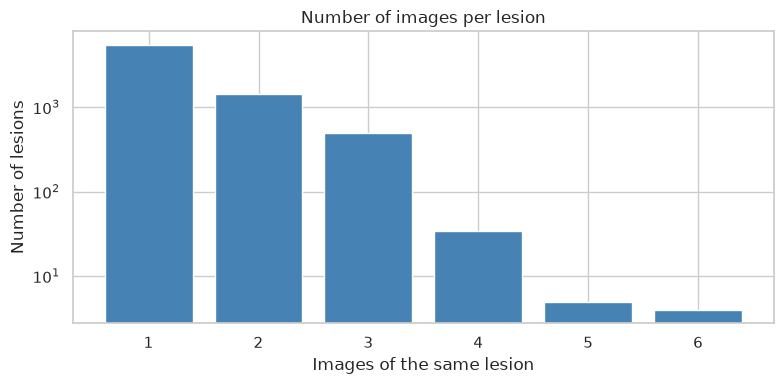

In [7]:
if meta is not None:
    lesions = meta.groupby("lesion_id").agg(n_images=("image_id", "size"), dx=("dx", "first"))
    per_lesion = lesions["n_images"].value_counts().sort_index().rename("lesions").to_frame()
    per_lesion.index.name = "images per lesion"
    display(per_lesion.T)

    by_class = lesions.groupby("dx").agg(lesions=("n_images", "size"), images=("n_images", "sum"),
                                         share_with_several_images=("n_images", lambda s: round(float((s > 1).mean()), 3)))
    display(by_class.reindex(CLASSES))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(per_lesion.index.astype(str), per_lesion["lesions"], color="steelblue")
    ax.set(title="Number of images per lesion", xlabel="Images of the same lesion", ylabel="Number of lesions")
    ax.set_yscale("log")
    plt.tight_layout()
    plt.show()

## 4. Train / validation organisation
The training script expects the images arranged as `Datasets/training/<class>/` and `Datasets/validation/<class>/`.

The split is **80 / 20, grouped by `lesion_id`** (`GroupShuffleSplit`, seed 42), so that no lesion appears in both sets. It is the same procedure used by `entrenamiento_binario_mel.py` (`--base-dir` option), so both give the same split.

> `organise_dataset` below is only needed the first time and does nothing if `Datasets/training` already exists. Set `ORGANIZE_DATASET = True` to run it.

In [8]:
ORGANIZE_DATASET = False   # True = build Datasets/ from the raw HAM10000 files (only the first time)


def organise_dataset(seed=42):
    import shutil
    from sklearn.model_selection import GroupShuffleSplit
    from tqdm.auto import tqdm

    if TRAIN_DIR.exists():
        print("Dataset already organised in", DATASET_DIR)
        return
    # Look for the images only in the raw image folders (NOT recursively in BASE_DIR, so the resized copies in
    # balancing/dataset_balanced, which have the same file names, can never be picked up by mistake).
    paths = {f.stem: f for d in IMAGE_DIRS if d.exists() for f in d.glob("*.jpg")}
    md_ = pd.read_csv(METADATA_CSV)
    md_["path"] = md_["image_id"].map(paths)
    print(f"Images found: {md_['path'].notna().sum()} of {len(md_)}")
    md_ = md_.dropna(subset=["path"]).reset_index(drop=True)
    assert len(md_) > 0, "No image found: check IMAGE_DIRS"

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_idx, val_idx = next(gss.split(md_, groups=md_["lesion_id"]))
    for split, idx in [("training", train_idx), ("validation", val_idx)]:
        for _, row in tqdm(md_.iloc[idx].iterrows(), total=len(idx), desc=split):
            dest = DATASET_DIR / split / row["dx"]
            dest.mkdir(parents=True, exist_ok=True)
            shutil.copy(row["path"], dest / row["path"].name)
    print("Done:", DATASET_DIR)


if ORGANIZE_DATASET:
    organise_dataset()

### 4.1 Class distribution in training and validation

,training,validation,validation share (%)
cls,,,
akiec,260.0,67.0,20.5
bcc,424.0,90.0,17.5
bkl,856.0,243.0,22.1
df,97.0,18.0,15.7
mel,877.0,236.0,21.2
nv,5369.0,1336.0,19.9
vasc,108.0,34.0,23.9
TOTAL,7991.0,2024.0,20.2


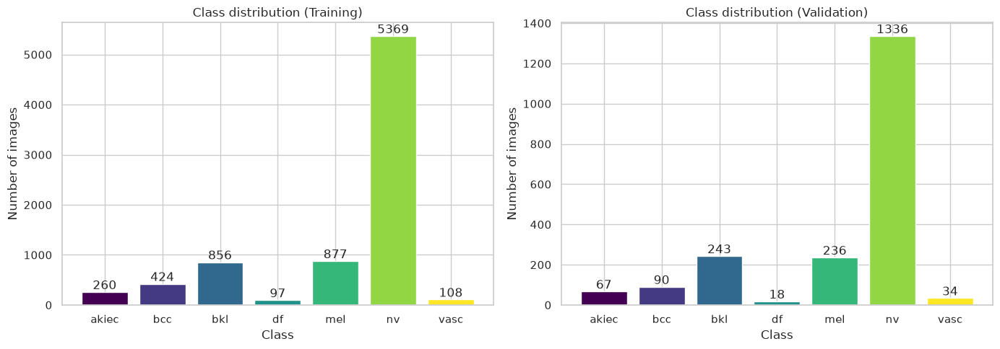

In [9]:
TRAIN_INV = list_images(TRAIN_DIR) if TRAIN_DIR.exists() else None
VAL_INV = list_images(VAL_DIR) if VAL_DIR.exists() else None

if TRAIN_INV is None or VAL_INV is None:
    print("[skipped] Datasets/training or Datasets/validation not found (see ORGANIZE_DATASET above).")
else:
    tr = TRAIN_INV["cls"].value_counts().reindex(CLASSES).fillna(0).astype(int)
    va = VAL_INV["cls"].value_counts().reindex(CLASSES).fillna(0).astype(int)
    split_table = pd.DataFrame({"training": tr, "validation": va})
    split_table["validation share (%)"] = (100 * va / (tr + va)).round(1)
    split_table.loc["TOTAL"] = [tr.sum(), va.sum(), round(100 * va.sum() / (tr.sum() + va.sum()), 1)]
    display(split_table)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, counts, title in zip(axes, [tr, va], ["Training", "Validation"]):
        bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES])
        ax.bar_label(bars)
        ax.set(title=f"Class distribution ({title})", xlabel="Class", ylabel="Number of images")
    plt.tight_layout()
    plt.show()

### 4.2 Sanity check: no lesion shared between training and validation

In [10]:
if TRAIN_INV is not None and VAL_INV is not None and meta is not None:
    id2lesion = meta.set_index("image_id")["lesion_id"]
    tr_les = set(TRAIN_INV["image_id"].map(id2lesion).dropna())
    va_les = set(VAL_INV["image_id"].map(id2lesion).dropna())
    shared = tr_les & va_les
    print(f"Lesions in training: {len(tr_les)} | in validation: {len(va_les)} | shared: {len(shared)}")
    print("OK: the split is clean." if not shared else "WARNING: some lesions appear in both sets (data leakage).")
else:
    print("[skipped] needs the metadata CSV and the training/validation folders.")

Lesions in training: 5976 | in validation: 1494 | shared: 0
OK: the split is clean.


## 5. Example images
A random sample of images of each class, to check visually that the data is correct and to get a feeling for how the classes look. Run the cell again to see other images (or change `seed`).

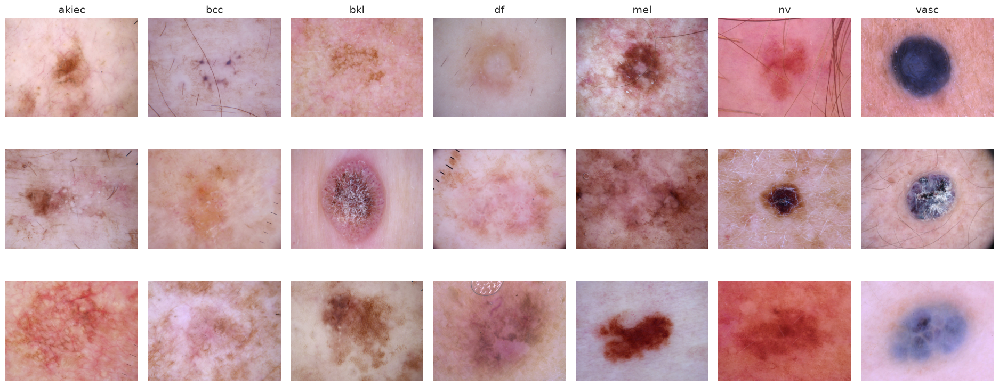

In [11]:
def build_image_index():
    # Index of the ORIGINAL images available: from Datasets/ if it exists, otherwise from the raw image folders.
    parts = []
    for split, folder, inv in (("training", TRAIN_DIR, TRAIN_INV), ("validation", VAL_DIR, VAL_INV)):
        if inv is not None:
            df = inv.copy()
            df["split"] = split
            df["path"] = [str(folder / c / f) for c, f in zip(df["cls"], df["file"])]
            parts.append(df)
    if parts:
        return pd.concat(parts, ignore_index=True)
    if meta is not None:
        paths = {f.stem: str(f) for d in IMAGE_DIRS if d.exists() for f in d.glob("*.jpg")}
        if paths:
            df = meta[["image_id", "dx"]].rename(columns={"dx": "cls"})
            df["path"] = df["image_id"].map(paths)
            df = df.dropna(subset=["path"]).copy()
            df["split"] = "raw"
            return df
    return None


IMAGE_INDEX = build_image_index()


def show_examples(n_per_class=3, seed=None):
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(n_per_class, len(CLASSES), figsize=(2.7 * len(CLASSES), 2.7 * n_per_class))
    axes = np.atleast_2d(axes).reshape(n_per_class, len(CLASSES))
    for j, c in enumerate(CLASSES):
        sub = IMAGE_INDEX[IMAGE_INDEX["cls"] == c]
        picks = sub.sample(min(n_per_class, len(sub)), random_state=rng) if len(sub) else sub
        for i in range(n_per_class):
            ax = axes[i, j]
            ax.axis("off")
            if i < len(picks):
                ax.imshow(read_rgb(picks.iloc[i]["path"]))
            if i == 0:
                ax.set_title(c, fontsize=14)
    plt.tight_layout()
    plt.show()


if IMAGE_INDEX is None:
    print("[skipped] no images found (check DATASET_DIR / IMAGE_DIRS).")
else:
    show_examples(n_per_class=3, seed=None)

## 6. Image preprocessing

Each preprocessing method is a named **step**, and a *pipeline* is a sequence of steps such as `('hair', 'cc', 'rgb')`. They are applied in the given order to the original image (≈ 600×450), **before** resizing. `pad` is applied just before resizing and `rgb` at the very end.

| Step | What it does | Why test it |
|---|---|---|
| `rgb` | Converts BGR (OpenCV's default) to RGB | ImageNet weights were trained on RGB images |
| `pad` | Adds black margins until the image is square instead of stretching it | Avoids distorting the lesion (photos are 4:3) |
| `hair` | Removes hair: a morphological *black-hat* finds thin dark structures and fills them by inpainting (simplified DullRazor) | Hair occludes the lesion. Limitation: may also erase small real dark structures |
| `cc` | Colour constancy (Shades of Gray) | Images come from different devices. Risk: skin/lesion colour is also information |
| `clahe` | Adaptive contrast equalisation on the lightness channel (LAB) | Highlights borders and pigmentation |
| `bright` | Gamma correction (0.7) that brightens the image | Dark images lose detail |
| `border` | If the corners are dark (dermatoscope vignette), crops the centre | The black background may be an irrelevant shortcut |
| `center` | Central crop (80%) | The lesion is usually in the centre; more effective resolution |
| `gray` | Grayscale | **Negative control**: measures how much the model relies on colour |

**Which of these does the binary training script use?** Only the basic ones: resize (`--img-size`, default 128), optional `--pad` and optional BGR→RGB (`--rgb`). The other steps come from the earlier preprocessing study and are documented here for completeness.

**Memory decision.** Arrays are kept as `uint8` (0–255) and normalised **inside** the model (EfficientNet already includes its own normalisation). As `float32`, the dataset at 224×224 would need ~6 GB; as `uint8` about 1.5 GB.

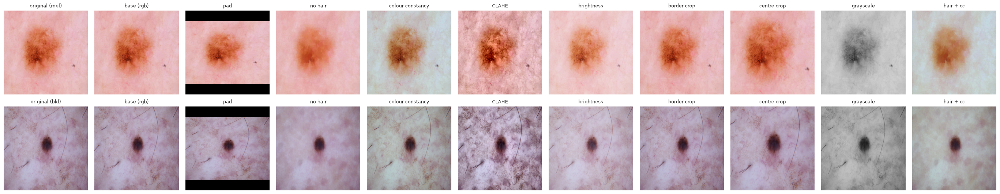

In [12]:
def remove_hair(img, thresh=10):
    # Simplified DullRazor: a black-hat transform detects thin dark structures (hair), then they are inpainted.
    # The kernel scales with the image size (~17 px for 600x450).
    h, w = img.shape[:2]
    k = max(3, int(max(h, w) / 35)) | 1
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    _, mask = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)
    mask = cv2.dilate(mask, np.ones((3, 3), np.uint8))
    return cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA)


def color_constancy(img, power=6):
    # Shades of Gray: estimate the illuminant colour (Minkowski norm) and correct each channel
    x = img.astype(np.float64)
    rgb = np.power(np.mean(np.power(x, power), axis=(0, 1)), 1.0 / power)
    rgb = rgb / np.sqrt(np.sum(rgb ** 2))
    gain = 1.0 / (np.sqrt(3) * rgb)
    return np.clip(x * gain, 0, 255).astype(np.uint8)


def clahe_lab(img, clip=2.0, tile=8):
    # CLAHE on the L (lightness) channel only, so colours are not distorted
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def brighten(img, gamma=0.7):
    table = (((np.arange(256) / 255.0) ** gamma) * 255).astype(np.uint8)   # gamma < 1 brightens
    return cv2.LUT(img, table)


def crop_center(img, frac=0.8):
    h, w = img.shape[:2]
    ch, cw = int(h * frac), int(w * frac)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return img[y0:y0 + ch, x0:x0 + cw]


def remove_border(img, dark=40, keep=0.65):
    # Acts only on images with a dark vignette (>= 3 dark corners): keeps the centre, free of black background
    h, w = img.shape[:2]
    s = max(8, int(0.08 * min(h, w)))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    corners = [gray[:s, :s], gray[:s, -s:], gray[-s:, :s], gray[-s:, -s:]]
    if sum(c.mean() < dark for c in corners) >= 3:
        return crop_center(img, keep)
    return img


def to_gray(img):
    return cv2.cvtColor(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)


STEP_FUNCS = {"hair": remove_hair, "cc": color_constancy, "clahe": clahe_lab, "bright": brighten,
              "border": remove_border, "center": crop_center, "gray": to_gray}
VALID_STEPS = set(STEP_FUNCS) | {"rgb", "pad"}


def load_image(path, img_size=128, steps=()):
    # Applies a pipeline to ONE image. Returns uint8, BGR unless 'rgb' is in steps (same logic as the training script).
    bad = [s for s in steps if s not in VALID_STEPS]
    if bad:
        raise ValueError(f"Unknown steps: {bad}. Valid: {sorted(VALID_STEPS)}")
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)   # BGR, uint8
    if img is None:
        return None
    for s in steps:
        if s in STEP_FUNCS:
            img = STEP_FUNCS[s](img)
    if "pad" in steps:   # make it square with black margins instead of stretching it
        h, w = img.shape[:2]
        side = max(h, w)
        top, left = (side - h) // 2, (side - w) // 2
        img = cv2.copyMakeBorder(img, top, side - h - top, left, side - w - left,
                                 cv2.BORDER_CONSTANT, value=(0, 0, 0))
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    if "rgb" in steps:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img


PIPELINES = {
    "base (rgb)":      ("rgb",),
    "pad":             ("pad", "rgb"),
    "no hair":         ("hair", "rgb"),
    "colour constancy": ("cc", "rgb"),
    "CLAHE":           ("clahe", "rgb"),
    "brightness":      ("bright", "rgb"),
    "border crop":     ("border", "rgb"),
    "centre crop":     ("center", "rgb"),
    "grayscale":       ("gray", "rgb"),
    "hair + cc":       ("hair", "cc", "rgb"),
}


def show_pipelines(pipelines, classes=("mel", "bkl"), size=300, seed=None):
    # Same image(s) before and after each pipeline: confirms every step does what is expected
    rng = np.random.RandomState(seed)
    names = ["original"] + list(pipelines)
    fig, axes = plt.subplots(len(classes), len(names), figsize=(2.5 * len(names), 2.8 * len(classes)))
    axes = np.atleast_2d(axes).reshape(len(classes), len(names))
    for r, c in enumerate(classes):
        sub = IMAGE_INDEX[IMAGE_INDEX["cls"] == c]
        path = sub.iloc[rng.randint(len(sub))]["path"]
        for k, name in enumerate(names):
            if name == "original":
                img, title = cv2.resize(read_rgb(path), (size, size), interpolation=cv2.INTER_AREA), f"original ({c})"
            else:
                steps = pipelines[name]
                img = load_image(path, size, steps)
                img = img if "rgb" in steps else img[..., ::-1]
                title = name
            axes[r, k].imshow(img)
            axes[r, k].axis("off")
            axes[r, k].set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


if IMAGE_INDEX is None:
    print("[skipped] no images found.")
else:
    show_pipelines(PIPELINES, classes=("mel", "bkl"))

## **7. Class balancing analysis**

`balance_dataset.py` builds a balanced dataset in `balancing/dataset_balanced/<class>/` with a fixed number of images per class (`TARGET_COUNT = 1000`, i.e. 7,000 images in total):

| Situation | What the script does |
|---|---|
| Class with **≥ 1,000** images (`nv`, `mel`, `bkl`) | **Random undersampling** to 1,000 images (`random_state=42`). Images are resized to 224×224. |
| Class with **< 1,000** images (`akiec`, `bcc`, `df`, `vasc`) | **All originals are kept** (resized to 224×224) and **augmented copies** are generated until reaching 1,000. Augmented files are named `<image_id>_aug_<n>.jpg`. |

**Augmentation applied to the copies:** random orthogonal rotation (0°, 90°, 180°, 270°), removal of black borders, random horizontal and vertical flips (p = 0.5), `ColorJitter` (brightness, contrast and saturation ± 15%) and a final resize to 224×224.

> **Important.** The script reads the whole `HAM10000_metadata.csv`; it does **not** distinguish between training and validation lesions. Whether this causes data leakage depends on how the balanced folder is later used. Section 7.5 checks it explicitly.

The subsections below inspect the result: counts before/after (7.1), how much of each class is real vs. synthetic (7.2), what the augmentations look like (7.3), whether image properties are consistent (7.4) and the leakage check (7.5).

### 7.1 Class counts: before and after balancing

,original_total,balanced_total,augmented,kept_originals,action,aug_copies_per_original
cls,,,,,,
akiec,327,1000,673,327,oversampled + augmented,2.06
bcc,514,1000,486,514,oversampled + augmented,0.95
bkl,1099,1000,0,1000,undersampled,0.00
df,115,1000,885,115,oversampled + augmented,7.70
mel,1113,1000,0,1000,undersampled,0.00
nv,6705,1000,0,1000,undersampled,0.00
vasc,142,1000,858,142,oversampled + augmented,6.04


Total images in the balanced dataset: 7000
Real (resized) images: 4098 | augmented copies: 2902 (41.5% of the dataset)


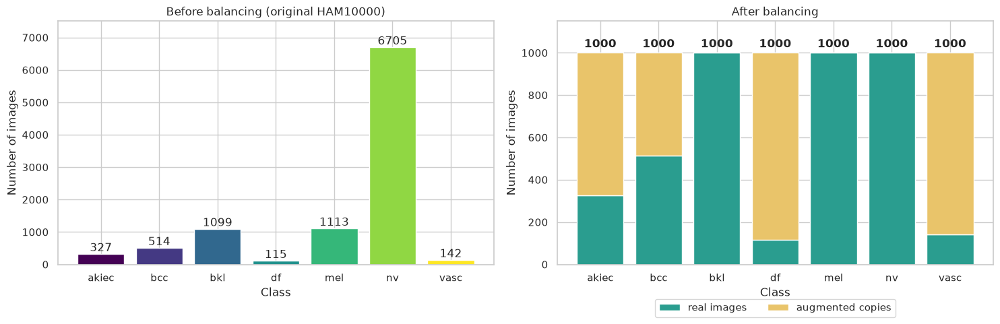

In [13]:
BAL = list_images(BALANCED_DIR) if BALANCED_DIR.exists() else None

if BAL is None:
    print(f"[skipped] balanced dataset not found: {BALANCED_DIR}")
else:
    inv = BAL.groupby("cls").agg(balanced_total=("file", "size"), augmented=("augmented", "sum")).reindex(CLASSES)
    inv["kept_originals"] = inv["balanced_total"] - inv["augmented"]
    if meta is not None:
        inv.insert(0, "original_total", meta["dx"].value_counts().reindex(CLASSES))
        inv["action"] = np.where(inv["original_total"] > inv["balanced_total"], "undersampled",
                         np.where(inv["augmented"] > 0, "oversampled + augmented", "unchanged"))
    inv["aug_copies_per_original"] = (inv["augmented"] / inv["kept_originals"]).round(2)
    display(inv)
    print(f"Total images in the balanced dataset: {int(inv['balanced_total'].sum())}")
    print(f"Real (resized) images: {int(inv['kept_originals'].sum())} | augmented copies: {int(inv['augmented'].sum())} "
          f"({100 * inv['augmented'].sum() / inv['balanced_total'].sum():.1f}% of the dataset)")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    if meta is not None:
        orig = inv["original_total"]
        bars = axes[0].bar(CLASSES, orig.values, color=[CLASS_COLORS[c] for c in CLASSES])
        axes[0].bar_label(bars)
        axes[0].set(title="Before balancing (original HAM10000)", xlabel="Class", ylabel="Number of images",
                    ylim=(0, orig.max() * 1.12))
    else:
        axes[0].axis("off")
    axes[1].bar(CLASSES, inv["kept_originals"], color="#2a9d8f", label="real images")
    axes[1].bar(CLASSES, inv["augmented"], bottom=inv["kept_originals"], color="#e9c46a", label="augmented copies")
    for i, t in enumerate(inv["balanced_total"]):
        axes[1].annotate(f"{int(t)}", (i, t), ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                         fontweight="bold")
    axes[1].set(title="After balancing", xlabel="Class", ylabel="Number of images",
                ylim=(0, inv["balanced_total"].max() * 1.15))
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    plt.tight_layout()
    plt.show()

### 7.2 Real diversity behind the 1,000 images per class
A perfectly flat histogram can be misleading: in the oversampled classes many images are augmented copies of the same few lesions. The number of **distinct lesions** per class is a better measure of how much independent information the model actually sees.

,images,distinct_source_images,distinct_lesions,images_per_lesion
cls,,,,
akiec,1000,327,228,4.4
bcc,1000,514,327,3.1
bkl,1000,1000,691,1.4
df,1000,115,73,13.7
mel,1000,1000,586,1.7
nv,1000,1000,977,1.0
vasc,1000,142,98,10.2


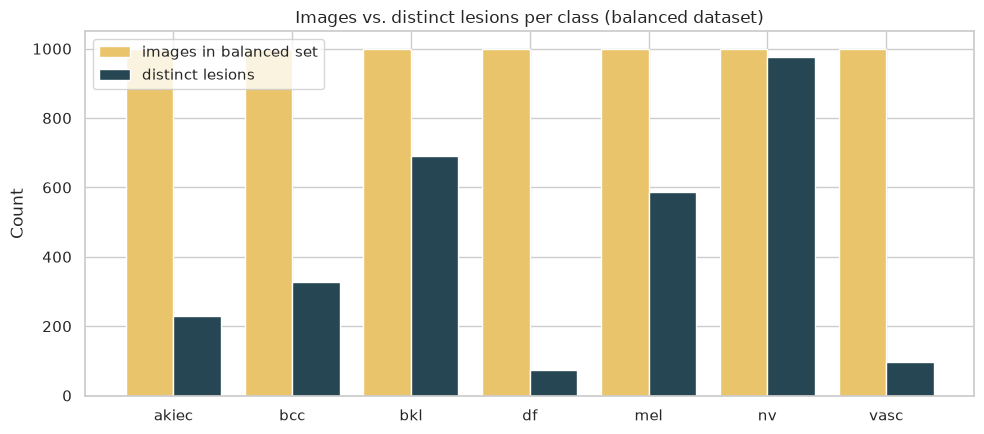

In [14]:
if BAL is not None and meta is not None:
    id2lesion = meta.set_index("image_id")["lesion_id"]
    BAL["lesion_id"] = BAL["image_id"].map(id2lesion)
    div = BAL.groupby("cls").agg(images=("file", "size"), distinct_source_images=("image_id", "nunique"),
                                 distinct_lesions=("lesion_id", "nunique")).reindex(CLASSES)
    div["images_per_lesion"] = (div["images"] / div["distinct_lesions"]).round(1)
    display(div)

    x = np.arange(len(CLASSES))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x - 0.2, div["images"], width=0.4, label="images in balanced set", color="#e9c46a")
    ax.bar(x + 0.2, div["distinct_lesions"], width=0.4, label="distinct lesions", color="#264653")
    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES)
    ax.set(title="Images vs. distinct lesions per class (balanced dataset)", ylabel="Count")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("[skipped] needs the balanced dataset and the metadata CSV.")

### 7.3 What do the augmented images look like?
Each row is one source image: the real (resized) image followed by some of its augmented copies. Change `cls` to inspect other oversampled classes (`akiec`, `bcc`, `df`, `vasc`).

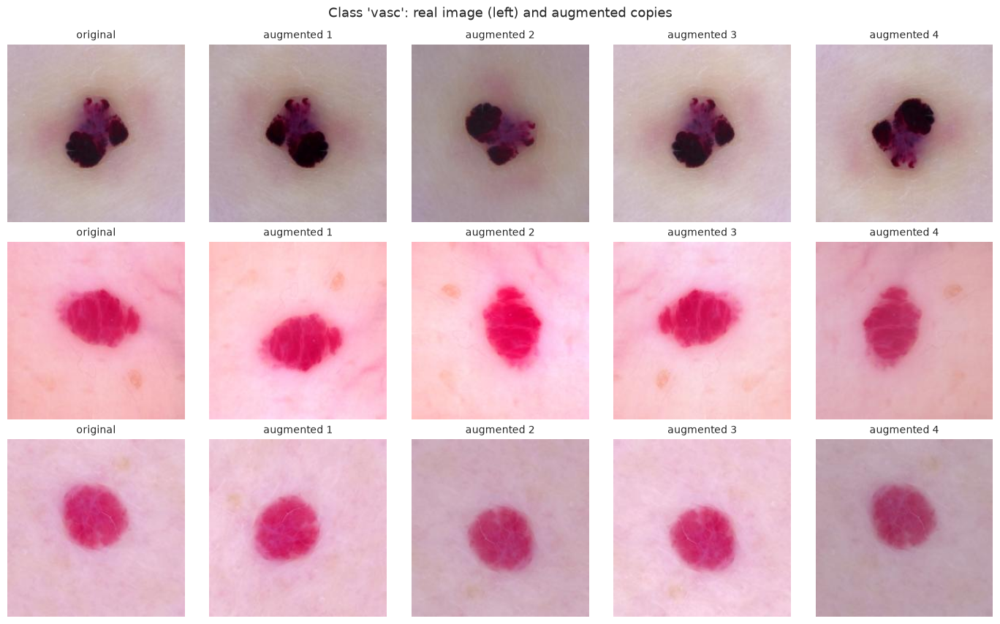

In [15]:
def show_augmentation_examples(cls="vasc", n_sources=3, n_aug=4, seed=SEED):
    rng = random.Random(seed)
    sub = BAL[BAL["cls"] == cls]
    aug = sub[sub["augmented"]]
    if aug.empty:
        print(f"No augmented images for '{cls}' (the class was undersampled or left unchanged).")
        return
    n_per_source = aug.groupby("image_id").size()
    cands = n_per_source[n_per_source >= min(n_aug, int(n_per_source.max()))].index.tolist()
    sources = rng.sample(cands, min(n_sources, len(cands)))
    fig, axes = plt.subplots(len(sources), n_aug + 1, figsize=(2.8 * (n_aug + 1), 2.9 * len(sources)))
    axes = np.atleast_2d(axes).reshape(len(sources), n_aug + 1)
    for r, sid in enumerate(sources):
        files = [f"{sid}.jpg"] + sorted(aug.loc[aug["image_id"] == sid, "file"])[:n_aug]
        for k in range(n_aug + 1):
            ax = axes[r, k]
            ax.axis("off")
            if k < len(files) and (BALANCED_DIR / cls / files[k]).exists():
                ax.imshow(read_rgb(BALANCED_DIR / cls / files[k]))
                ax.set_title("original" if k == 0 else f"augmented {k}", fontsize=10)
    fig.suptitle(f"Class '{cls}': real image (left) and augmented copies", fontsize=13)
    plt.tight_layout()
    plt.show()


if BAL is not None:
    show_augmentation_examples("vasc")

### 7.4 Consistency checks: size and colour statistics
The script outputs 224×224 images. We check this on a random sample and compare the brightness of real vs. augmented images, since `ColorJitter` changes colour on the copies only (colour is clinically relevant information, so it is worth knowing how much it shifts).

Image sizes found in the sample (width x height):


,,images
width,height,
224,224,1100


R           G           B  brightness
cls   type                                                     
akiec augmented  194.100006  145.800003  152.300003  164.100006
      real       197.600006  148.500000  154.899994  167.000000
bcc   augmented  194.399994  155.000000  162.100006  170.500000
      real       196.800003  156.399994  162.800003  172.000000
bkl   real       178.800003  139.699997  148.199997  155.600006
df    augmented  197.600006  150.899994  160.000000  169.500000
      real       199.399994  150.600006  159.100006  169.699997
mel   real       176.100006  138.500000  144.699997  153.100006
nv    real       200.399994  134.399994  138.199997  157.699997
vasc  augmented  198.300003  149.300003  162.500000  170.000000
      real       198.500000  150.500000  164.399994  171.100006

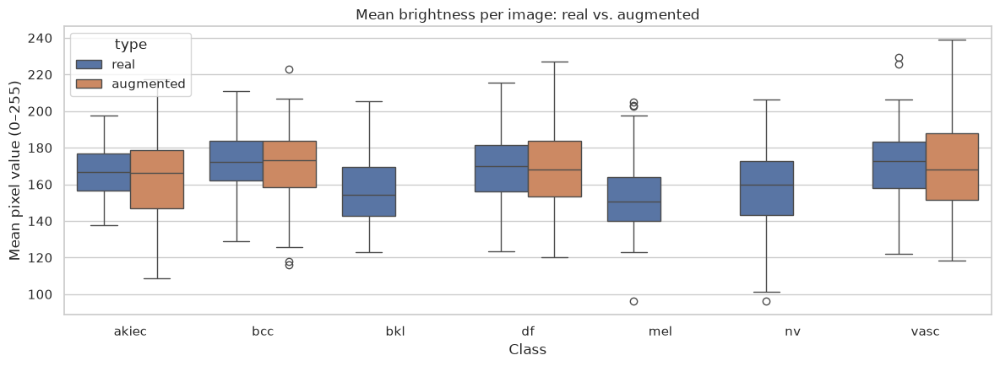

In [16]:
def sample_image_stats(n_per_group=100, seed=SEED):
    rows = []
    for (cls, aug), g in BAL.groupby(["cls", "augmented"]):
        g = g.sample(min(n_per_group, len(g)), random_state=seed)
        for f in g["file"]:
            img = Image.open(BALANCED_DIR / cls / f).convert("RGB")
            a = np.asarray(img, dtype=np.float32)
            rows.append(dict(cls=cls, type="augmented" if aug else "real", width=img.width, height=img.height,
                             R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(), brightness=a.mean()))
    return pd.DataFrame(rows)


if BAL is not None:
    stats = sample_image_stats()
    print("Image sizes found in the sample (width x height):")
    display(stats.groupby(["width", "height"]).size().rename("images").to_frame())

    summary = stats.groupby(["cls", "type"])[["R", "G", "B", "brightness"]].mean().round(1)
    display(summary)

    fig, ax = plt.subplots(figsize=(12, 4.5))
    sns.boxplot(data=stats, x="cls", y="brightness", hue="type", order=CLASSES, ax=ax)
    ax.set(title="Mean brightness per image: real vs. augmented", xlabel="Class", ylabel="Mean pixel value (0–255)")
    plt.tight_layout()
    plt.show()

### 7.5 Data-leakage check against the validation set
**Question:** if the balanced dataset is used for training and the validation images come from the original split (`Datasets/validation`), do the training images include (copies of) validation lesions?

For each class we count how many images of the balanced set — augmented copies included — come from an image or a lesion that is in the validation set. Any value above zero means the model has seen the validation lesions during training and **the validation metrics are optimistic**.

The validation images are taken from `Datasets/validation` or, if it is not available, from the predictions file of the training run.

In [17]:
def get_val_images():
    if VAL_INV is not None:
        return VAL_INV[["image_id", "cls"]].copy(), f"folder {VAL_DIR}"
    rd = RUN_DIR or find_run_dir()
    if rd is not None and (Path(rd) / "predicciones_validacion.csv").exists():
        p = pd.read_csv(Path(rd) / "predicciones_validacion.csv")
        return pd.DataFrame({"image_id": p["archivo"].map(lambda s: Path(s).stem), "cls": p["clase_original"]}), \
            f"predictions of run {Path(rd).name}"
    return None, None


val_df, val_src = get_val_images()

if BAL is None or val_df is None or meta is None:
    print("[skipped] needs the balanced dataset, the metadata CSV and a validation set (folder or run predictions).")
else:
    id2lesion = meta.set_index("image_id")["lesion_id"]
    val_df["lesion_id"] = val_df["image_id"].map(id2lesion)
    leak = BAL[["cls", "image_id", "augmented"]].copy()
    leak["lesion_id"] = leak["image_id"].map(id2lesion)
    leak["from_val_image"] = leak["image_id"].isin(set(val_df["image_id"]))
    leak["from_val_lesion"] = leak["lesion_id"].isin(set(val_df["lesion_id"].dropna()))

    by_cls = leak.groupby("cls").agg(balanced_images=("image_id", "size"),
                                     from_val_images=("from_val_image", "sum"),
                                     from_val_lesions=("from_val_lesion", "sum")).reindex(CLASSES)
    by_cls["from_val_lesions (%)"] = (100 * by_cls["from_val_lesions"] / by_cls["balanced_images"]).round(1)
    by_cls.loc["TOTAL"] = [by_cls["balanced_images"].sum(), by_cls["from_val_images"].sum(),
                           by_cls["from_val_lesions"].sum(),
                           round(100 * by_cls["from_val_lesions"].sum() / by_cls["balanced_images"].sum(), 1)]
    print(f"Validation images taken from: {val_src} ({len(val_df)} images, {val_df['lesion_id'].nunique()} lesions)")
    display(by_cls.astype({"balanced_images": int, "from_val_images": int, "from_val_lesions": int}))

    covered = val_df["image_id"].isin(set(leak["image_id"])).mean()
    print(f"{100 * covered:.1f}% of the validation images appear (as source images) in the balanced dataset.")
    if by_cls.loc["TOTAL", "from_val_lesions"] > 0:
        print("\nWARNING: the balanced dataset contains validation lesions. If it was used for training, the validation "
              "metrics are inflated. Build the balanced set from the TRAINING lesions only (and keep validation untouched).")
    else:
        print("\nOK: no validation lesion appears in the balanced dataset.")

Validation images taken from: folder Datasets/validation (2024 images, 1494 lesions)


,balanced_images,from_val_images,from_val_lesions,from_val_lesions (%)
cls,,,,
akiec,1000,207,207,20.7
bcc,1000,174,174,17.4
bkl,1000,225,225,22.5
df,1000,158,158,15.8
mel,1000,209,209,20.9
nv,1000,210,210,21.0
vasc,1000,238,238,23.8
TOTAL,7000,1421,1421,20.3


42.1% of the validation images appear (as source images) in the balanced dataset.



## **8. Training results (binary melanoma classifier)**

`entrenamiento_binario_mel.py` trains **stage 1 of the hierarchical approach**: a binary classifier *melanoma (1) vs. non-melanoma (0)* on top of an **EfficientNet** (B0 or B4, ImageNet weights) with the head `GlobalMaxPool → Dense(256) → BatchNorm → Dropout(0.5) → Dense(1, sigmoid)`.

Training has **two phases**:
1. **Head** — the backbone is frozen and only the new head is trained.
2. **Fine-tuning** — the last `--ft-layers` backbone layers are unfrozen (BatchNorm layers stay frozen) and trained with a much lower learning rate.

Both phases use `EarlyStopping` on `val_loss` (patience 5, best weights restored) and `ReduceLROnPlateau` (×0.3, patience 2). After training, the **decision threshold** on P(melanoma) is chosen on the validation set (`f1`: maximises the F1 of `mel`; `sensitivity`: the highest threshold that still reaches a minimum sensitivity; or a fixed number).

Each run writes a folder `runs/<name>_<timestamp>/` with `historial_epocas.csv` (per-epoch metrics), `predicciones_validacion.csv` (P(mel) per validation image), `metricas.json` (configuration, phases and final metrics) and `resumen_entrenamiento.txt`. This section reads those files.

**Terminology.** *Sensitivity* (= recall of `mel`) is the share of melanomas that are detected; *specificity* is the share of non-melanomas correctly left alone; *precision* is the share of "melanoma" alerts that are real melanomas; *AUC* measures how well the model ranks melanomas above non-melanomas regardless of the threshold.

### 8.1 Load the run
By default the most recent run in `RUNS_DIR` is used; set `RUN_DIR` in section 1 to choose a specific one.

In [18]:
def load_run(run_dir):
    rd = Path(run_dir)
    metrics = json.loads((rd / "metricas.json").read_text()) if (rd / "metricas.json").exists() else {}
    run = dict(
        dir=rd,
        hist=pd.read_csv(rd / "historial_epocas.csv"),
        preds=pd.read_csv(rd / "predicciones_validacion.csv") if (rd / "predicciones_validacion.csv").exists() else None,
        metrics=metrics,
        cfg=metrics.get("config", {}),
        phases=metrics.get("fases", []),
    )
    run["thr"] = float(metrics.get("evaluacion", {}).get("thr", 0.5))
    if run["preds"] is not None:
        run["preds"]["pred"] = (run["preds"]["p_mel"] >= run["thr"]).astype(int)
    return run


_rd = Path(RUN_DIR) if RUN_DIR else find_run_dir()
RUN = load_run(_rd) if _rd is not None else None

if RUN is None:
    print(f"[skipped] no run found in {RUNS_DIR} (a run folder must contain historial_epocas.csv).")
else:
    all_runs = sorted([d for d in Path(RUNS_DIR).iterdir() if d.is_dir() and (d / "historial_epocas.csv").exists()],
                      key=lambda d: d.stat().st_mtime)
    print("Runs available:", [d.name for d in all_runs])
    print("Analysing run :", RUN["dir"].name)
    if RUN["preds"] is None:
        print("NOTE: predicciones_validacion.csv is missing, so the evaluation sections (8.4 onwards) will be skipped.")

Runs available: ['B1_binario_B4_128_20261009_171524']
Analysing run : B1_binario_B4_128_20261009_171524


### 8.2 Run summary: configuration, data and phases

In [19]:
def report_sections(run_dir):
    # Splits resumen_entrenamiento.txt (written by the script) into {section title: text}
    p = Path(run_dir) / "resumen_entrenamiento.txt"
    if not p.exists():
        return {}
    parts = re.split(r"={80,}", p.read_text(encoding="utf-8"))
    return {parts[i].strip(): parts[i + 1].strip("\n") for i in range(1, len(parts) - 1, 2)}


def show_run_summary(run):
    cfg = run["cfg"]
    keys = ["name", "variant", "img_size", "rgb", "pad", "augment", "class_weights", "epochs_head", "fine_tune",
            "epochs_ft", "ft_layers", "head_lr", "ft_lr", "batch_size", "seed", "thr_mode", "min_sensitivity",
            "dataset_dir"]
    if cfg:
        print("Configuration")
        display(pd.Series({k: cfg[k] for k in keys if k in cfg}, name="value").to_frame())

    ph = pd.DataFrame(run["phases"])
    if not ph.empty:
        ph = ph.rename(columns={"fase": "phase", "epocas_max": "max_epochs", "epocas_ejecutadas": "epochs_run",
                                "early_stopping": "early_stopped", "mejor_epoca": "best_epoch",
                                "mejor_val_loss": "best_val_loss", "lr_inicial": "lr_start", "lr_final": "lr_end"})
        ph["minutes"] = (ph["segundos"] / 60).round(1)
        print("Phases")
        display(ph.drop(columns=["segundos"]))
        print(f"Total training time: {ph['minutes'].sum():.1f} min | epochs run: {int(ph['epochs_run'].sum())}")

    sections = report_sections(run["dir"])
    for title, body in sections.items():
        if title.startswith("4.") or title.startswith("9."):
            print("\n" + "=" * 70 + f"\n{title} (from resumen_entrenamiento.txt)\n" + "=" * 70)
            print(body)


if RUN is not None:
    show_run_summary(RUN)

Configuration


,value
name,B1_binario_B4_128
variant,B4
img_size,128
rgb,True
pad,False
augment,True
class_weights,sqrt
epochs_head,15
fine_tune,True
epochs_ft,15


Phases


,phase,max_epochs,epochs_run,early_stopped,best_epoch,best_val_loss,lr_start,lr_end,minutes
0,fase1_cabeza,15,8,True,3,0.381026,0.00050,4.500000e-05,1.6
1,fase2_finetuning,15,15,False,13,0.335924,0.00001,9.000000e-07,3.4


Total training time: 5.0 min | epochs run: 23

4. DATOS (from resumen_entrenamiento.txt)
Carpeta de entrenamiento          : Datasets/training
Carpeta de validación             : Datasets/validation
Clases (orden alfabético)         : akiec, bcc, bkl, df, mel, nv, vasc

Imágenes por clase en disco (antes de cargar):
clase  entrenamiento  validacion
akiec            260          67
  bcc            424          90
  bkl            856         243
   df             97          18
  mel            877         236
   nv           5369        1336
 vasc            108          34

Imágenes cargadas (train / val)   : 7991 / 2024
Imágenes ilegibles omitidas       : train=0, val=0
Melanomas  train                  : 877  (11.0 %)
Melanomas  val                    : 236  (11.7 %)
No-melanoma train / val           : 7114 / 1788
Forma X_train / dtype             : (7991, 128, 128, 3) / uint8
Memoria de los arrays             : 492 MB
Tiempo de carga                   : 00:00:29
Pesos de clase (mo

### 8.3 Training curves
Dashed grey lines separate the two phases and the star marks the best epoch of each phase (lowest `val_loss`). The last panel shows the learning rate (log scale); drops inside a phase are `ReduceLROnPlateau` events.

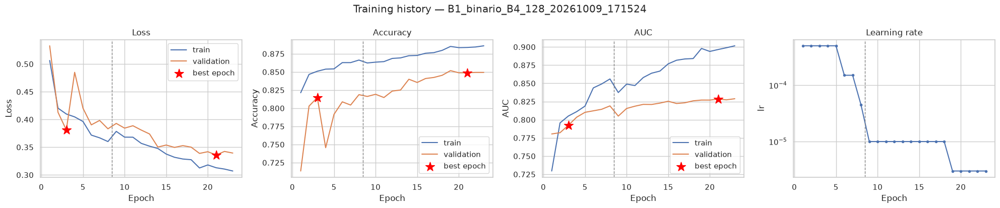

In [20]:
def plot_training_curves(run):
    h = run["hist"]
    panels = [(c, l) for c, l in [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]
              if c in h.columns and f"val_{c}" in h.columns]
    fig, axes = plt.subplots(1, len(panels) + 1, figsize=(5 * (len(panels) + 1), 4.2))
    boundaries = h.index[h["fase"] != h["fase"].shift()].tolist()[1:]
    best = h.loc[h.groupby("fase")["val_loss"].idxmin()]
    for ax, (col, label) in zip(axes, panels):
        ax.plot(h["epoca"], h[col], label="train")
        ax.plot(h["epoca"], h[f"val_{col}"], label="validation")
        ax.scatter(best["epoca"], best[f"val_{col}"], marker="*", s=180, color="red", zorder=3, label="best epoch")
        for b in boundaries:
            ax.axvline(h.loc[b, "epoca"] - 0.5, color="gray", ls="--", lw=1)
        ax.set(title=label, xlabel="Epoch", ylabel=label)
        ax.legend()
    if "lr" in h.columns:
        axes[-1].semilogy(h["epoca"], h["lr"], marker="o", ms=3)
        for b in boundaries:
            axes[-1].axvline(h.loc[b, "epoca"] - 0.5, color="gray", ls="--", lw=1)
        axes[-1].set(title="Learning rate", xlabel="Epoch", ylabel="lr")
    fig.suptitle(f"Training history — {run['dir'].name}")
    plt.tight_layout()
    plt.show()


if RUN is not None:
    plot_training_curves(RUN)

### 8.4 Generalisation gap at the best epoch
The gap between training and validation metrics at the best epoch of each phase is a quick indicator of overfitting. The script itself flags an AUC gap above 0.10.

In [21]:
def gap_table(run):
    h = run["hist"]
    best = h.loc[h.groupby("fase")["val_loss"].idxmin()].copy()
    cols = {"fase": "phase", "epoca": "epoch", "loss": "train_loss", "val_loss": "val_loss",
            "auc": "train_auc", "val_auc": "val_auc", "accuracy": "train_acc", "val_accuracy": "val_acc"}
    out = best[[c for c in cols if c in best.columns]].rename(columns=cols)
    if {"train_auc", "val_auc"} <= set(out.columns):
        out["auc_gap"] = out["train_auc"] - out["val_auc"]
    if {"train_loss", "val_loss"} <= set(out.columns):
        out["loss_gap"] = out["val_loss"] - out["train_loss"]
    return out.round(4).reset_index(drop=True)


if RUN is not None:
    g = gap_table(RUN)
    display(g)
    if "auc_gap" in g.columns and (g["auc_gap"] > 0.10).any():
        print("Possible overfitting: train AUC exceeds validation AUC by more than 0.10 in at least one phase.")

,phase,epoch,train_loss,val_loss,train_auc,val_auc,train_acc,val_acc,auc_gap,loss_gap
0,fase1_cabeza,3,0.4098,0.3810,0.8051,0.7924,0.8510,0.8147,0.0127,-0.0288
1,fase2_finetuning,21,0.3129,0.3359,0.8965,0.8283,0.8837,0.8488,0.0681,0.0230


### 8.5 Validation performance at the chosen threshold
ROC and Precision–Recall curves are threshold-independent; the red dot marks the operating point actually used. The confusion matrix shows counts and, in brackets, the share of each true class.

,thr,sensitivity,specificity,precision,f1,balanced_acc,accuracy,tp,fp,fn,tn
chosen threshold (0.44),0.44,0.619,0.866,0.378,0.469,0.742,0.837,146.0,240.0,90.0,1548.0
threshold 0.50,0.50,0.513,0.893,0.388,0.442,0.703,0.849,121.0,191.0,115.0,1597.0


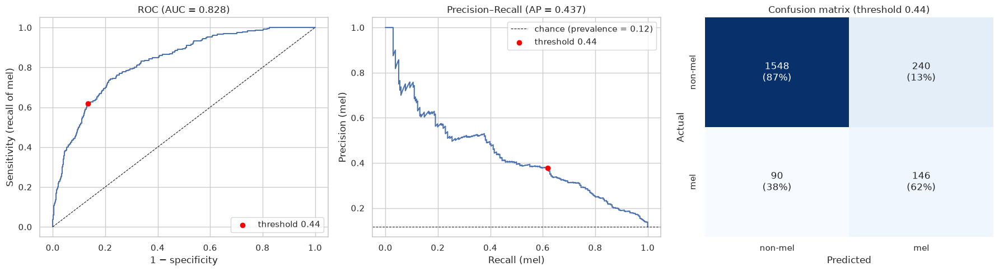

Validation set: 2024 images, 236 melanomas (11.7%) and 1788 non-melanomas.
At threshold 0.44: 146 of 236 melanomas detected (sensitivity 0.619); 240 of 1788 non-melanomas wrongly flagged (specificity 0.866); precision 0.378.


In [22]:
def binary_metrics(y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) > 0 else 0.0
    return dict(thr=float(thr), sensitivity=sens, specificity=spec, precision=prec, f1=f1,
                balanced_acc=(sens + spec) / 2, accuracy=(tp + tn) / len(y), tp=tp, fp=fp, fn=fn, tn=tn)


def evaluation_table(run):
    y, p = run["preds"]["y_real_mel"].values, run["preds"]["p_mel"].values
    rows = {f"chosen threshold ({run['thr']:.2f})": binary_metrics(y, p, run["thr"]),
            "threshold 0.50": binary_metrics(y, p, 0.5)}
    return pd.DataFrame(rows).T


def plot_evaluation(run):
    y, p, thr = run["preds"]["y_real_mel"].values, run["preds"]["p_mel"].values, run["thr"]
    m = binary_metrics(y, p, thr)
    fpr, tpr, _ = roc_curve(y, p)
    prec, rec, _ = precision_recall_curve(y, p)
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    cm_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(fpr, tpr)
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].scatter([1 - m["specificity"]], [m["sensitivity"]], color="red", zorder=3, label=f"threshold {thr:.2f}")
    axes[0].set(xlabel="1 − specificity", ylabel="Sensitivity (recall of mel)",
                title=f"ROC (AUC = {roc_auc_score(y, p):.3f})")
    axes[0].legend(loc="lower right")

    axes[1].plot(rec, prec)
    axes[1].axhline(y.mean(), color="k", ls="--", lw=0.8, label=f"chance (prevalence = {y.mean():.2f})")
    axes[1].scatter([m["sensitivity"]], [m["precision"]], color="red", zorder=3, label=f"threshold {thr:.2f}")
    axes[1].set(xlabel="Recall (mel)", ylabel="Precision (mel)",
                title=f"Precision–Recall (AP = {average_precision_score(y, p):.3f})")
    axes[1].legend(loc="upper right")

    labels = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=axes[2],
                xticklabels=["non-mel", "mel"], yticklabels=["non-mel", "mel"])
    axes[2].set(xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix (threshold {thr:.2f})")
    plt.tight_layout()
    plt.show()

    print(f"Validation set: {len(y)} images, {int(y.sum())} melanomas ({100 * y.mean():.1f}%) and {int((1 - y).sum())} non-melanomas.")
    print(f"At threshold {thr:.2f}: {m['tp']} of {m['tp'] + m['fn']} melanomas detected "
          f"(sensitivity {m['sensitivity']:.3f}); {m['fp']} of {m['tn'] + m['fp']} non-melanomas wrongly flagged "
          f"(specificity {m['specificity']:.3f}); precision {m['precision']:.3f}.")


if RUN is not None and RUN["preds"] is not None:
    display(evaluation_table(RUN).round(3))
    plot_evaluation(RUN)
elif RUN is not None:
    print("[skipped] predicciones_validacion.csv not found in the run folder.")

### 8.6 Threshold analysis: sensitivity vs. false alarms
The threshold converts P(melanoma) into a yes/no decision and sets the balance between missed melanomas and false alarms. For a screening-type use, the sensitivity-oriented thresholds (bottom table) are the relevant ones: they show what the model *costs* in false alarms for a given detection rate.

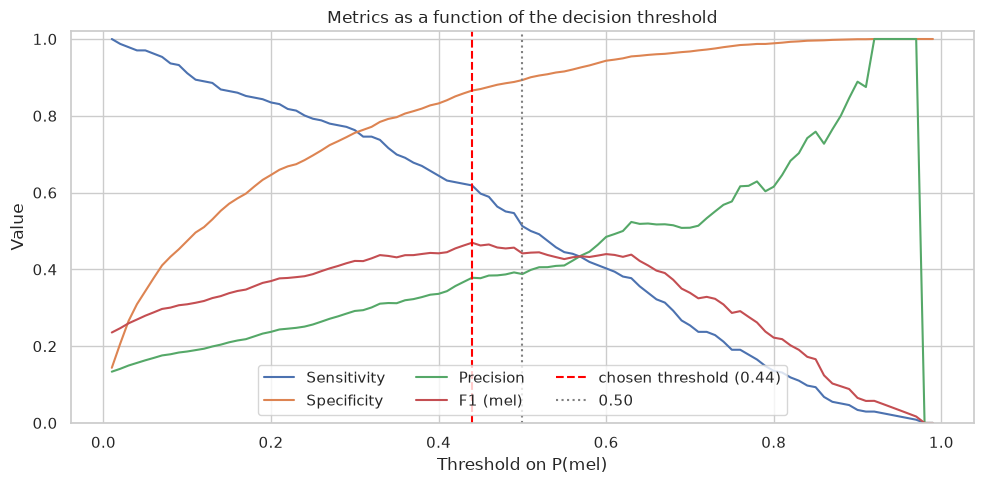

Selected thresholds


,thr,sensitivity,specificity,precision,f1,fn,fp
0,0.1,0.911,0.474,0.186,0.309,21,940
1,0.2,0.835,0.646,0.237,0.370,39,633
2,0.3,0.763,0.756,0.292,0.422,56,437
3,0.4,0.644,0.832,0.336,0.442,84,300
4,0.5,0.513,0.893,0.388,0.442,115,191
5,0.6,0.403,0.944,0.485,0.440,141,101
6,0.7,0.254,0.968,0.508,0.339,176,58
7,0.8,0.136,0.989,0.615,0.222,204,20
8,0.9,0.034,0.999,0.889,0.065,228,1


Cost of reaching a target sensitivity (highest threshold that still reaches it)


,target_sensitivity,threshold,specificity,precision,missed_melanomas,false_alarms
0,0.80,0.24,0.685,0.251,47,564
1,0.85,0.17,0.597,0.218,35,720
2,0.90,0.10,0.474,0.186,21,940
3,0.95,0.07,0.411,0.176,11,1054


In [23]:
def sweep(y, p, thresholds=None):
    thresholds = np.linspace(0.01, 0.99, 99) if thresholds is None else thresholds
    return pd.DataFrame([binary_metrics(y, p, t) for t in thresholds])


def plot_sweep(run):
    y, p, thr = run["preds"]["y_real_mel"].values, run["preds"]["p_mel"].values, run["thr"]
    sw = sweep(y, p)
    fig, ax = plt.subplots(figsize=(10, 5))
    for col, label in [("sensitivity", "Sensitivity"), ("specificity", "Specificity"),
                       ("precision", "Precision"), ("f1", "F1 (mel)")]:
        ax.plot(sw["thr"], sw[col], label=label)
    ax.axvline(thr, color="red", ls="--", label=f"chosen threshold ({thr:.2f})")
    ax.axvline(0.5, color="gray", ls=":", label="0.50")
    ax.set(title="Metrics as a function of the decision threshold", xlabel="Threshold on P(mel)", ylabel="Value",
           ylim=(0, 1.02))
    ax.legend(loc="lower center", ncol=3)
    plt.tight_layout()
    plt.show()

    sub = sweep(y, p, np.round(np.arange(0.1, 0.91, 0.1), 2))[["thr", "sensitivity", "specificity", "precision", "f1", "fn", "fp"]]
    print("Selected thresholds")
    display(sub.round(3).reset_index(drop=True))

    rows = []
    for target in (0.80, 0.85, 0.90, 0.95):
        ok = sw[sw["sensitivity"] >= target]
        if len(ok):
            r = ok.iloc[-1]   # highest threshold that still reaches the target sensitivity
            rows.append(dict(target_sensitivity=target, threshold=r["thr"], specificity=r["specificity"],
                             precision=r["precision"], missed_melanomas=int(r["fn"]), false_alarms=int(r["fp"])))
        else:
            rows.append(dict(target_sensitivity=target, threshold=np.nan, specificity=np.nan, precision=np.nan,
                             missed_melanomas=np.nan, false_alarms=np.nan))
    print("Cost of reaching a target sensitivity (highest threshold that still reaches it)")
    display(pd.DataFrame(rows).round(3))


if RUN is not None and RUN["preds"] is not None:
    plot_sweep(RUN)

### 8.7 Which lesion types are mistaken for melanoma?
Predictions are stored with the **original 7-class label** (`clase_original`), so we can see how P(mel) behaves for each lesion type. For `mel` the "flagged as melanoma" percentage is the sensitivity; for every other class it is the **false-positive rate**, which tells us which benign (or other malignant) lesions the model confuses with melanoma.

,n,mean_p_mel,median_p_mel,flagged_as_mel,flagged (%)
clase_original,,,,,
akiec,67,0.300,0.253,16,23.9
bcc,90,0.240,0.197,13,14.4
bkl,243,0.296,0.231,68,28.0
df,18,0.381,0.305,8,44.4
mel,236,0.502,0.511,146,61.9
nv,1336,0.158,0.079,128,9.6
vasc,34,0.229,0.133,7,20.6


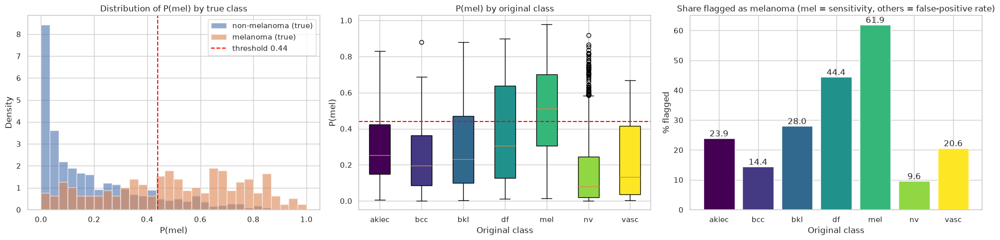

In [24]:
def per_class_analysis(run):
    pr, thr = run["preds"], run["thr"]
    t = pr.groupby("clase_original").agg(n=("p_mel", "size"), mean_p_mel=("p_mel", "mean"),
                                         median_p_mel=("p_mel", "median"), flagged_as_mel=("pred", "sum"))
    t["flagged (%)"] = (100 * t["flagged_as_mel"] / t["n"]).round(1)
    t = t.reindex([c for c in CLASSES if c in t.index])
    display(t.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    y, p = pr["y_real_mel"].values, pr["p_mel"].values
    bins = np.linspace(0, 1, 31)
    axes[0].hist(p[y == 0], bins=bins, alpha=0.6, density=True, label="non-melanoma (true)")
    axes[0].hist(p[y == 1], bins=bins, alpha=0.6, density=True, label="melanoma (true)")
    axes[0].axvline(thr, color="red", ls="--", label=f"threshold {thr:.2f}")
    axes[0].set(title="Distribution of P(mel) by true class", xlabel="P(mel)", ylabel="Density")
    axes[0].legend()

    classes = [c for c in CLASSES if c in t.index]
    data = [pr.loc[pr["clase_original"] == c, "p_mel"].values for c in classes]
    bp = axes[1].boxplot(data, patch_artist=True)
    axes[1].set_xticklabels(classes)
    for patch, c in zip(bp["boxes"], classes):
        patch.set_facecolor(CLASS_COLORS[c])
    axes[1].axhline(thr, color="red", ls="--")
    axes[1].set(title="P(mel) by original class", xlabel="Original class", ylabel="P(mel)")

    axes[2].bar(classes, t.loc[classes, "flagged (%)"], color=[CLASS_COLORS[c] for c in classes])
    axes[2].bar_label(axes[2].containers[0], fmt="%.1f")
    axes[2].set(title="Share flagged as melanoma (mel = sensitivity, others = false-positive rate)",
                xlabel="Original class", ylabel="% flagged")
    plt.tight_layout()
    plt.show()


if RUN is not None and RUN["preds"] is not None:
    per_class_analysis(RUN)

### 8.8 How reliable are these numbers? (bootstrap confidence intervals)
The validation set contains relatively few melanomas, so every metric has a sizeable uncertainty. The table gives 95% percentile intervals from 1,000 bootstrap resamples of the validation images at the chosen threshold. Note that images are resampled individually, although photos of the same lesion are correlated, so the real uncertainty is probably a little larger.

In [25]:
def bootstrap_ci(run, n_boot=1000, seed=SEED):
    y, p, thr = run["preds"]["y_real_mel"].values, run["preds"]["p_mel"].values, run["thr"]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        yb, pb = y[idx], p[idx]
        if yb.min() == yb.max():
            continue
        m = binary_metrics(yb, pb, thr)
        out.append(dict(auc=roc_auc_score(yb, pb), average_precision=average_precision_score(yb, pb),
                        sensitivity=m["sensitivity"], specificity=m["specificity"],
                        precision=m["precision"], f1=m["f1"]))
    d = pd.DataFrame(out)
    m0 = binary_metrics(y, p, thr)
    point = dict(auc=roc_auc_score(y, p), average_precision=average_precision_score(y, p),
                 sensitivity=m0["sensitivity"], specificity=m0["specificity"], precision=m0["precision"], f1=m0["f1"])
    return pd.DataFrame({"estimate": pd.Series(point), "ci_95_low": d.quantile(0.025), "ci_95_high": d.quantile(0.975)})


if RUN is not None and RUN["preds"] is not None:
    display(bootstrap_ci(RUN).round(3))

,estimate,ci_95_low,ci_95_high
auc,0.828,0.802,0.854
average_precision,0.437,0.373,0.502
sensitivity,0.619,0.558,0.679
specificity,0.866,0.850,0.882
precision,0.378,0.330,0.426
f1,0.469,0.421,0.515


### 8.9 Error analysis: missed melanomas and false alarms
The most confident mistakes: melanomas with the **lowest** P(mel) (false negatives) and non-melanomas with the **highest** P(mel) (false positives). Looking at them often reveals systematic problems (e.g. hair, rulers, dark vignettes, unusual lesions).

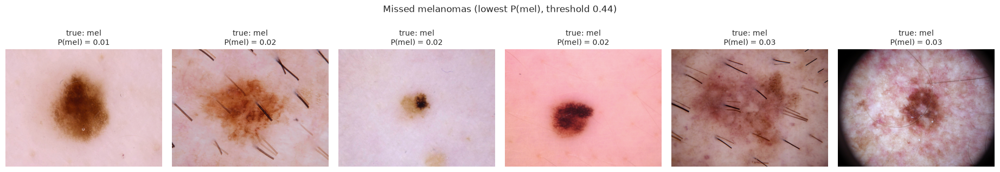

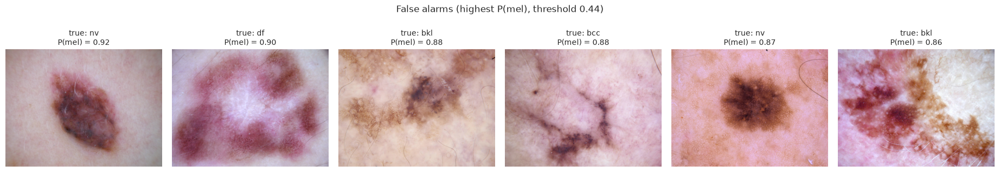

In [26]:
def show_errors(run, n=6):
    pr, thr = run["preds"], run["thr"]
    base = Path(run["cfg"].get("dataset_dir", DATASET_DIR)) / "validation"
    if not base.exists():
        base = VAL_DIR
    if not base.exists():
        print("[skipped] validation images not found (expected Datasets/validation).")
        return
    fn = pr[(pr["y_real_mel"] == 1) & (pr["p_mel"] < thr)].sort_values("p_mel").head(n)
    fp = pr[(pr["y_real_mel"] == 0) & (pr["p_mel"] >= thr)].sort_values("p_mel", ascending=False).head(n)
    for title, df in ((f"Missed melanomas (lowest P(mel), threshold {thr:.2f})", fn),
                      (f"False alarms (highest P(mel), threshold {thr:.2f})", fp)):
        if df.empty:
            print(f"{title}: none.")
            continue
        fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.6))
        axes = np.atleast_1d(axes)
        for ax in axes:
            ax.axis("off")
        for ax, (_, r) in zip(axes, df.iterrows()):
            path = base / r["archivo"]
            if path.exists():
                ax.imshow(read_rgb(path))
            ax.set_title(f"true: {r['clase_original']}\nP(mel) = {r['p_mel']:.2f}", fontsize=10)
        fig.suptitle(title, fontsize=12)
        plt.tight_layout()
        plt.show()


if RUN is not None and RUN["preds"] is not None:
    show_errors(RUN)

### 8.10 Comparison with the earlier 7-class experiments
`results.csv` holds the earlier experiments (basic CNN and EfficientNetB4 variants, 7 classes, trained on the **unbalanced** data with class weights). The dashed line is the sensitivity of the binary model. The comparison is indicative only:
- the earlier models solve a harder 7-class problem and `recall_mel` is their recall for melanoma, while the binary model only has to separate melanoma from the rest and its threshold was tuned on the validation set;
- `results.csv` has no false-alarm information, so **specificity and precision cannot be compared**; look at them in section 8.5 before drawing conclusions.

,name,variant,img_size,rgb,pad,augment,class_weights,fine_tune,accuracy,macro_f1,macro_recall,recall_mel,epochs,minutes
0,E4_sem_aug,B4,128,False,False,False,sqrt,True,0.721,0.473,0.479,0.458,26,17.3
1,E2_rgb,B4,128,True,False,True,sqrt,True,0.706,0.468,0.480,0.449,23,16.1
2,E6_224,B4,224,False,False,True,sqrt,True,0.687,0.457,0.478,0.470,22,24.6
3,E1_B4_128_ref,B4,128,False,False,True,sqrt,True,0.703,0.433,0.429,0.462,23,16.1
4,E3_pad,B4,128,False,True,True,sqrt,True,0.690,0.432,0.434,0.479,30,20.2
5,E5_cw_balanced,B4,128,False,False,True,balanced,True,0.602,0.398,0.467,0.496,30,19.6
6,CNN_basico,CNN,128,False,False,False,none,False,0.711,0.396,0.357,0.339,14,3.3


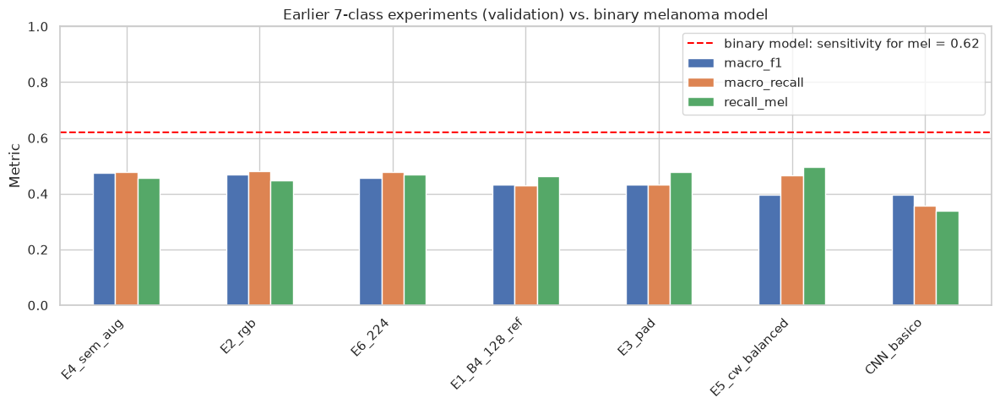

Best recall_mel among the 7-class experiments: 0.496 (E5_cw_balanced) | binary model sensitivity: 0.619


In [27]:
def compare_with_previous(run=None):
    res = pd.read_csv(RESULTS_CSV).sort_values("macro_f1", ascending=False).reset_index(drop=True)
    cols = [c for c in ["name", "variant", "img_size", "rgb", "pad", "augment", "class_weights", "fine_tune",
                        "accuracy", "macro_f1", "macro_recall", "recall_mel", "epochs", "minutes"] if c in res.columns]
    display(res[cols].round(3))

    ax = res.set_index("name")[["macro_f1", "macro_recall", "recall_mel"]].plot.bar(figsize=(12, 5))
    sens = None
    if run is not None and run["preds"] is not None:
        y, p = run["preds"]["y_real_mel"].values, run["preds"]["p_mel"].values
        sens = binary_metrics(y, p, run["thr"])["sensitivity"]
        ax.axhline(sens, color="red", ls="--", label=f"binary model: sensitivity for mel = {sens:.2f}")
    ax.set(title="Earlier 7-class experiments (validation)" + (" vs. binary melanoma model" if sens is not None else ""),
           ylim=(0, 1), ylabel="Metric", xlabel="")
    ax.legend()
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    best = res.loc[res["recall_mel"].idxmax()]
    msg = f"Best recall_mel among the 7-class experiments: {best['recall_mel']:.3f} ({best['name']})"
    print(msg + (f" | binary model sensitivity: {sens:.3f}" if sens is not None else ""))


if RESULTS_CSV.exists():
    compare_with_previous(RUN)
else:
    print(f"[skipped] {RESULTS_CSV} not found.")

## 9. Notes and caveats

- **Threshold chosen on the evaluation set.** The decision threshold, `EarlyStopping` and `ReduceLROnPlateau` all use the *same* validation set on which the final metrics are reported, so the numbers are somewhat optimistic. A separate, untouched test split would give an unbiased estimate.
- **Few melanomas.** Validation metrics for `mel` rest on a limited number of positive cases (see the confidence intervals in 8.8); small differences between runs or models are within the noise.
- **Balancing and leakage.** Balancing must be done **after** the lesion-grouped train/validation split and only on the training lesions. Section 7.5 shows whether the balanced folder used in this project contains validation lesions.
- **Balanced training, imbalanced validation.** If the training set is balanced while the validation set keeps the natural class distribution (melanoma ≈ 11% in HAM10000), the validation setup reflects reality, but precision will be much lower than sensitivity and specificity suggest, and accuracy is dominated by `nv`. Check the data section of the run summary (8.2) to see which distributions were actually used.
- **Augmentation vs. colour.** The balancing script applies `ColorJitter` to the augmented copies, while the training script deliberately avoids colour changes because colour is clinically informative (section 7.4 quantifies the shift).
- **Educational use only.** The models are not validated for clinical use.

## **8. Training results (binary melanoma classifier)**

# Analysis of Results — Multiclass Training (HAM10000)
This notebook allows for the analysis of performance metrics, learning curves, and prediction errors for the 7-class multiclass model.

In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Aesthetic configuration of charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

# Automatically locate the most recent execution folder in 'runs/'
runs_dir = Path("runs")
latest_run = max(runs_dir.glob("B7_multiclase_*"), key=lambda p: p.stat().st_mtime)
print(f"Analyzing the execution: {latest_run}")

Analizando la ejecución: runs/B7_multiclase_B4_128_20261010_152908


In [ ]:
# Load result files
history_df = pd.read_csv(latest_run / "historial_epocas.csv")
preds_df = pd.read_csv(latest_run / "predicciones_validacion.csv")

with open(latest_run / "metricas.json", "r", encoding="utf-8") as f:
  metrics_json = json.load(f)

print("--- Configuration Summary ---")
for k, v in metrics_json["config"].items():
  print(f"{k}: {v}")

print("\n--- General Configuration ---")
print(f"Final validation accuracy: {metrics_json['evaluation']['accuracy']:.4f}")
print(f"Final validation loss: {metrics_json['evaluation']['val_loss']:.4f}")

# Vista previa del historial de épocas
display(history_df.head())

--- Resumen de Configuración ---
base_dir: None
dataset_dir: Datasets
limit_per_class: None
img_size: 128
rgb: True
pad: False
variant: B4
pretrained: imagenet
augment: True
class_weights: sqrt
epochs_head: 15
fine_tune: True
epochs_ft: 15
ft_layers: 30
head_lr: 0.0005
ft_lr: 1e-05
batch_size: 32
seed: 42
name: B7_multiclase_B4_128
output_dir: runs
quick: False

--- Evaluación General ---
Accuracy de validación final: 0.6947
Loss de validación final: 0.8293


,fase,epoca,epoca_fase,lr,segundos,accuracy,accuracy_1,loss,val_accuracy,val_accuracy_1,val_loss
0,fase1_cabeza,1,1,0.0005,22.5,0.608935,0.608935,1.224166,0.592885,0.592885,1.115626
1,fase1_cabeza,2,2,0.0005,11.1,0.659993,0.659993,1.021154,0.645751,0.645751,0.928549
2,fase1_cabeza,3,3,0.0005,11.1,0.677387,0.677387,0.948345,0.686265,0.686265,0.850039
3,fase1_cabeza,4,4,0.0005,11.1,0.674759,0.674759,0.928622,0.654150,0.654150,0.890556
4,fase1_cabeza,5,5,0.0005,11.0,0.689401,0.689401,0.894880,0.629941,0.629941,0.960812


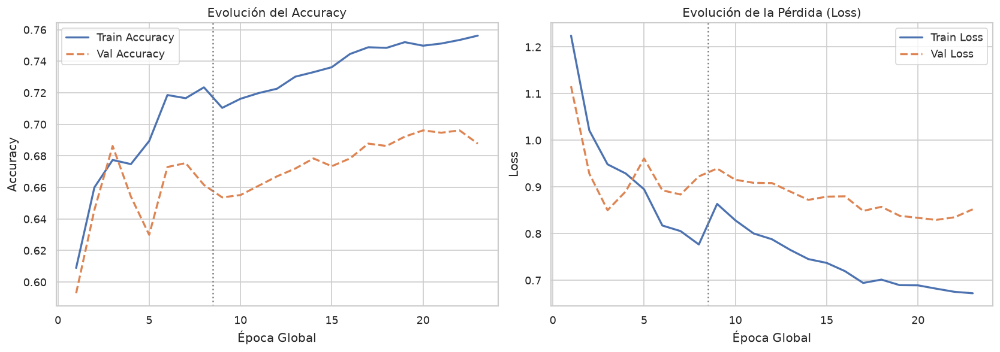

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
axes[0].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Train Accuracy",
    lw=2,
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Val Accuracy",
    lw=2,
    linestyle="--",
)
axes[0].set_title("Accuracy Evolution")
axes[0].set_xlabel("Global Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss Plot
axes[1].plot(history_df["epoch"], history_df["loss"], label="Train Loss", lw=2)
axes[1].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Val Loss",
    lw=2,
    linestyle="--",
)
axes[1].set_title("Loss Evolution")
axes[1].set_xlabel("Global Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

# Mark phase change if fine-tuning exists
if "phase" in history_df.columns:
  phase_changes = history_df.index[
      history_df["phase"] != history_df["phase"].shift()
  ].tolist()
  for b in phase_changes[1:]:
    change_epoch = history_df.loc[b, "epoch"]
    for ax in axes:
      ax.axvline(
          change_epoch - 0.5,
          color="gray",
          linestyle=":",
          label="Fine-Tuning Start",
      )

plt.tight_layout()
plt.show()

=== INFORME DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

       akiec       0.27      0.34      0.30        67
         bcc       0.40      0.38      0.39        90
         bkl       0.45      0.56      0.50       243
          df       0.09      0.17      0.12        18
         mel       0.39      0.46      0.42       236
          nv       0.89      0.81      0.85      1336
        vasc       0.66      0.56      0.60        34

    accuracy                           0.69      2024
   macro avg       0.45      0.47      0.45      2024
weighted avg       0.73      0.69      0.71      2024



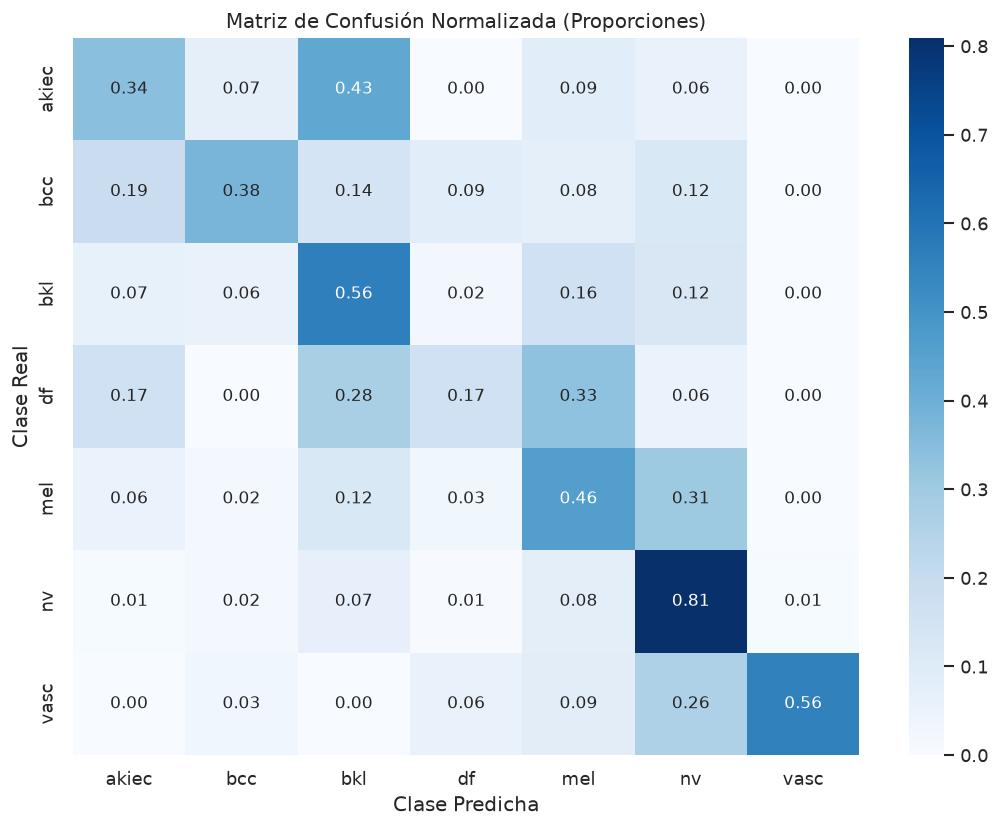

In [ ]:
# Get list of unique classes from predictions
categories = sorted(preds_df["clase_real"].unique())

y_true = preds_df["clase_real"]
y_pred = preds_df["clase_predicha"]

# Generate detailed per-class classification report
print("=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_true, y_pred, target_names=categories, zero_division=0
    )
)

# Plot Confusion Matrix Normalized by True Values
cm = confusion_matrix(y_true, y_pred, labels=categories, normalize="true")

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories,
)
plt.title("Normalized Confusion Matrix (Proportions)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

<h2 style="color: #0066cc;"><b>10. Final comparison — binary melanoma classifier and four preprocessing pipelines</p></h2>
This section compares binary runs only (melanoma versus non-melanoma). For a valid experiment, all four runs must use the same lesion_id split, random seed, architecture, resolution, augmentation, class weights, and hyperparameters. The preprocessing pipeline passed through --preprocess must be the only experimental variable.
The primary clinical selection rule is the highest specificity obtainable while preserving sensitivity of at least 85%. AUC and average precision measure probability ranking, whereas val_loss measures probabilistic fit; val_loss alone does not determine the best clinical pipeline. The generated discussion is descriptive: mechanisms proposed for preprocessing effects are plausible hypotheses, not proof of causality.
This is an academic research and decision-support analysis. It is not a clinical diagnostic device and does not replace dermatological assessment or histopathological confirmation when indicated.

In [ ]:
# Reproducible comparison of four pipelines for the BINARY melanoma-versus-non-melanoma classifier
# Expects four directories under runs/, for example:
# Exp_Baseline_... | Exp_DullRazor_... | Exp_ShadesOfGray_... | Exp_ContrastFocused_...
# Each directory must contain metricas.json, historial_epocas.csv, and predicciones_validacion.csv

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from IPython.display import display, Markdown, Image as DisplayImage

In [2]:
RUNS_DIR = Path("runs")
TARGET_SENSITIVITY = 0.85

In [ ]:
# If directory names do not include the pipeline name, populate this dictionary explicitly.
# Example: RUN_PATHS = {"baseline": RUNS_DIR / "Exp_Baseline_...", ...}
RUN_PATHS = {}

PIPELINE_LABELS = {
    "baseline": "Baseline",
    "dullrazor": "DullRazor",
    "shades_of_gray": "Shades of Gray",
    "dullrazor_clahe": "Contrast-Focused\n(DullRazor + CLAHE)",
}
PIPELINE_ORDER = list(PIPELINE_LABELS)
MECHANISMS = {
    "baseline": (
        "does not modify the image before resizing; it preserves the original colour, texture, and borders and serves as the control",
        "when it wins, the added transformations did not provide measurable discriminative signal",
    ),
    "dullrazor": (
        "removes thin dark linear structures consistent with hair using Black-Hat morphology and inpainting",
        "may help when hair occludes the lesion, but may harm performance if masking or inpainting removes real pigmented details",
    ),
    "shades_of_gray": (
        "reduces illumination and white-balance variation across imaging devices",
        "may help against technical variation, but may harm performance if it alters lesion colour information",
    ),
    "dullrazor_clahe": (
        "combines hair removal with local contrast enhancement in the luminance channel",
        "may make borders and internal structures more visible, but may also amplify noise, artefacts, or inpainting effects",
    ),
}

### Results at a fixed minimum sensitivity of 85%

,Pipeline,AUC,Average precision,Lowest val_loss,Best epoch,Clinical threshold,Sensitivity,Specificity,Precision,FN,FP,Status
0,Baseline,0.833,0.423,0.333,4,0.202,0.852,0.615,0.226,35.0,689.0,sensitivity >= 85%
1,DullRazor,0.856,0.472,0.302,8,0.212,0.852,0.672,0.255,35.0,586.0,sensitivity >= 85%
2,Shades of Gray,0.821,0.408,0.339,27,0.143,0.852,0.593,0.217,35.0,727.0,sensitivity >= 85%
3,Contrast-Focused\n(DullRazor + CLAHE),0.827,0.374,0.331,21,0.221,0.852,0.653,0.245,35.0,621.0,sensitivity >= 85%


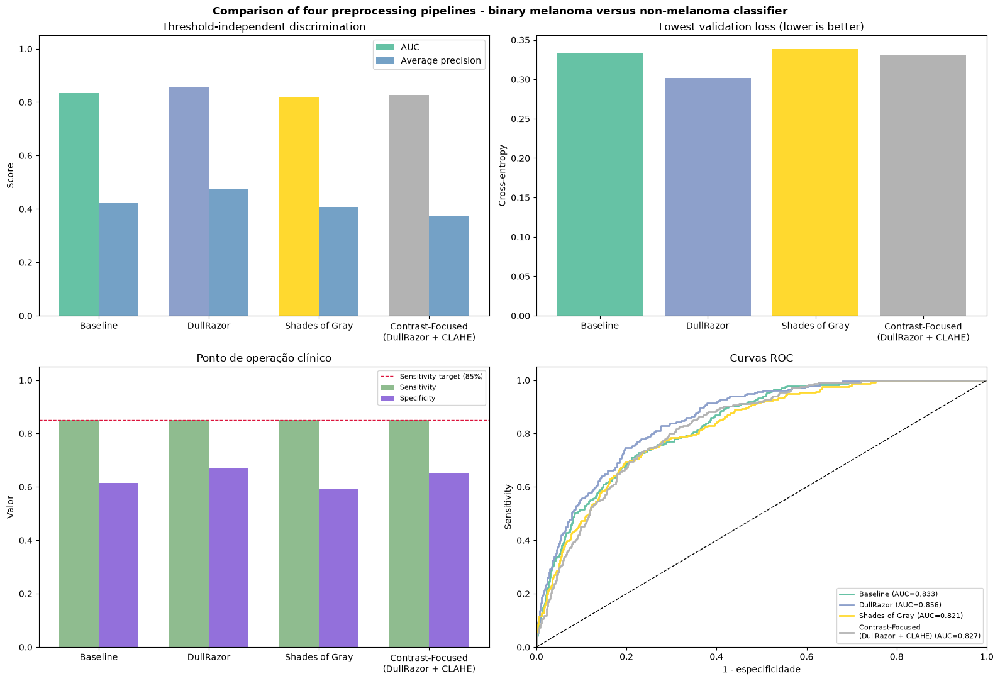

Figure saved to: /home/fabio-noriega/Coding/IST/Skin-cancer-detection-with-EfficientNet-CNN/runs/comparacao_4_pipelines_binarias.png

Automatic conclusion based on observed results
Selection rule: Among pipelines with sensitivity >= 85%, the highest specificity was selected; AUC and average precision break ties.
Selected pipeline: DullRazor | sensitivity=0.852, specificity=0.672, AUC=0.856, FN=35, FP=586.

- Baseline: AUC difference=+0.000, specificity difference=+0.000, val_loss difference=+0.000 versus baseline. The pipeline does not modify the image before resizing; it preserves the original colour, texture, and borders and serves as the control; when it wins, the added transformations did not provide measurable discriminative signal. These mechanisms make the observed pattern plausible, but do not demonstrate causality.

- DullRazor: AUC difference=+0.023, specificity difference=+0.058, val_loss difference=-0.031 versus baseline. The pipeline removes thin dark linear structures con

### Training curves for each run

Baseline: runs/Exp_Baseline_20261020_091437/curvas_entrenamiento.png


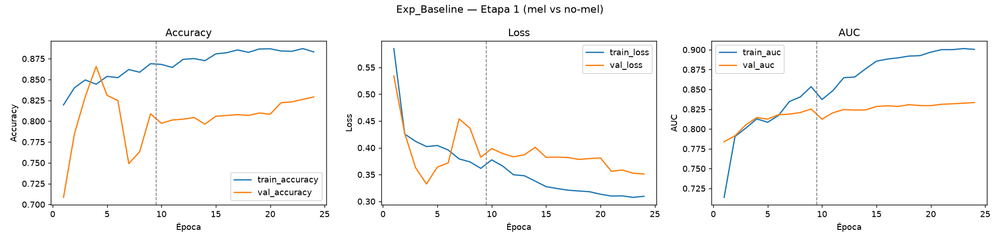

DullRazor: runs/Exp_DullRazor_20261020_093108/curvas_entrenamiento.png


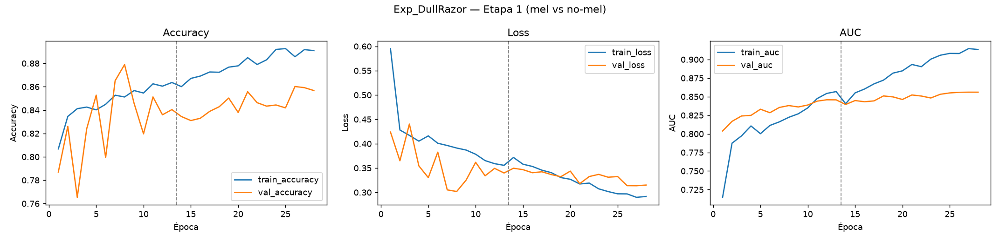

Shades of Gray: runs/Exp_ShadesOfGray_20261020_095342/curvas_entrenamiento.png


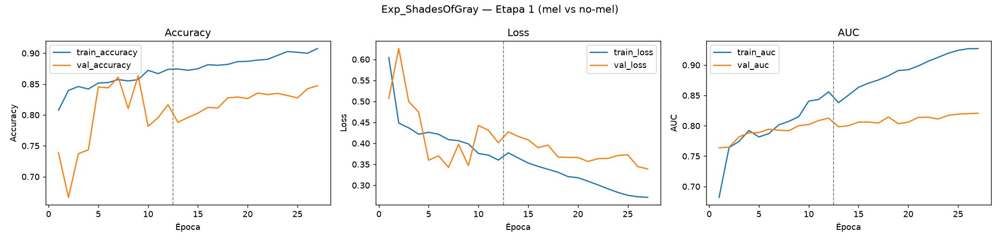

Contrast-Focused
(DullRazor + CLAHE): runs/Exp_ContrastFocused_20261020_101306/curvas_entrenamiento.png


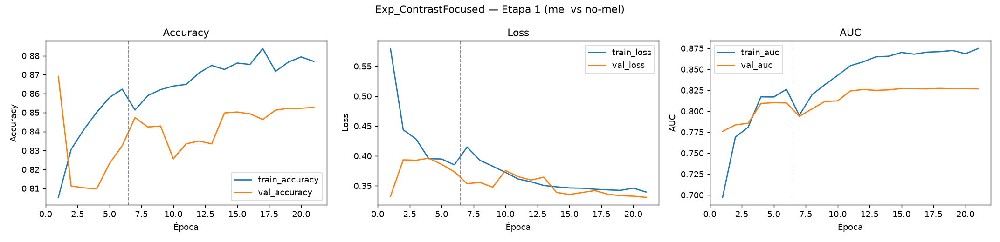

In [ ]:
def infer_pipeline(run_dir, config):
    """Infer the preprocessing label from config first, then from the run-folder name."""
    text = " ".join([str(config.get(k, "")) for k in ("preprocess", "pipeline", "name")] + [run_dir.name]).lower()
    text = text.replace("-", "_").replace(" ", "_")
    if any(token in text for token in ("contrastfocused", "contrast_focused", "dullrazor_clahe", "dullrazor+clahe", "clahe")):
        return "dullrazor_clahe"
    if any(token in text for token in ("shadesofgray", "shades_of_gray", "shades_gray", "colour_constancy", "color_constancy")):
        return "shades_of_gray"
    if any(token in text for token in ("dullrazor", "dull_razor", "no_hair", "hair_removal")):
        return "dullrazor"
    if any(token in text for token in ("baseline", "base", "reference", "ref")):
        return "baseline"
    return None


def binary_columns(predictions):
    """Accept the column names written by the binary melanoma training script only."""
    probability = next((c for c in ("p_mel", "prob_mel", "mel_probability") if c in predictions.columns), None)
    truth = next((c for c in ("y_real_mel", "y_true", "mel_true") if c in predictions.columns), None)
    return truth, probability


def operating_point(y_true, p_mel, min_sensitivity=TARGET_SENSITIVITY):
    """Choose the most specific threshold that still meets the predeclared sensitivity target."""
    thresholds = np.unique(np.r_[0.0, np.asarray(p_mel), 1.0])
    rows = []
    for threshold in thresholds:
        predicted = (p_mel >= threshold).astype(int)
        tp = int(((predicted == 1) & (y_true == 1)).sum())
        fp = int(((predicted == 1) & (y_true == 0)).sum())
        fn = int(((predicted == 0) & (y_true == 1)).sum())
        tn = int(((predicted == 0) & (y_true == 0)).sum())
        sensitivity = tp / (tp + fn) if tp + fn else np.nan
        specificity = tn / (tn + fp) if tn + fp else np.nan
        precision = tp / (tp + fp) if tp + fp else np.nan
        rows.append(dict(threshold=threshold, sensitivity=sensitivity, specificity=specificity,
                         precision=precision, tp=tp, fp=fp, fn=fn, tn=tn))
    points = pd.DataFrame(rows)
    eligible = points.loc[points["sensitivity"] >= min_sensitivity]
    if eligible.empty:
        best = points.sort_values(["sensitivity", "specificity"], ascending=False).iloc[0].to_dict()
        best["target_reached"] = False
    else:
        best = eligible.sort_values(["specificity", "threshold"], ascending=False).iloc[0].to_dict()
        best["target_reached"] = True
    return best


def load_binary_run(run_dir):
    metrics_path = run_dir / "metricas.json"
    predictions_path = run_dir / "predicciones_validacion.csv"
    history_path = run_dir / "historial_epocas.csv"
    if not (metrics_path.exists() and predictions_path.exists() and history_path.exists()):
        return None
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    predictions = pd.read_csv(predictions_path)
    truth_col, probability_col = binary_columns(predictions)
    if truth_col is None or probability_col is None:
        return None  # This is a multiclass run, not part of this comparison.
    y = predictions[truth_col].astype(int).to_numpy()
    p = predictions[probability_col].astype(float).to_numpy()
    if len(np.unique(y)) != 2:
        return None
    history = pd.read_csv(history_path)
    config = metrics.get("config", {})
    pipeline = infer_pipeline(run_dir, config)
    if pipeline is None:
        return None
    point = operating_point(y, p)
    return {
        "dir": run_dir, "pipeline": pipeline, "config": config, "y": y, "p": p,
        "auc": float(roc_auc_score(y, p)),
        "average_precision": float(average_precision_score(y, p)),
        "min_val_loss": float(history["val_loss"].min()) if "val_loss" in history else np.nan,
        "best_epoch": int(history.loc[history["val_loss"].idxmin(), "epoca"]) if {"val_loss", "epoca"} <= set(history.columns) else np.nan,
        **point,
    }


if RUN_PATHS:
    candidate_dirs = list(RUN_PATHS.values())
else:
    candidate_dirs = [p.parent for p in RUNS_DIR.rglob("metricas.json")] if RUNS_DIR.exists() else []

# If repeated runs exist for one pipeline, keep the newest one and report that choice.
loaded = [r for p in candidate_dirs if p.exists() for r in [load_binary_run(p)] if r is not None]
latest_by_pipeline = {}
for run in loaded:
    old = latest_by_pipeline.get(run["pipeline"])
    if old is None or run["dir"].stat().st_mtime > old["dir"].stat().st_mtime:
        latest_by_pipeline[run["pipeline"]] = run
runs = [latest_by_pipeline[p] for p in PIPELINE_ORDER if p in latest_by_pipeline]

if len(runs) != 4:
    found = {PIPELINE_LABELS[r["pipeline"]]: str(r["dir"]) for r in runs}
    print("The four required binary runs were not found.")
    print("Found:", found if found else "none")
    print("Expected: Baseline, DullRazor, Shades of Gray, and Contrast-Focused (DullRazor + CLAHE).")
    print("Save each run under runs/ and confirm that it contains metricas.json, historial_epocas.csv, and predicciones_validacion.csv.")
else:
    results = pd.DataFrame([{k: v for k, v in r.items() if k not in {"y", "p", "config"}} for r in runs])
    results["pipeline_label"] = results["pipeline"].map(PIPELINE_LABELS)
    results = results.set_index("pipeline").loc[PIPELINE_ORDER].reset_index()
    results["target_status"] = np.where(results["target_reached"], f"sensitivity >= {TARGET_SENSITIVITY:.0%}", "target not reached")
    table = results[["pipeline_label", "auc", "average_precision", "min_val_loss", "best_epoch", "threshold",
                     "sensitivity", "specificity", "precision", "fn", "fp", "target_status"]].copy()
    table.columns = ["Pipeline", "AUC", "Average precision", "Lowest val_loss", "Best epoch", "Clinical threshold",
                     "Sensitivity", "Specificity", "Precision", "FN", "FP", "Status"]
    display(Markdown(f"### Results at a fixed minimum sensitivity of {TARGET_SENSITIVITY:.0%}"))
    display(table.round({"AUC": 3, "Average precision": 3, "Lowest val_loss": 3, "Clinical threshold": 3,
                         "Sensitivity": 3, "Specificity": 3, "Precision": 3}))

    # Primary selection: the pipeline that preserves the target sensitivity with the most specificity.
    eligible = results[results["target_reached"]].copy()
    if eligible.empty:
        winner = results.sort_values(["sensitivity", "specificity"], ascending=False).iloc[0]
        rule = "No pipeline reached the target; the highest observed sensitivity was selected, breaking ties by specificity."
    else:
        winner = eligible.sort_values(["specificity", "auc", "average_precision"], ascending=False).iloc[0]
        rule = f"Among pipelines with sensitivity >= {TARGET_SENSITIVITY:.0%}, the highest specificity was selected; AUC and average precision break ties."
    baseline = results.loc[results["pipeline"] == "baseline"].iloc[0]

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    x = np.arange(len(results)); colors = plt.cm.Set2(np.linspace(0, 1, len(results)))
    axes[0, 0].bar(x - 0.18, results["auc"], 0.36, label="AUC", color=colors)
    axes[0, 0].bar(x + 0.18, results["average_precision"], 0.36, label="Average precision", color="steelblue", alpha=0.75)
    axes[0, 0].set(xticks=x, xticklabels=results["pipeline_label"], ylim=(0, 1.05), ylabel="Score", title="Threshold-independent discrimination")
    axes[0, 0].legend()
    axes[0, 1].bar(x, results["min_val_loss"], color=colors)
    axes[0, 1].set(xticks=x, xticklabels=results["pipeline_label"], ylabel="Cross-entropy", title="Lowest validation loss (lower is better)")
    axes[1, 0].bar(x - 0.18, results["sensitivity"], 0.36, label="Sensitivity", color="darkseagreen")
    axes[1, 0].bar(x + 0.18, results["specificity"], 0.36, label="Specificity", color="mediumpurple")
    axes[1, 0].axhline(TARGET_SENSITIVITY, color="crimson", ls="--", lw=1, label=f"Sensitivity target ({TARGET_SENSITIVITY:.0%})")
    axes[1, 0].set(xticks=x, xticklabels=results["pipeline_label"], ylim=(0, 1.05), ylabel="Valor", title="Clinical operating point")
    axes[1, 0].legend(fontsize=8)
    for run, color in zip(runs, colors):
        fpr, tpr, _ = roc_curve(run["y"], run["p"])
        axes[1, 1].plot(fpr, tpr, lw=2, color=color, label=f"{PIPELINE_LABELS[run['pipeline']]} (AUC={run['auc']:.3f})")
    axes[1, 1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1, 1].set(xlim=(0, 1), ylim=(0, 1.05), xlabel="1 - especificidade", ylabel="Sensitivity", title="Curves ROC")
    axes[1, 1].legend(fontsize=8, loc="lower right")
    fig.suptitle("Comparison of four preprocessing pipelines - binary melanoma versus non-melanoma classifier", fontweight="bold")
    plt.tight_layout()
    output_figure = RUNS_DIR / "comparacao_4_pipelines_binarias.png"
    fig.savefig(output_figure, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Figure saved to: {output_figure.resolve()}")

    print("\nAutomatic conclusion based on observed results")
    print("Selection rule:", rule)
    print(f"Selected pipeline: {PIPELINE_LABELS[winner['pipeline']]} | sensitivity={winner['sensitivity']:.3f}, "
          f"specificity={winner['specificity']:.3f}, AUC={winner['auc']:.3f}, FN={int(winner['fn'])}, FP={int(winner['fp'])}.")
    for _, row in results.iterrows():
        da = row["auc"] - baseline["auc"]
        ds = row["specificity"] - baseline["specificity"]
        dl = row["min_val_loss"] - baseline["min_val_loss"]
        mechanism, caveat = MECHANISMS[row["pipeline"]]
        print(f"\n- {PIPELINE_LABELS[row['pipeline']]}: AUC difference={da:+.3f}, specificity difference={ds:+.3f}, val_loss difference={dl:+.3f} versus baseline. "
              f"The pipeline {mechanism}; {caveat}. These mechanisms make the observed pattern plausible, but do not demonstrate causality.")
    print("\nInterpretation: AUC measures global ranking; val_loss measures probabilistic fit; for triage, the primary selection criterion is "
          "the specificity achieved while preserving the pre-specified sensitivity. The selection must be confirmed on an independent test set, "
          "because these values were calculated on the validation data used during development.")

    display(Markdown("### Training curves for each run"))
    for _, row in results.iterrows():
        curve = Path(row["dir"]) / "curvas_entrenamiento.png"
        print(f"{row['pipeline_label']}: {curve}")
        if curve.exists():
            display(DisplayImage(filename=str(curve)))
        else:
            print("[image not found - run the experiment or confirm the file name and location]")

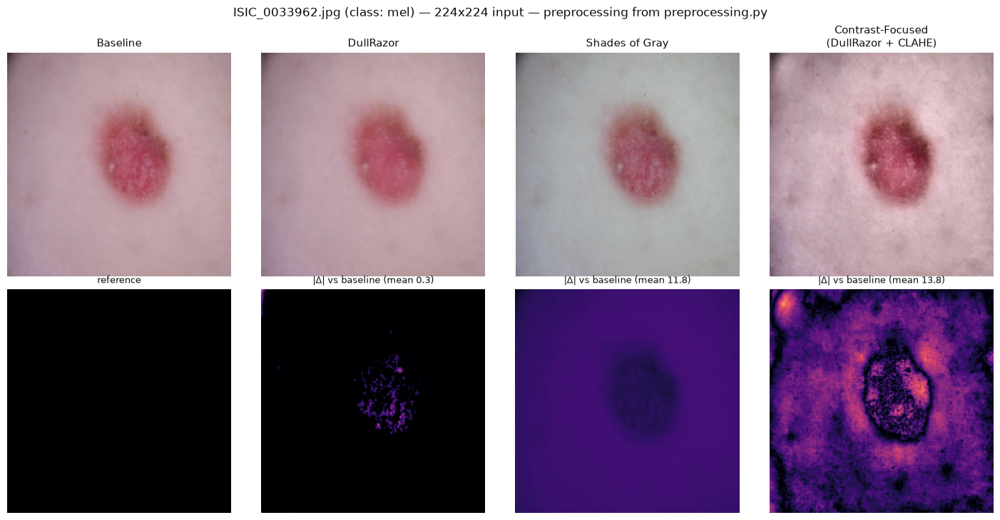

In [22]:
# 10.0 Visual check: the same random image under each of the four preprocessing pipelines
# Uses preprocess_pipeline from preprocessing.py (the function used for training and the test set).
# If that module cannot be imported, it falls back to the section-6 helpers (remove_hair, color_constancy, clahe_lab).
from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

PREVIEW_CLASS = "mel"      # class to sample from (None = any class)
PREVIEW_SIZE = 224         # same resolution as the 224x224 runs; use 448 for a closer look
PREVIEW_SEED = None        # None = a new image each run; an int = always the same image
PREVIEW_IMAGE = None       # or a path, e.g. Path("Datasets_safe/training/mel/ISIC_0024310.jpg")
SHOW_DIFFERENCE = True     # second row: |pipeline - baseline|, shows what each pipeline changed

PREVIEW_PIPELINES = {      # label -> method name in preprocessing.py
    "Baseline": "baseline",
    "DullRazor": "hair_removal",
    "Shades of Gray": "color_constancy",
    "Contrast-Focused\n(DullRazor + CLAHE)": "contrast_focused",
}

try:
    from preprocessing import preprocess_pipeline
    PREVIEW_SOURCE = "preprocessing.py"
except ImportError:
    # Fallback with the section-6 helpers (they work in BGR, so convert around them)
    _FALLBACK_STEPS = {"hair_removal": (remove_hair,), "color_constancy": (color_constancy,),
                       "contrast_focused": (remove_hair, clahe_lab)}

    def preprocess_pipeline(img_rgb, target_size, method):
        bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        for f in _FALLBACK_STEPS[method]:
            bgr = f(bgr)
        return cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), target_size, interpolation=cv2.INTER_AREA)

    PREVIEW_SOURCE = "section-6 helpers (preprocessing.py not found)"


def preview_candidates(cls=None):
    # Original (non-augmented) images: the safe training split first, then the raw HAM10000 folders
    folders = [Path("Datasets_safe") / "training", Path("Datasets") / "training"]
    for root in folders:
        if root.is_dir():
            pattern = f"{cls}/*.jpg" if cls else "*/*.jpg"
            files = [p for p in root.glob(pattern) if "_aug_" not in p.stem]
            if files:
                return files
    raw = [p for d in (Path("HAM10000_images_part_1"), Path("HAM10000_images_part_2")) if d.is_dir()
           for p in d.glob("*.jpg")]
    if raw and cls and Path("HAM10000_metadata.csv").exists():
        import pandas as pd
        keep = set(pd.read_csv("HAM10000_metadata.csv").query("dx == @cls")["image_id"])
        raw = [p for p in raw if p.stem in keep]
    return raw


def apply_preview(img_rgb, method, size):
    if method == "baseline":   # same as load_test_images: resize only
        return cv2.resize(img_rgb, (size, size), interpolation=cv2.INTER_AREA)
    return preprocess_pipeline(img_rgb.copy(), target_size=(size, size), method=method)


def show_preprocessing_preview(path=None, cls=PREVIEW_CLASS, size=PREVIEW_SIZE, seed=PREVIEW_SEED,
                               show_difference=SHOW_DIFFERENCE):
    if path is None:
        cands = preview_candidates(cls)
        if not cands:
            print("[skipped] no images found (expected Datasets_safe/training/<class>/ or the raw HAM10000 folders).")
            return
        path = random.Random(seed).choice(sorted(cands))
    path = Path(path)
    bgr = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        print(f"[skipped] cannot read {path}")
        return
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    outs = {label: apply_preview(rgb, m, size) for label, m in PREVIEW_PIPELINES.items()}
    base = outs["Baseline"].astype(np.int16)

    n_rows = 2 if show_difference else 1
    fig, axes = plt.subplots(n_rows, len(outs), figsize=(3.6 * len(outs), 3.7 * n_rows))
    axes = np.atleast_2d(axes).reshape(n_rows, len(outs))
    for k, (label, img) in enumerate(outs.items()):
        axes[0, k].imshow(img)
        axes[0, k].set_title(label, fontsize=11)
        axes[0, k].axis("off")
        if show_difference:
            diff = np.abs(img.astype(np.int16) - base).mean(axis=2)
            axes[1, k].imshow(diff, cmap="magma", vmin=0, vmax=60)
            axes[1, k].set_title("reference" if k == 0 else f"|Δ| vs baseline (mean {diff.mean():.1f})", fontsize=9)
            axes[1, k].axis("off")
    cls_name = path.parent.name if path.parent.name in CLASSES else "?"
    fig.suptitle(f"{path.name} (class: {cls_name}) — {size}x{size} input — preprocessing from {PREVIEW_SOURCE}",
                 fontsize=12)
    plt.tight_layout()
    plt.show()


show_preprocessing_preview()

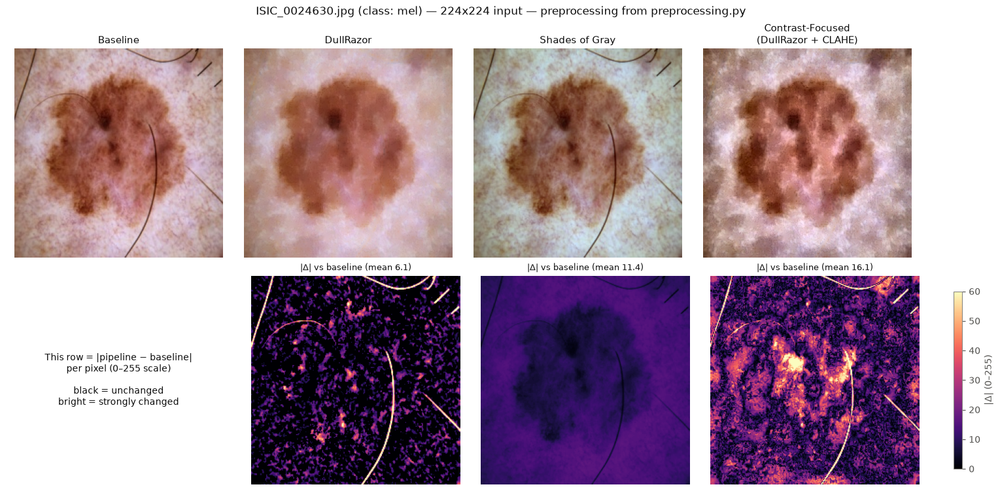

In [23]:
# 10.0 Visual check: the same random image under each of the four preprocessing pipelines
# Uses preprocess_pipeline from preprocessing.py (the function used for training and the test set).
# If that module cannot be imported, it falls back to the section-6 helpers (remove_hair, color_constancy, clahe_lab).
from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

PREVIEW_CLASS = "mel"      # class to sample from (None = any class)
PREVIEW_SIZE = 224         # same resolution as the 224x224 runs; use 448 for a closer look
PREVIEW_SEED = None        # None = a new image each run; an int = always the same image
PREVIEW_IMAGE = None       # or a path, e.g. Path("Datasets_safe/training/mel/ISIC_0024310.jpg")
SHOW_DIFFERENCE = True     # second row: |pipeline - baseline|, shows what each pipeline changed
PREVIEW_PICK_HAIRY = True  # True = pick one of the hairiest images of a random sample (best to show DullRazor)

PREVIEW_PIPELINES = {      # label -> method name in preprocessing.py
    "Baseline": "baseline",
    "DullRazor": "hair_removal",
    "Shades of Gray": "color_constancy",
    "Contrast-Focused\n(DullRazor + CLAHE)": "contrast_focused",
}

try:
    from preprocessing import preprocess_pipeline
    PREVIEW_SOURCE = "preprocessing.py"
except ImportError:
    # Fallback with the section-6 helpers (they work in BGR, so convert around them)
    _FALLBACK_STEPS = {"hair_removal": (remove_hair,), "color_constancy": (color_constancy,),
                       "contrast_focused": (remove_hair, clahe_lab)}

    def preprocess_pipeline(img_rgb, target_size, method):
        bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        for f in _FALLBACK_STEPS[method]:
            bgr = f(bgr)
        return cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), target_size, interpolation=cv2.INTER_AREA)

    PREVIEW_SOURCE = "section-6 helpers (preprocessing.py not found)"


def preview_candidates(cls=None):
    # Original (non-augmented) images: the safe training split first, then the raw HAM10000 folders
    folders = [Path("Datasets_safe") / "training", Path("Datasets") / "training"]
    for root in folders:
        if root.is_dir():
            pattern = f"{cls}/*.jpg" if cls else "*/*.jpg"
            files = [p for p in root.glob(pattern) if "_aug_" not in p.stem]
            if files:
                return files
    raw = [p for d in (Path("HAM10000_images_part_1"), Path("HAM10000_images_part_2")) if d.is_dir()
           for p in d.glob("*.jpg")]
    if raw and cls and Path("HAM10000_metadata.csv").exists():
        import pandas as pd
        keep = set(pd.read_csv("HAM10000_metadata.csv").query("dx == @cls")["image_id"])
        raw = [p for p in raw if p.stem in keep]
    return raw


def hair_fraction(path):
    # Share of pixels flagged as thin dark structures (same black-hat idea as DullRazor), on a small copy
    img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0.0
    img = cv2.resize(img, (300, 225), interpolation=cv2.INTER_AREA)
    bh = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9)))
    return float((bh > 10).mean())


def apply_preview(img_rgb, method, size):
    if method == "baseline":   # same as load_test_images: resize only
        return cv2.resize(img_rgb, (size, size), interpolation=cv2.INTER_AREA)
    return preprocess_pipeline(img_rgb.copy(), target_size=(size, size), method=method)


def show_preprocessing_preview(path=None, cls=PREVIEW_CLASS, size=PREVIEW_SIZE, seed=PREVIEW_SEED,
                               show_difference=SHOW_DIFFERENCE):
    if path is None:
        cands = preview_candidates(cls)
        if not cands:
            print("[skipped] no images found (expected Datasets_safe/training/<class>/ or the raw HAM10000 folders).")
            return
        rnd = random.Random(seed)
        if PREVIEW_PICK_HAIRY:   # rank a random sample by how much "hair" the black-hat filter finds
            sample = rnd.sample(sorted(cands), min(300, len(cands)))
            top = sorted(sample, key=hair_fraction, reverse=True)[:5]
            path = rnd.choice(top)
        else:
            path = rnd.choice(sorted(cands))
    path = Path(path)
    bgr = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        print(f"[skipped] cannot read {path}")
        return
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    outs = {label: apply_preview(rgb, m, size) for label, m in PREVIEW_PIPELINES.items()}
    base = outs["Baseline"].astype(np.int16)

    n_rows = 2 if show_difference else 1
    fig, axes = plt.subplots(n_rows, len(outs), figsize=(3.8 * len(outs), 3.7 * n_rows),
                             layout="constrained")
    axes = np.atleast_2d(axes).reshape(n_rows, len(outs))
    for k, (label, img) in enumerate(outs.items()):
        axes[0, k].imshow(img)
        axes[0, k].set_title(label, fontsize=11)
        axes[0, k].axis("off")
        if show_difference:
            diff = np.abs(img.astype(np.int16) - base).mean(axis=2)
            if k == 0:   # baseline vs itself is all zeros: use the panel to explain the colour scale instead
                axes[1, k].axis("off")
                axes[1, k].text(0.5, 0.5, "This row = |pipeline − baseline|\nper pixel (0–255 scale)\n\n"
                                "black = unchanged\nbright = strongly changed",
                                ha="center", va="center", fontsize=10, transform=axes[1, k].transAxes)
                continue
            im = axes[1, k].imshow(diff, cmap="magma", vmin=0, vmax=60)
            axes[1, k].set_title(f"|Δ| vs baseline (mean {diff.mean():.1f})", fontsize=9)
            axes[1, k].axis("off")
    if show_difference:
        fig.colorbar(im, ax=axes[1, 1:].tolist(), shrink=0.85, label="|Δ| (0–255)")
    cls_name = path.parent.name if path.parent.name in CLASSES else "?"
    fig.suptitle(f"{path.name} (class: {cls_name}) — {size}x{size} input — preprocessing from {PREVIEW_SOURCE}",
                 fontsize=12)
    plt.show()


show_preprocessing_preview()

<h2 style="color: #0066cc;"><b>## **11. Results after the data-leakage fix: binary and multiclass classifiers**</b></h2>
This section analyses the runs stored in `runs_dataleakage_fixed/`, trained on a dataset split **by `lesion_id` before any augmentation or balancing** (`balance_dataset_new.py`). It covers the binary melanoma-versus-non-melanoma classifier and the 7-class classifier, each with the four preprocessing pipelines and at two input resolutions (128x128 and 224x224).

**Run the cells in order**: 11.1 defines the helpers, 11.2 audits the runs, and the later cells reuse their results.

Design of the analysis:
- **Validity first.** Cell 11.2 checks that no lesion is shared between splits, that every run was evaluated on the same validation images, and that the only configuration difference between pipelines is `--preprocessing`.
- **Binary selection rule (unchanged):** highest specificity while keeping sensitivity >= 85%. AUC and average precision describe ranking quality; `val_loss` describes probabilistic fit.
- **Multiclass selection rule:** macro-F1 (all 7 classes weigh the same, so the large `nv` class, about two thirds of HAM10000, cannot dominate). Balanced accuracy and melanoma recall are reported next to it. Plain accuracy is shown but is not used for selection.
- **Uncertainty.** The validation set is small (a few hundred images for the rare classes and about 160 melanomas), so differences of one or two points are often noise. All intervals are 95% percentile **bootstrap intervals that resample whole lesions**, because several images of the same lesion are not independent. Differences against the baseline are **paired**: every pipeline is evaluated on the same resamples. A difference whose interval contains 0 is reported as *within noise*.
- **Limitation.** These are **validation** metrics: the same data selected the best epoch (`EarlyStopping`) and, for the binary task, the operating threshold. The `test/` split has not been evaluated yet, so these values are optimistic and the final ranking must be confirmed on it.

This is an academic research analysis, not a clinical diagnostic device. The mechanisms proposed for each pipeline are plausible hypotheses, not demonstrated causes.

In [ ]:
# 11.1 Setup, helpers and run discovery
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_curve
from IPython.display import display, Markdown

# Paths and analysis settings 
RUNS_ROOT = Path("runs_dataleakage_fixed")   # runs trained after the leakage fix
OLD_RUNS_DIR = Path("runs")                  # runs from before the fix (optional, cell 11.7)
DATASET_FALLBACK = Path("Datasets_safe")     # used only if a run's dataset_dir cannot be found
TARGET_SENSITIVITY = 0.85                    # pre-declared clinical operating point for melanoma
N_BOOT = 1000                                # lesion-level bootstrap resamples
SEED = 42
CONFIG_IGNORED_KEYS = {"name", "preprocessing", "output_dir"}   # allowed to differ between pipelines

PIPELINE_LABELS = {
    "baseline": "Baseline",
    "dullrazor": "DullRazor",
    "shades_of_gray": "Shades of Gray",
    "dullrazor_clahe": "Contrast-Focused",
}
PIPELINE_ORDER = list(PIPELINE_LABELS)
PIPELINE_WRAPPED = {"baseline": "Baseline", "dullrazor": "DullRazor", "shades_of_gray": "Shades of\nGray",
                    "dullrazor_clahe": "Contrast-\nFocused"}   # for narrow multi-panel figures
# Categorical slots 1-4 of the validated reference palette, fixed order: one colour per pipeline everywhere.
PIPELINE_COLORS = {"baseline": "#2a78d6", "dullrazor": "#eb6834",
                   "shades_of_gray": "#1baf7a", "dullrazor_clahe": "#eda100"}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
MECHANISMS = {
    "baseline": ("does not modify the image beyond resizing; it preserves the original colour, texture and borders and acts as the control",
                 "if it wins, the extra transformations added no measurable discriminative signal"),
    "dullrazor": ("removes thin dark linear structures consistent with hair (Black-Hat morphology and inpainting)",
                  "it may help when hair occludes the lesion, but it may hurt if inpainting erases real pigmented detail"),
    "shades_of_gray": ("reduces illumination and white-balance variation across imaging devices",
                       "it may help against technical variation, but it may hurt if it alters lesion colour information"),
    "dullrazor_clahe": ("combines hair removal with local contrast enhancement in the luminance channel",
                        "it may make borders and internal structures clearer, but it may also amplify noise, artefacts or inpainting effects"),
}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8983", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})

SUMMARY = []   # filled by the analysis cells and printed in 11.8


# Run discovery
# Runs made before the scripts were translated use Spanish file and column names; current runs use English ones.
RUN_FILES = {"metrics": ("metricas.json", "metrics.json"),
             "preds": ("predicciones_validacion.csv", "validation_predictions.csv"),
             "history": ("historial_epocas.csv", "epoch_history.csv")}
COLUMN_ALIASES = {"file": "archivo", "y_actual_mel": "y_real_mel", "true_class": "clase_real",
                  "predicted_class": "clase_predicha", "epoch": "epoca"}   # English -> name used in this section


def run_file(run_dir, kind):
    return next((run_dir / n for n in RUN_FILES[kind] if (run_dir / n).exists()), None)


def normalise_columns(df):
    return df.rename(columns={k: v for k, v in COLUMN_ALIASES.items() if k in df.columns and v not in df.columns})


def infer_pipeline(run_dir, config):
    """Infer the preprocessing pipeline from the config first, then from the run-folder name."""
    keys = ("preprocessing", "preprocess", "pipeline", "name")
    text = " ".join([str(config.get(k, "")) for k in keys] + [run_dir.name]).lower()
    text = text.replace("-", "_").replace(" ", "_")
    if any(t in text for t in ("contrastfocused", "contrast_focused", "dullrazor_clahe", "dullrazor+clahe", "clahe")):
        return "dullrazor_clahe"
    if any(t in text for t in ("shadesofgray", "shades_of_gray", "shades_gray", "colour_constancy", "color_constancy")):
        return "shades_of_gray"
    if any(t in text for t in ("dullrazor", "dull_razor", "no_hair", "hair_removal")):
        return "dullrazor"
    if any(t in text for t in ("baseline", "reference")):
        return "baseline"
    return None


def config_resolution(config):
    try:
        return int(float(str(config.get("img_size"))))
    except (TypeError, ValueError):
        return None


def folder_resolution(run_dir):
    for part in run_dir.parts:
        m = re.search(r"resolution[_\-]?(\d+)", part, re.I)
        if m:
            return int(m.group(1))
    return None


def run_started(run_dir):
    m = re.search(r"(\d{8})_(\d{6})$", run_dir.name)
    if m:
        return pd.to_datetime(m.group(1) + m.group(2), format="%Y%m%d%H%M%S")
    return pd.Timestamp(run_dir.stat().st_mtime, unit="s")


def load_run(run_dir):
    """Read one run folder. Returns None if it is not a usable binary or multiclass run."""
    mp, pp, hp = (run_file(run_dir, k) for k in ("metrics", "preds", "history"))
    if not (mp and pp and hp):
        return None
    try:
        metrics = json.loads(mp.read_text(encoding="utf-8"))
        preds, hist = normalise_columns(pd.read_csv(pp)), normalise_columns(pd.read_csv(hp))
    except (ValueError, OSError):
        return None
    cols = set(preds.columns)
    if {"archivo", "y_real_mel", "p_mel"} <= cols:
        task = "binary"
    elif {"archivo", "clase_real", "clase_predicha"} <= cols and any(c.startswith("prob_") for c in cols):
        task = "multiclass"
    else:
        return None
    config = metrics.get("config", {})
    pipeline = infer_pipeline(run_dir, config)
    if pipeline is None:
        return None
    phases = metrics.get("fases", metrics.get("phases", []))
    has_loss = "val_loss" in hist.columns and hist["val_loss"].notna().any()
    return dict(
        dir=run_dir, task=task, pipeline=pipeline, config=config, started=run_started(run_dir),
        resolution=config_resolution(config) or folder_resolution(run_dir), folder_resolution=folder_resolution(run_dir),
        preds=preds.sort_values("archivo").reset_index(drop=True), history=hist,
        epochs_run=int(sum(p.get("epocas_ejecutadas", p.get("executed_epochs", 0)) for p in phases)),
        min_val_loss=float(hist["val_loss"].min()) if has_loss else np.nan,
        best_epoch=int(hist.loc[hist["val_loss"].idxmin(), "epoca"]) if has_loss and "epoca" in hist.columns else np.nan,
    )


def discover_runs(root):
    runs, skipped = [], []
    if not root.exists():
        return runs, skipped
    for mp in sorted({f for name in RUN_FILES["metrics"] for f in root.rglob(name)}):
        run = load_run(mp.parent)
        (runs if run else skipped).append(run or mp.parent)
    return runs, skipped


def select_latest(runs):
    """Keep the newest run per (task, resolution, pipeline) and report the ones it replaced."""
    best, replaced = {}, []
    for r in sorted(runs, key=lambda r: r["started"]):
        key = (r["task"], r["resolution"], r["pipeline"])
        if key in best:
            replaced.append(best[key]["dir"])
        best[key] = r
    return best, replaced


# Split metadata and lesion clusters
_SPLIT_CACHE = {}


def dataset_dir_of(config):
    candidates = []
    d = config.get("dataset_dir")
    if d not in (None, "", "None"):
        candidates.append(Path(str(d)))
    candidates.append(DATASET_FALLBACK)
    for c in candidates:
        if (c / "validation_metadata.csv").exists():
            return c
    return None


def load_split_meta(dataset_dir):
    if dataset_dir is None:
        return None
    if dataset_dir not in _SPLIT_CACHE:
        _SPLIT_CACHE[dataset_dir] = {s: pd.read_csv(dataset_dir / f"{s}_metadata.csv")
                                     for s in ("training", "validation", "test")
                                     if (dataset_dir / f"{s}_metadata.csv").exists()}
    return _SPLIT_CACHE[dataset_dir]


def lesion_groups(archivos, config):
    """Cluster ids for the bootstrap: images of one lesion are resampled together."""
    meta = load_split_meta(dataset_dir_of(config))
    ids = pd.Series(list(archivos)).map(lambda a: Path(a).stem)
    if meta and "validation" in meta:
        lookup = dict(zip(meta["validation"]["image_id"], meta["validation"]["lesion_id"]))
        g = ids.map(lookup)
        if g.notna().all():
            return pd.factorize(g)[0], True
    return np.arange(len(ids)), False


def aligned_preds(runs):
    """Restrict several runs to their common validation images, in the same order."""
    common = sorted(set.intersection(*[set(r["preds"]["archivo"]) for r in runs]))
    if any(len(r["preds"]) != len(common) for r in runs):
        print(f"WARNING: runs do not share exactly the same validation images; using the {len(common)} common ones.")
    return common, [r["preds"].set_index("archivo").loc[common] for r in runs]


# Metrics
def fast_auc(y, p):
    pos = int(y.sum())
    neg = len(y) - pos
    if pos == 0 or neg == 0:
        return np.nan
    ranks = rankdata(p)
    return float((ranks[y == 1].sum() - pos * (pos + 1) / 2) / (pos * neg))


def operating_point(y, p, min_sensitivity=TARGET_SENSITIVITY):
    """Most specific threshold that still reaches the pre-declared sensitivity (vectorised ROC version)."""
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    pos, neg = int(y.sum()), int((1 - y).sum())
    fpr, tpr, thr = roc_curve(y, p, drop_intermediate=False)
    ok = tpr >= min_sensitivity
    if ok.any():
        i = int(np.flatnonzero(ok)[0])                      # first index = highest threshold, lowest FPR
    else:
        i = int(np.flatnonzero(tpr == tpr.max())[0])
    tp, fp = int(round(tpr[i] * pos)), int(round(fpr[i] * neg))
    return dict(threshold=float(thr[i]), sensitivity=tp / pos, specificity=(neg - fp) / neg,
                precision=tp / (tp + fp) if tp + fp else np.nan, tp=tp, fp=fp, fn=pos - tp, tn=neg - fp,
                target_reached=bool(ok.any()))


def binary_summary(y, p):
    return dict(auc=fast_auc(y, p), average_precision=float(average_precision_score(y, p)), **operating_point(y, p))


def boot_indices(groups, n_boot=N_BOOT, seed=SEED):
    """Resamples of whole clusters (lesions). Same groups and seed give the same resamples, so comparisons are paired."""
    groups = np.asarray(groups)
    order = np.argsort(groups, kind="stable")
    g = groups[order]
    cuts = np.flatnonzero(np.r_[True, g[1:] != g[:-1], True])
    members = [order[cuts[i]:cuts[i + 1]] for i in range(len(cuts) - 1)]
    rng = np.random.default_rng(seed)
    n = len(members)
    return [np.concatenate([members[j] for j in rng.integers(0, n, n)]) for _ in range(n_boot)]


def ci95(values):
    lo, hi = np.nanpercentile(values, [2.5, 97.5])
    return float(lo), float(hi)


def fmt_ci(v, lo, hi, nd=3):
    return f"{v:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"


def fmt_delta(point, boot_values, nd=3):
    lo, hi = ci95(boot_values)
    verdict = "distinguishable" if (lo > 0 or hi < 0) else "within noise"
    return f"{point:+.{nd}f} [{lo:+.{nd}f}, {hi:+.{nd}f}]", verdict


def binary_boot(y, p, boots):
    auc, spec = np.empty(len(boots)), np.empty(len(boots))
    for j, i in enumerate(boots):
        auc[j] = fast_auc(y[i], p[i])
        spec[j] = operating_point(y[i], p[i])["specificity"]
    return auc, spec


def mc_arrays(df):
    classes = [c[5:] for c in df.columns if c.startswith("prob_")]
    idx = {c: i for i, c in enumerate(classes)}
    y = df["clase_real"].map(idx).to_numpy(dtype=int)
    pred = df["clase_predicha"].map(idx).to_numpy(dtype=int)
    probs = df[[f"prob_{c}" for c in classes]].to_numpy(dtype=float)
    return classes, y, pred, probs


def confusion(y, pred, k):
    return np.bincount(y * k + pred, minlength=k * k).reshape(k, k)


def mc_scores(cm, mel=None, nv=None):
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(1).astype(float), cm.sum(0).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = np.where(support > 0, tp / support, np.nan)
        precision = np.where(predicted > 0, tp / predicted, np.nan)
        f1 = np.where(support + predicted > 0, 2 * tp / (support + predicted), np.nan)
    present = support > 0
    out = dict(accuracy=float(tp.sum() / cm.sum()), balanced_accuracy=float(np.nanmean(recall)),
               macro_f1=float(np.nanmean(f1[present])),
               weighted_f1=float(np.nansum(np.nan_to_num(f1) * support) / support.sum()),
               recall=recall, precision=precision, f1=f1, support=support,
               mel_recall=np.nan, mel_precision=np.nan, mel_to_nv=np.nan)
    if mel is not None:
        out["mel_recall"], out["mel_precision"] = float(recall[mel]), float(precision[mel])
        if nv is not None and support[mel] > 0:
            out["mel_to_nv"] = float(cm[mel, nv] / support[mel])
    return out


def ovr_auc(y, probs):
    return np.array([fast_auc((y == c).astype(int), probs[:, c]) for c in range(probs.shape[1])])


def mc_boot(y, pred, k, mel, boots):
    keys = ("macro_f1", "balanced_accuracy", "mel_recall")
    out = {key: np.empty(len(boots)) for key in keys}
    for j, i in enumerate(boots):
        s = mc_scores(confusion(y[i], pred[i], k), mel)
        for key in keys:
            out[key][j] = s[key]
    return out


# Plot helpers 
def point_with_ci(ax, labels, values, lo, hi, colors, title, ylabel, ylim=None):
    x = np.arange(len(labels))
    for xi, v, l, h, c in zip(x, values, lo, hi, colors):
        ax.errorbar(xi, v, yerr=[[v - l], [h - v]], fmt="o", color=c, ecolor=c, elinewidth=2, capsize=4,
                    markersize=9, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
        ax.annotate(f"{v:.3f}", (xi, h), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlim(-0.6, len(labels) - 0.4)
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    if ylim:
        ax.set_ylim(ylim[0], ylim[1] + 0.09 * (ylim[1] - ylim[0]))   # headroom so value labels never touch the title


def paired_dot_plot(ax, labels, a, b, colors, name_a, name_b, title, ylabel, ylim=None):
    """a and b are lists of (value, lo, hi). Hollow marker = a, filled marker = b."""
    off = 0.17
    for i, c in enumerate(colors):
        for (v, lo, hi), dx, filled in ((a[i], -off, False), (b[i], off, True)):
            ax.errorbar(i + dx, v, yerr=[[v - lo], [hi - v]], fmt="o", color=c, ecolor=c, elinewidth=2, capsize=3,
                        markersize=9, markerfacecolor=c if filled else "white", markeredgecolor=c,
                        markeredgewidth=2, zorder=3)
            ax.annotate(f"{v:.2f}", (i + dx, hi), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8)
    handles = [Line2D([0], [0], marker="o", ls="", markerfacecolor="white", markeredgecolor="#52514e",
                      markeredgewidth=2, markersize=9, label=name_a),
               Line2D([0], [0], marker="o", ls="", markerfacecolor="#52514e", markeredgecolor="#52514e",
                      markersize=9, label=name_b)]
    ax.legend(handles=handles, fontsize=9, frameon=False, loc="lower right")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlim(-0.6, len(labels) - 0.4)
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    if ylim:
        ax.set_ylim(ylim[0], ylim[1] + 0.09 * (ylim[1] - ylim[0]))


def heatmap(ax, matrix, xlabels, ylabels, title, fmt="{:.2f}"):
    ax.imshow(matrix, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels(xlabels, fontsize=9)
    ax.set_yticks(range(len(ylabels)))
    ax.set_yticklabels(ylabels, fontsize=9)
    ax.set_title(title, fontsize=11, loc="left")
    ax.grid(False)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            v = matrix[i, j]
            ax.text(j, i, "-" if np.isnan(v) else fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if (not np.isnan(v) and v > 0.55) else "#0b0b0b")

In [ ]:
# 11.2 Inventory and validity audit: runs found, split integrity, same validation set, same configuration
runs_all, skipped = discover_runs(RUNS_ROOT)
LATEST, replaced = select_latest(runs_all)

if not LATEST:
    print(f"No usable runs found under {RUNS_ROOT.resolve()}.")
    print("Each run folder needs metrics.json, epoch_history.csv and validation_predictions.csv "
          "(or their Spanish names: metricas.json, historial_epocas.csv, predicciones_validacion.csv).")
else:
    display(Markdown("### Runs found (newest run per task / resolution / pipeline)"))
    order = {p: i for i, p in enumerate(PIPELINE_ORDER)}
    inv = pd.DataFrame([dict(
        task=r["task"], resolution=r["resolution"], pipeline=PIPELINE_LABELS[r["pipeline"]], run=r["dir"].name,
        epochs_run=r["epochs_run"], best_epoch=r["best_epoch"], n_val=len(r["preds"]),
        folder_matches_config=r["folder_resolution"] in (None, r["resolution"]),
        _o=order[r["pipeline"]]) for r in LATEST.values()])
    inv = inv.sort_values(["task", "resolution", "_o"]).drop(columns="_o").reset_index(drop=True)
    display(inv)

    resolutions = sorted({k[1] for k in LATEST})
    missing = [(t, res, PIPELINE_LABELS[p]) for t in ("binary", "multiclass") for res in resolutions
               for p in PIPELINE_ORDER if (t, res, p) not in LATEST]
    print(f"Tasks x resolutions x pipelines expected: {2 * len(resolutions) * 4}; found: {len(LATEST)}.")
    if missing:
        print("MISSING runs:", missing)
    if not inv["folder_matches_config"].all():
        print("WARNING: some runs sit in a resolution folder that disagrees with their img_size config:")
        display(inv.loc[~inv["folder_matches_config"], ["task", "resolution", "pipeline", "run"]])
    if replaced:
        print("Older duplicate runs ignored:", [p.name for p in replaced])
    if skipped:
        print("Folders skipped (incomplete or unrecognised):", [str(p.relative_to(RUNS_ROOT)) for p in skipped])

    # Split integrity
    display(Markdown("### Split integrity (lesion level)"))
    by_dataset = {}
    for r in LATEST.values():
        by_dataset.setdefault(dataset_dir_of(r["config"]), []).append(r)
    problems, run_problems, verified = [], {}, 0
    for dsd, rs in by_dataset.items():
        meta = load_split_meta(dsd)
        if dsd is None or not meta or not {"training", "validation"} <= set(meta):
            print("WARNING: split metadata (training/validation_metadata.csv) not found for",
                  sorted({r["config"].get("dataset_dir") for r in rs}), "- integrity could not be verified.")
            continue
        verified += 1
        lesions = {s: set(df["lesion_id"]) for s, df in meta.items()}
        images = {s: set(df["image_id"]) for s, df in meta.items()}
        sizes = pd.DataFrame({s: dict(images=len(df), lesions=df["lesion_id"].nunique()) for s, df in meta.items()}).T
        shared = {f"{a} & {b}": len(lesions[a] & lesions[b])
                  for a, b in (("training", "validation"), ("training", "test"), ("validation", "test"))
                  if a in lesions and b in lesions}
        n_aug = len(list((dsd / "training").glob("*/*_aug_*")))
        print(f"\nDataset: {dsd} | lesions shared between splits: {shared} | augmented files in training/: {n_aug}")
        display(sizes)
        counts = pd.DataFrame({s: df["dx"].value_counts() for s, df in meta.items()}).fillna(0).astype(int)
        counts.index.name = "class"
        display(counts)
        if any(shared.values()):
            problems.append(f"{dsd}: lesions shared between splits {shared}")
        if n_aug:
            print(f"Note: {dsd}/training contains {n_aug} augmented files; set --class-weights none to avoid compensating twice.")
        for r in rs:
            ids = set(r["preds"]["archivo"].map(lambda a: Path(a).stem))
            bad = dict(not_in_validation_split=len(ids - images["validation"]), in_training=len(ids & images["training"]),
                       in_test=len(ids & images.get("test", set())),
                       augmented_files=int(r["preds"]["archivo"].str.contains("_aug_").sum()))
            if any(bad.values()):
                run_problems.setdefault(tuple(bad.items()), []).append(r["dir"].name)
    if problems or run_problems:
        status = "PROBLEMS FOUND"
    elif verified:
        status = "OK - no lesion shared between splits and every run was evaluated on validation images only."
    else:
        status = "COULD NOT BE VERIFIED (split metadata not found)."
    print("\nLEAKAGE CHECK:", status)
    for msg in problems:
        print("  -", msg)
    for key, names in run_problems.items():
        print(f"  - {len(names)} run(s) with {dict(key)}, e.g. {names[:3]}")

    # Same validation images in every run
    val_sets = {frozenset(r["preds"]["archivo"]) for r in LATEST.values()}
    print("\nVALIDATION SET:", f"identical in all {len(LATEST)} runs ({len(next(iter(val_sets)))} images)." if len(val_sets) == 1
          else f"WARNING - {len(val_sets)} different validation sets; comparisons use the common images only.")

    # Configuration consistency
    display(Markdown("### Configuration consistency (only `--preprocessing` should differ inside a task and resolution)"))
    for task in ("binary", "multiclass"):
        for res in resolutions:
            group = [LATEST[(task, res, p)] for p in PIPELINE_ORDER if (task, res, p) in LATEST]
            if len(group) < 2:
                continue
            keys = set().union(*[r["config"].keys() for r in group]) - CONFIG_IGNORED_KEYS
            diffs = {k: {PIPELINE_LABELS[r["pipeline"]]: r["config"].get(k) for r in group}
                     for k in sorted(keys) if len({str(r["config"].get(k)) for r in group}) > 1}
            print(f"{task} {res}x{res}:", "OK - identical configuration apart from the pipeline." if not diffs else "DIFFERENCES")
            for k, v in diffs.items():
                print(f"   {k}: {v}")

    run0 = next(iter(LATEST.values()))["config"]
    print("\nShared settings of the first run (check that they are what you intended):",
          {k: run0.get(k) for k in ("dataset_dir", "variant", "pretrained", "augment", "class_weights",
                                    "fine_tune", "epochs_head", "epochs_ft", "batch_size", "seed")})

### Runs found (newest run per task / resolution / pipeline)

,task,resolution,pipeline,run,epochs_run,best_epoch,n_val,folder_matches_config
0,binary,128,Baseline,Exp_Baseline_20261020_125249,27,22,1503,True
1,binary,128,DullRazor,Exp_DullRazor_20261020_125752,26,21,1503,True
2,binary,128,Shades of Gray,Exp_ShadesOfGray_20261020_130323,26,21,1503,True
3,binary,128,Contrast-Focused,Exp_ContrastFocused_20261020_130824,26,21,1503,True
4,binary,224,Baseline,Exp_Baseline_20261020_113903,19,8,1503,True
5,binary,224,DullRazor,Exp_DullRazor_20261020_114943,29,24,1503,True
6,binary,224,Shades of Gray,Exp_ShadesOfGray_20261020_120629,24,20,1503,True
7,binary,224,Contrast-Focused,Exp_ContrastFocused_20261020_122019,26,21,1503,True
8,multiclass,128,Baseline,Exp_MC_Baseline_20261020_143258,29,24,1503,True
9,multiclass,128,DullRazor,Exp_MC_DullRazor_20261020_143844,30,28,1503,True


Tasks x resolutions x pipelines expected: 16; found: 16.


### Split integrity (lesion level)


Dataset: Datasets_safe | lesions shared between splits: {'training & validation': 0, 'training & test': 0, 'validation & test': 0} | augmented files in training/: 0


,images,lesions
training,7002,5229
validation,1503,1120
test,1510,1121


,training,validation,test
class,,,
akiec,207,67,53
bcc,381,74,59
bkl,741,172,186
df,89,18,8
mel,770,162,181
nv,4718,988,999
vasc,96,22,24



LEAKAGE CHECK: OK - no lesion shared between splits and every run was evaluated on validation images only.

VALIDATION SET: identical in all 16 runs (1503 images).


### Configuration consistency (only `--preprocessing` should differ inside a task and resolution)

binary 128x128: OK - identical configuration apart from the pipeline.
binary 224x224: OK - identical configuration apart from the pipeline.
multiclass 128x128: OK - identical configuration apart from the pipeline.
multiclass 224x224: OK - identical configuration apart from the pipeline.

Shared settings of the first run (check that they are what you intended): {'dataset_dir': 'Datasets_safe', 'variant': 'B4', 'pretrained': 'imagenet', 'augment': 'True', 'class_weights': 'sqrt', 'fine_tune': 'True', 'epochs_head': '15', 'epochs_ft': '15', 'batch_size': '32', 'seed': '42'}


<h2 style="color: #0066cc;"><b>### 11.3 Binary classifier: melanoma versus non-melanoma</b></h2>
For each resolution: discrimination (AUC, average precision), the clinical operating point (highest specificity with sensitivity >= 85%) and their 95% lesion-level bootstrap intervals. The "difference versus baseline" table is paired, so it is the right place to judge whether a pipeline really changed anything.

#### Binary classifier - 128x128 input

1503 validation images, 1120 clusters (lesion-level bootstrap, 1000 resamples).


**Results at a fixed minimum sensitivity of 85%**

,Pipeline,AUC [95% CI],Avg. precision,Lowest val_loss,Best epoch,Threshold,Sensitivity,Specificity [95% CI],Precision,FN,FP,Status
0,Baseline,"0.813 [0.771, 0.852]",0.414,0.300,22,0.118,0.852,"0.591 [0.506, 0.660]",0.201,24,548,sensitivity >= 85%
1,DullRazor,"0.818 [0.778, 0.854]",0.400,0.302,21,0.127,0.852,"0.615 [0.535, 0.697]",0.211,24,516,sensitivity >= 85%
2,Shades of Gray,"0.805 [0.765, 0.844]",0.421,0.289,21,0.082,0.852,"0.570 [0.475, 0.663]",0.193,24,576,sensitivity >= 85%
3,Contrast-Focused,"0.782 [0.738, 0.825]",0.339,0.318,21,0.109,0.852,"0.532 [0.400, 0.617]",0.180,24,627,sensitivity >= 85%


**Paired difference versus baseline** (95% bootstrap interval; *within noise* = interval contains 0)

,Pipeline,Δ AUC vs baseline,AUC verdict,Δ specificity vs baseline,Specificity verdict,Δ val_loss vs baseline
0,DullRazor,"+0.005 [-0.020, +0.031]",within noise,"+0.024 [-0.043, +0.102]",within noise,+0.002
1,Shades of Gray,"-0.007 [-0.026, +0.013]",within noise,"-0.021 [-0.093, +0.057]",within noise,-0.011
2,Contrast-Focused,"-0.031 [-0.059, -0.003]",distinguishable,"-0.059 [-0.170, +0.020]",within noise,+0.018


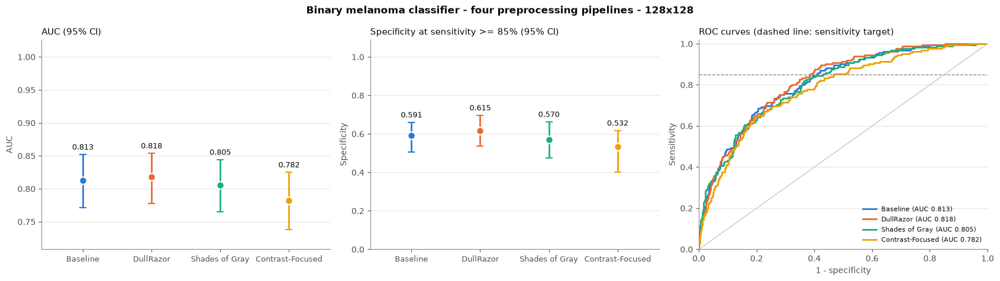

Figure saved to: /home/fabio-noriega/Coding/IST/Skin-cancer-detection-with-EfficientNet-CNN/runs_dataleakage_fixed/comparison_binary_128.png

Automatic conclusion based on the observed results
Selection rule: Among pipelines with sensitivity >= 85%, the highest specificity was selected; AUC and average precision break ties.
Selected pipeline: DullRazor | sensitivity=0.852, specificity=0.615, AUC=0.818, FN=24, FP=516.
Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.
- Baseline: the pipeline does not modify the image beyond resizing; it preserves the original colour, texture and borders and acts as the control; if it wins, the extra transformations added no measurable discriminative signal. These mechanisms are plausible but do not demonstrate causality.
- DullRazor: the pipeline removes thin dark linear structures consistent with hair (Black-Hat morphology and inpainting); it may help when hair occludes the lesion, but it may hurt if 

#### Binary classifier - 224x224 input

1503 validation images, 1120 clusters (lesion-level bootstrap, 1000 resamples).


**Results at a fixed minimum sensitivity of 85%**

,Pipeline,AUC [95% CI],Avg. precision,Lowest val_loss,Best epoch,Threshold,Sensitivity,Specificity [95% CI],Precision,FN,FP,Status
0,Baseline,"0.826 [0.784, 0.866]",0.431,0.316,8,0.200,0.852,"0.600 [0.506, 0.678]",0.204,24,537,sensitivity >= 85%
1,DullRazor,"0.842 [0.796, 0.879]",0.451,0.288,24,0.163,0.852,"0.677 [0.510, 0.743]",0.242,24,433,sensitivity >= 85%
2,Shades of Gray,"0.810 [0.765, 0.851]",0.418,0.304,20,0.119,0.852,"0.607 [0.449, 0.672]",0.208,24,527,sensitivity >= 85%
3,Contrast-Focused,"0.830 [0.786, 0.870]",0.416,0.305,21,0.149,0.852,"0.597 [0.522, 0.709]",0.203,24,541,sensitivity >= 85%


**Paired difference versus baseline** (95% bootstrap interval; *within noise* = interval contains 0)

,Pipeline,Δ AUC vs baseline,AUC verdict,Δ specificity vs baseline,Specificity verdict,Δ val_loss vs baseline
0,DullRazor,"+0.016 [-0.008, +0.041]",within noise,"+0.078 [-0.053, +0.170]",within noise,-0.028
1,Shades of Gray,"-0.016 [-0.036, +0.004]",within noise,"+0.007 [-0.089, +0.087]",within noise,-0.013
2,Contrast-Focused,"+0.004 [-0.026, +0.030]",within noise,"-0.003 [-0.068, +0.092]",within noise,-0.011


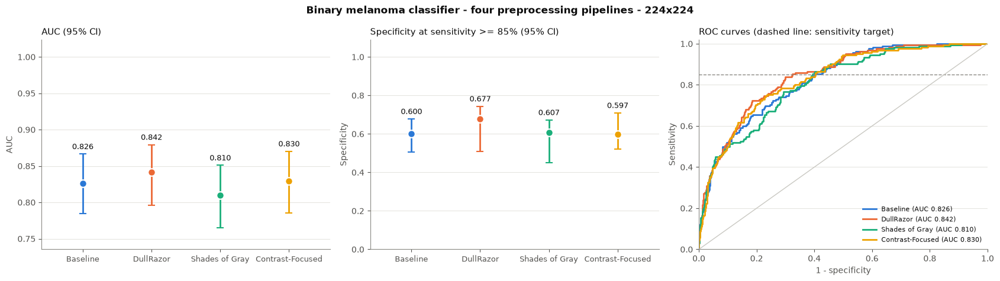

Figure saved to: /home/fabio-noriega/Coding/IST/Skin-cancer-detection-with-EfficientNet-CNN/runs_dataleakage_fixed/comparison_binary_224.png

Automatic conclusion based on the observed results
Selection rule: Among pipelines with sensitivity >= 85%, the highest specificity was selected; AUC and average precision break ties.
Selected pipeline: DullRazor | sensitivity=0.852, specificity=0.677, AUC=0.842, FN=24, FP=433.
Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.
- Baseline: the pipeline does not modify the image beyond resizing; it preserves the original colour, texture and borders and acts as the control; if it wins, the extra transformations added no measurable discriminative signal. These mechanisms are plausible but do not demonstrate causality.
- DullRazor: the pipeline removes thin dark linear structures consistent with hair (Black-Hat morphology and inpainting); it may help when hair occludes the lesion, but it may hurt if 

In [7]:
# 11.3 Binary classifier analysis
BINARY_RESULTS = {}
for res in sorted({k[1] for k in LATEST if k[0] == "binary"}):
    runs = [LATEST[("binary", res, p)] for p in PIPELINE_ORDER if ("binary", res, p) in LATEST]
    display(Markdown(f"#### Binary classifier - {res}x{res} input"))
    if len(runs) < 2:
        print("Fewer than two pipelines available; skipped.")
        continue
    common, aligned = aligned_preds(runs)
    groups, by_lesion = lesion_groups(common, runs[0]["config"])
    boots = boot_indices(groups)
    print(f"{len(common)} validation images, {len(set(groups))} clusters "
          f"({'lesion-level' if by_lesion else 'image-level: validation_metadata.csv not found'} bootstrap, {N_BOOT} resamples).")

    rows, boot, curves = [], {}, {}
    for run, d in zip(runs, aligned):
        y, p = d["y_real_mel"].astype(int).to_numpy(), d["p_mel"].to_numpy(dtype=float)
        s = binary_summary(y, p)
        auc_b, spec_b = binary_boot(y, p, boots)
        boot[run["pipeline"]], curves[run["pipeline"]] = dict(auc=auc_b, spec=spec_b), (y, p)
        (auc_lo, auc_hi), (spec_lo, spec_hi) = ci95(auc_b), ci95(spec_b)
        row = dict(pipeline=run["pipeline"], label=PIPELINE_LABELS[run["pipeline"]], auc_lo=auc_lo, auc_hi=auc_hi,
                   spec_lo=spec_lo, spec_hi=spec_hi, min_val_loss=run["min_val_loss"], best_epoch=run["best_epoch"], **s)
        rows.append(row)
        BINARY_RESULTS[(res, run["pipeline"])] = dict(row, specificity=s["specificity"])
    results = pd.DataFrame(rows)
    results["status"] = np.where(results["target_reached"], f"sensitivity >= {TARGET_SENSITIVITY:.0%}", "target not reached")

    table = pd.DataFrame({
        "Pipeline": results["label"],
        "AUC [95% CI]": [fmt_ci(r.auc, r.auc_lo, r.auc_hi) for r in results.itertuples()],
        "Avg. precision": results["average_precision"].round(3),
        "Lowest val_loss": results["min_val_loss"].round(3),
        "Best epoch": results["best_epoch"],
        "Threshold": results["threshold"].round(3),
        "Sensitivity": results["sensitivity"].round(3),
        "Specificity [95% CI]": [fmt_ci(r.specificity, r.spec_lo, r.spec_hi) for r in results.itertuples()],
        "Precision": results["precision"].round(3),
        "FN": results["fn"], "FP": results["fp"], "Status": results["status"],
    })
    display(Markdown(f"**Results at a fixed minimum sensitivity of {TARGET_SENSITIVITY:.0%}**"))
    display(table)

    winner_label, vs_base, verdict = None, "-", "-"
    if "baseline" in boot:
        drows = []
        for r in results.itertuples():
            if r.pipeline == "baseline":
                continue
            base = results.loc[results["pipeline"] == "baseline"].iloc[0]
            d_auc, v_auc = fmt_delta(r.auc - base["auc"], boot[r.pipeline]["auc"] - boot["baseline"]["auc"])
            d_spec, v_spec = fmt_delta(r.specificity - base["specificity"], boot[r.pipeline]["spec"] - boot["baseline"]["spec"])
            drows.append({"Pipeline": r.label, "Δ AUC vs baseline": d_auc, "AUC verdict": v_auc,
                          "Δ specificity vs baseline": d_spec, "Specificity verdict": v_spec,
                          "Δ val_loss vs baseline": f"{r.min_val_loss - base['min_val_loss']:+.3f}"})
        display(Markdown("**Paired difference versus baseline** (95% bootstrap interval; *within noise* = interval contains 0)"))
        display(pd.DataFrame(drows))

    eligible = results[results["target_reached"]]
    if eligible.empty:
        winner = results.sort_values(["sensitivity", "specificity"], ascending=False).iloc[0]
        rule = "No pipeline reached the target; the highest observed sensitivity was selected (ties broken by specificity)."
    else:
        winner = eligible.sort_values(["specificity", "auc", "average_precision"], ascending=False).iloc[0]
        rule = (f"Among pipelines with sensitivity >= {TARGET_SENSITIVITY:.0%}, the highest specificity was selected; "
                "AUC and average precision break ties.")
    if "baseline" in boot and winner["pipeline"] != "baseline":
        base = results.loc[results["pipeline"] == "baseline"].iloc[0]
        vs_base, verdict = fmt_delta(winner["specificity"] - base["specificity"],
                                     boot[winner["pipeline"]]["spec"] - boot["baseline"]["spec"])
    SUMMARY.append(dict(task="binary", input=f"{res}x{res}", criterion="specificity at sensitivity >= 85%",
                        selected=winner["label"], value=f"{winner['specificity']:.3f}",
                        delta_vs_baseline=vs_base, verdict=verdict))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    labels, colors = results["label"].tolist(), [PIPELINE_COLORS[p] for p in results["pipeline"]]
    lo_a = min(results["auc_lo"].min(), 0.9) - 0.03
    point_with_ci(axes[0], labels, results["auc"], results["auc_lo"], results["auc_hi"], colors,
                  "AUC (95% CI)", "AUC", ylim=(max(0.5, lo_a), 1.0))
    point_with_ci(axes[1], labels, results["specificity"], results["spec_lo"], results["spec_hi"], colors,
                  f"Specificity at sensitivity >= {TARGET_SENSITIVITY:.0%} (95% CI)", "Specificity", ylim=(0, 1.0))
    for r in results.itertuples():
        fpr, tpr, _ = roc_curve(*curves[r.pipeline])
        axes[2].plot(fpr, tpr, lw=2, color=PIPELINE_COLORS[r.pipeline], label=f"{r.label} (AUC {r.auc:.3f})")
    axes[2].axhline(TARGET_SENSITIVITY, color="#8a8983", ls="--", lw=1)
    axes[2].plot([0, 1], [0, 1], color="#c9c8c2", lw=1)
    axes[2].set(xlim=(0, 1), ylim=(0, 1.02), xlabel="1 - specificity", ylabel="Sensitivity")
    axes[2].set_title("ROC curves (dashed line: sensitivity target)", fontsize=11, loc="left")
    axes[2].legend(fontsize=8, loc="lower right", frameon=False)
    axes[2].grid(axis="x", visible=False)
    fig.suptitle(f"Binary melanoma classifier - four preprocessing pipelines - {res}x{res}", fontweight="bold")
    fig.tight_layout()
    out = RUNS_ROOT / f"comparison_binary_{res}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Figure saved to: {out.resolve()}")

    print("\nAutomatic conclusion based on the observed results")
    print("Selection rule:", rule)
    print(f"Selected pipeline: {winner['label']} | sensitivity={winner['sensitivity']:.3f}, specificity={winner['specificity']:.3f}, "
          f"AUC={winner['auc']:.3f}, FN={int(winner['fn'])}, FP={int(winner['fp'])}.")
    if verdict == "within noise":
        print("Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.")
    for r in results.itertuples():
        mech, caveat = MECHANISMS[r.pipeline]
        print(f"- {r.label}: the pipeline {mech}; {caveat}. These mechanisms are plausible but do not demonstrate causality.")

<h2 style="color: #0066cc;"><b>### 11.4 Multiclass classifier (7 classes)</b></h2>
Primary criterion: **macro-F1**. Balanced accuracy (mean recall over the 7 classes) and **melanoma recall** are shown with it; the share of melanomas predicted as `nv` is the most dangerous single confusion. Rare classes (`df`, `vasc`, `akiec`) have only a few dozen validation images, so their per-class numbers are noisy; read the heatmap with that in mind.

#### Multiclass classifier - 128x128 input

1503 validation images, 1120 clusters (lesion-level bootstrap, 1000 resamples).


,akiec,bcc,bkl,df,mel,nv,vasc
validation images,67,74,172,18,162,988,22


**Overall and melanoma-specific metrics**

,Pipeline,Macro-F1 [95% CI],Balanced acc. [95% CI],Weighted-F1,Accuracy,Macro AUC (OvR),Mel recall [95% CI],Mel precision,Mel predicted as nv,Lowest val_loss,Best epoch
0,Baseline,"0.476 [0.424, 0.523]","0.476 [0.425, 0.537]",0.722,0.717,0.885,"0.395 [0.303, 0.490]",0.421,35.2 %,0.798,24
1,DullRazor,"0.459 [0.407, 0.507]","0.465 [0.411, 0.532]",0.704,0.696,0.893,"0.395 [0.298, 0.485]",0.381,32.1 %,0.810,28
2,Shades of Gray,"0.489 [0.434, 0.536]","0.481 [0.423, 0.540]",0.732,0.732,0.901,"0.389 [0.294, 0.474]",0.460,38.9 %,0.753,28
3,Contrast-Focused,"0.449 [0.394, 0.501]","0.461 [0.400, 0.530]",0.709,0.703,0.884,"0.395 [0.308, 0.483]",0.379,34.0 %,0.836,24


**Paired difference versus baseline** (95% bootstrap interval)

,Pipeline,Δ Macro-F1,Macro-F1 verdict,Δ Balanced acc.,Balanced acc. verdict,Δ Mel recall,Mel recall verdict
0,DullRazor,"-0.017 [-0.064, +0.029]",within noise,"-0.012 [-0.055, +0.032]",within noise,"+0.000 [-0.072, +0.075]",within noise
1,Shades of Gray,"+0.013 [-0.021, +0.055]",within noise,"+0.005 [-0.035, +0.047]",within noise,"-0.006 [-0.068, +0.055]",within noise
2,Contrast-Focused,"-0.027 [-0.079, +0.027]",within noise,"-0.015 [-0.075, +0.041]",within noise,"+0.000 [-0.082, +0.083]",within noise


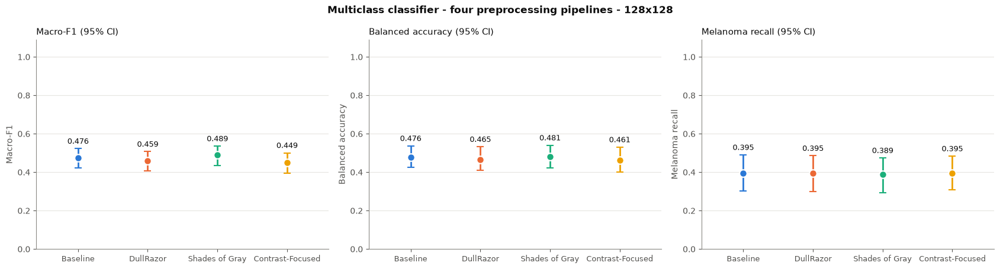

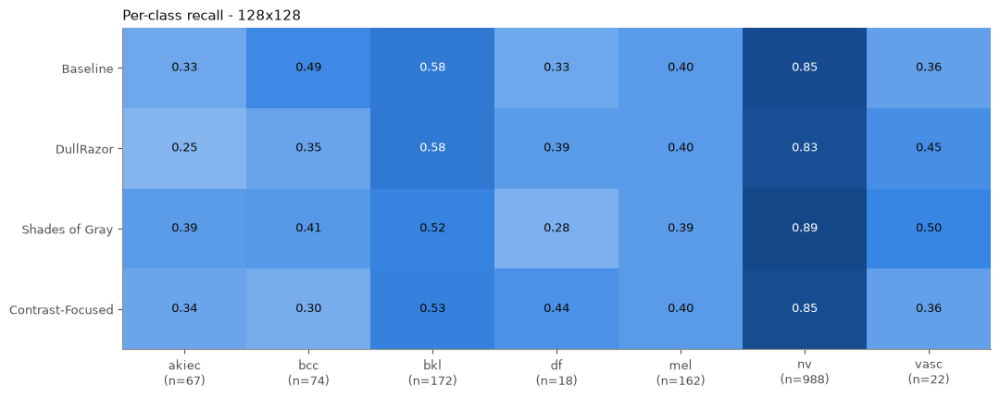

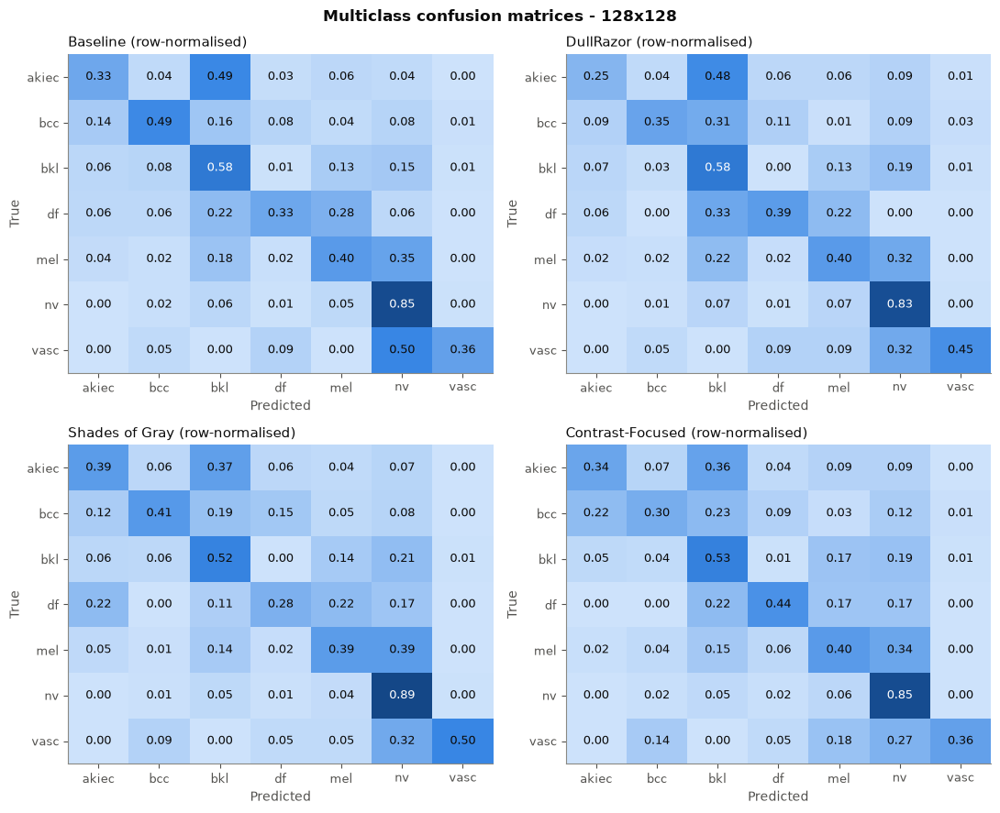

Automatic conclusion based on the observed results
Selection rule: highest macro-F1 (ties by balanced accuracy). Selected: Shades of Gray | macro-F1=0.489, balanced accuracy=0.481, melanoma recall=0.389.
Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.
Accuracy (0.696-0.732) is dominated by the nv class and is not used for selection.


#### Multiclass classifier - 224x224 input

1503 validation images, 1120 clusters (lesion-level bootstrap, 1000 resamples).


,akiec,bcc,bkl,df,mel,nv,vasc
validation images,67,74,172,18,162,988,22


**Overall and melanoma-specific metrics**

,Pipeline,Macro-F1 [95% CI],Balanced acc. [95% CI],Weighted-F1,Accuracy,Macro AUC (OvR),Mel recall [95% CI],Mel precision,Mel predicted as nv,Lowest val_loss,Best epoch
0,Baseline,"0.498 [0.451, 0.539]","0.513 [0.460, 0.570]",0.725,0.712,0.903,"0.519 [0.414, 0.618]",0.429,21.6 %,0.774,28
1,DullRazor,"0.518 [0.461, 0.562]","0.539 [0.477, 0.599]",0.734,0.725,0.908,"0.457 [0.355, 0.550]",0.443,29.0 %,0.744,23
2,Shades of Gray,"0.523 [0.473, 0.565]","0.549 [0.492, 0.609]",0.731,0.723,0.910,"0.426 [0.330, 0.519]",0.493,32.7 %,0.759,28
3,Contrast-Focused,"0.511 [0.462, 0.555]","0.535 [0.475, 0.594]",0.735,0.724,0.909,"0.512 [0.421, 0.601]",0.437,29.6 %,0.761,30


**Paired difference versus baseline** (95% bootstrap interval)

,Pipeline,Δ Macro-F1,Macro-F1 verdict,Δ Balanced acc.,Balanced acc. verdict,Δ Mel recall,Mel recall verdict
0,DullRazor,"+0.020 [-0.029, +0.064]",within noise,"+0.026 [-0.032, +0.078]",within noise,"-0.062 [-0.159, +0.029]",within noise
1,Shades of Gray,"+0.026 [-0.016, +0.065]",within noise,"+0.036 [-0.008, +0.083]",within noise,"-0.093 [-0.163, -0.026]",distinguishable
2,Contrast-Focused,"+0.013 [-0.032, +0.056]",within noise,"+0.022 [-0.026, +0.069]",within noise,"-0.006 [-0.097, +0.087]",within noise


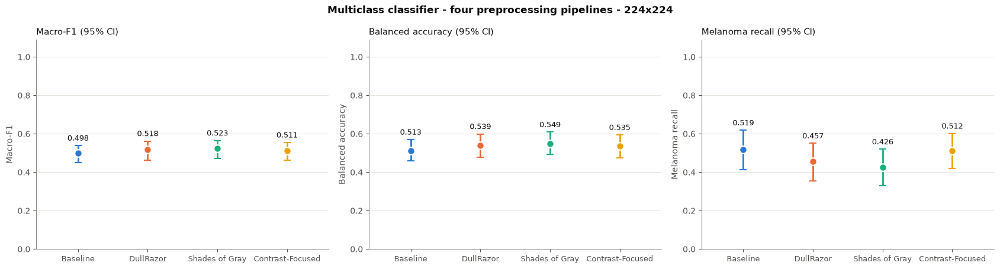

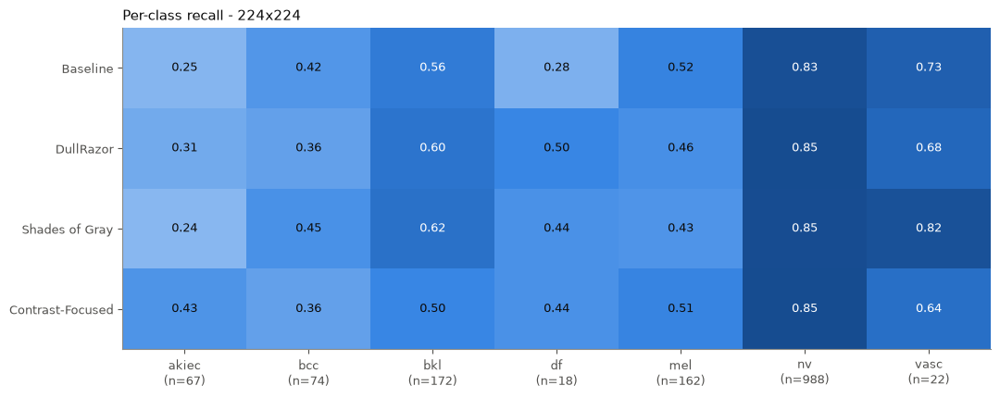

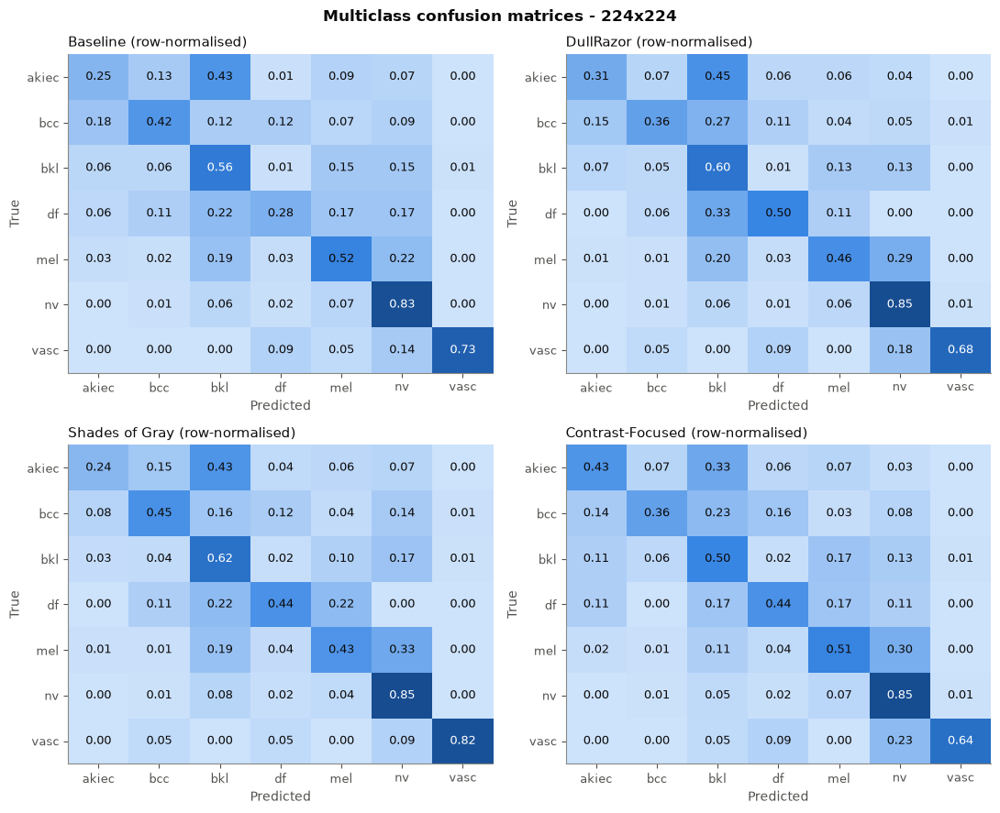

Automatic conclusion based on the observed results
Selection rule: highest macro-F1 (ties by balanced accuracy). Selected: Shades of Gray | macro-F1=0.523, balanced accuracy=0.549, melanoma recall=0.426.
Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.
Accuracy (0.712-0.725) is dominated by the nv class and is not used for selection.


In [8]:
# 11.4 Multiclass classifier analysis
MC_RESULTS = {}
for res in sorted({k[1] for k in LATEST if k[0] == "multiclass"}):
    runs = [LATEST[("multiclass", res, p)] for p in PIPELINE_ORDER if ("multiclass", res, p) in LATEST]
    display(Markdown(f"#### Multiclass classifier - {res}x{res} input"))
    if len(runs) < 2:
        print("Fewer than two pipelines available; skipped.")
        continue
    common, aligned = aligned_preds(runs)
    groups, by_lesion = lesion_groups(common, runs[0]["config"])
    boots = boot_indices(groups)
    arrays = [mc_arrays(d) for d in aligned]
    classes = arrays[0][0]
    assert all(a[0] == classes for a in arrays), "Runs disagree on the class list."
    k = len(classes)
    mel, nv = (classes.index("mel") if "mel" in classes else None), (classes.index("nv") if "nv" in classes else None)
    print(f"{len(common)} validation images, {len(set(groups))} clusters "
          f"({'lesion-level' if by_lesion else 'image-level'} bootstrap, {N_BOOT} resamples).")
    support = pd.Series(np.bincount(arrays[0][1], minlength=k), index=classes, name="validation images")
    display(support.to_frame().T)

    rows, boot = [], {}
    for run, (_, y, pred, probs) in zip(runs, arrays):
        cm = confusion(y, pred, k)
        s = mc_scores(cm, mel, nv)
        aucs = ovr_auc(y, probs)
        b = mc_boot(y, pred, k, mel, boots)
        boot[run["pipeline"]] = b
        cis = {key: ci95(b[key]) for key in b}
        MC_RESULTS[(res, run["pipeline"])] = dict(
            macro_f1=s["macro_f1"], macro_f1_lo=cis["macro_f1"][0], macro_f1_hi=cis["macro_f1"][1],
            balanced_accuracy=s["balanced_accuracy"], balanced_accuracy_lo=cis["balanced_accuracy"][0],
            balanced_accuracy_hi=cis["balanced_accuracy"][1], mel_recall=s["mel_recall"],
            mel_recall_lo=cis["mel_recall"][0], mel_recall_hi=cis["mel_recall"][1])
        rows.append(dict(pipeline=run["pipeline"], label=PIPELINE_LABELS[run["pipeline"]], cm=cm, recall=s["recall"],
                         macro_auc=float(np.nanmean(aucs)), min_val_loss=run["min_val_loss"], best_epoch=run["best_epoch"],
                         **{key: s[key] for key in ("accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
                                                    "mel_recall", "mel_precision", "mel_to_nv")},
                         **{f"{key}_lo": cis[key][0] for key in cis}, **{f"{key}_hi": cis[key][1] for key in cis}))
    res_df = pd.DataFrame(rows)

    table = pd.DataFrame({
        "Pipeline": res_df["label"],
        "Macro-F1 [95% CI]": [fmt_ci(r.macro_f1, r.macro_f1_lo, r.macro_f1_hi) for r in res_df.itertuples()],
        "Balanced acc. [95% CI]": [fmt_ci(r.balanced_accuracy, r.balanced_accuracy_lo, r.balanced_accuracy_hi) for r in res_df.itertuples()],
        "Weighted-F1": res_df["weighted_f1"].round(3),
        "Accuracy": res_df["accuracy"].round(3),
        "Macro AUC (OvR)": res_df["macro_auc"].round(3),
        "Mel recall [95% CI]": [fmt_ci(r.mel_recall, r.mel_recall_lo, r.mel_recall_hi) for r in res_df.itertuples()],
        "Mel precision": res_df["mel_precision"].round(3),
        "Mel predicted as nv": (res_df["mel_to_nv"] * 100).round(1).astype(str) + " %",
        "Lowest val_loss": res_df["min_val_loss"].round(3),
        "Best epoch": res_df["best_epoch"],
    })
    display(Markdown("**Overall and melanoma-specific metrics**"))
    display(table)

    winner = res_df.sort_values(["macro_f1", "balanced_accuracy"], ascending=False).iloc[0]
    vs_base, verdict = "-", "-"
    if "baseline" in boot:
        drows = []
        base = res_df.loc[res_df["pipeline"] == "baseline"].iloc[0]
        for r in res_df.itertuples():
            if r.pipeline == "baseline":
                continue
            row = {"Pipeline": r.label}
            for key, name in (("macro_f1", "Macro-F1"), ("balanced_accuracy", "Balanced acc."), ("mel_recall", "Mel recall")):
                d, v = fmt_delta(getattr(r, key) - base[key], boot[r.pipeline][key] - boot["baseline"][key])
                row[f"Δ {name}"], row[f"{name} verdict"] = d, v
            drows.append(row)
        display(Markdown("**Paired difference versus baseline** (95% bootstrap interval)"))
        display(pd.DataFrame(drows))
        if winner["pipeline"] != "baseline":
            vs_base, verdict = fmt_delta(winner["macro_f1"] - base["macro_f1"],
                                         boot[winner["pipeline"]]["macro_f1"] - boot["baseline"]["macro_f1"])
    SUMMARY.append(dict(task="multiclass", input=f"{res}x{res}", criterion="macro-F1", selected=winner["label"],
                        value=f"{winner['macro_f1']:.3f}", delta_vs_baseline=vs_base, verdict=verdict))

    labels, colors = res_df["label"].tolist(), [PIPELINE_COLORS[p] for p in res_df["pipeline"]]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for ax, (key, title) in zip(axes, (("macro_f1", "Macro-F1 (95% CI)"), ("balanced_accuracy", "Balanced accuracy (95% CI)"),
                                       ("mel_recall", "Melanoma recall (95% CI)"))):
        point_with_ci(ax, labels, res_df[key], res_df[f"{key}_lo"], res_df[f"{key}_hi"], colors, title,
                      title.split(" (")[0], ylim=(0, 1.0))
    fig.suptitle(f"Multiclass classifier - four preprocessing pipelines - {res}x{res}", fontweight="bold")
    fig.tight_layout()
    fig.savefig(RUNS_ROOT / f"comparison_multiclass_{res}.png", dpi=200, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(1.1 * k + 3.2, 0.7 * len(res_df) + 1.6))
    heatmap(ax, np.vstack(res_df["recall"].to_numpy()), [f"{c}\n(n={int(n)})" for c, n in zip(classes, support)],
            labels, f"Per-class recall - {res}x{res}")
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for ax, r in zip(axes.ravel(), res_df.itertuples()):
        norm = r.cm / r.cm.sum(axis=1, keepdims=True)
        heatmap(ax, norm, classes, classes, f"{r.label} (row-normalised)", fmt="{:.2f}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    for ax in axes.ravel()[len(res_df):]:
        ax.axis("off")
    fig.suptitle(f"Multiclass confusion matrices - {res}x{res}", fontweight="bold")
    fig.tight_layout()
    plt.show()

    print("Automatic conclusion based on the observed results")
    print(f"Selection rule: highest macro-F1 (ties by balanced accuracy). Selected: {winner['label']} | macro-F1={winner['macro_f1']:.3f}, "
          f"balanced accuracy={winner['balanced_accuracy']:.3f}, melanoma recall={winner['mel_recall']:.3f}.")
    if verdict == "within noise":
        print("Its advantage over the baseline is within bootstrap noise: the data do not support calling it better.")
    print(f"Accuracy ({res_df['accuracy'].min():.3f}-{res_df['accuracy'].max():.3f}) is dominated by the nv class and is not used for selection.")

<h2 style="color: #0066cc;"><b>### 11.5 Effect of the input resolution</b></h2>
The same four pipelines at two resolutions. Hollow marker = smaller input, filled marker = larger input. The paired table gives the change (larger minus smaller) with a 95% lesion-level bootstrap interval, evaluated on identical validation images and resamples.

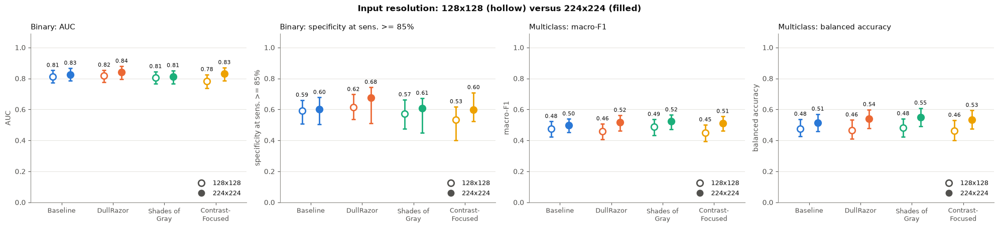

**Paired change from the smaller to the larger input**

,Task,Pipeline,Metric,128x128,224x224,Δ (224 - 128) [95% CI],Verdict
0,binary,Baseline,AUC,0.813,0.826,"+0.013 [-0.014, +0.039]",within noise
1,binary,Baseline,Specificity at sens. >= 85%,0.591,0.600,"+0.008 [-0.078, +0.084]",within noise
2,binary,DullRazor,AUC,0.818,0.842,"+0.024 [-0.004, +0.048]",within noise
3,binary,DullRazor,Specificity at sens. >= 85%,0.615,0.677,"+0.062 [-0.094, +0.127]",within noise
4,binary,Shades of Gray,AUC,0.805,0.810,"+0.005 [-0.026, +0.034]",within noise
5,binary,Shades of Gray,Specificity at sens. >= 85%,0.570,0.607,"+0.037 [-0.078, +0.115]",within noise
6,binary,Contrast-Focused,AUC,0.782,0.830,"+0.048 [+0.014, +0.079]",distinguishable
7,binary,Contrast-Focused,Specificity at sens. >= 85%,0.532,0.597,"+0.064 [-0.015, +0.200]",within noise
8,multiclass,Baseline,Macro-F1,0.476,0.498,"+0.022 [-0.029, +0.073]",within noise
9,multiclass,Baseline,Balanced accuracy,0.476,0.513,"+0.036 [-0.024, +0.092]",within noise


8 of 20 paired differences have a 95% interval that excludes 0; the rest are within noise. Resolution also changes training time and memory, which this table does not capture.


In [9]:
# 11.5 Resolution comparison (smallest versus largest resolution found)
resolutions = sorted({k[1] for k in LATEST})
if len(resolutions) < 2 or not (BINARY_RESULTS or MC_RESULTS):
    print("Need runs at two resolutions and cells 11.3/11.4 executed first.")
else:
    lo_res, hi_res = resolutions[0], resolutions[-1]
    drows = []
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
    pipes_b = [p for p in PIPELINE_ORDER if ("binary", lo_res, p) in LATEST and ("binary", hi_res, p) in LATEST]
    pipes_m = [p for p in PIPELINE_ORDER if ("multiclass", lo_res, p) in LATEST and ("multiclass", hi_res, p) in LATEST]

    for p in pipes_b:
        ra, rb = LATEST[("binary", lo_res, p)], LATEST[("binary", hi_res, p)]
        common, (da, db) = aligned_preds([ra, rb])
        groups, _ = lesion_groups(common, ra["config"])
        boots = boot_indices(groups)
        y = da["y_real_mel"].astype(int).to_numpy()
        pa, pb = da["p_mel"].to_numpy(dtype=float), db["p_mel"].to_numpy(dtype=float)
        sa, sb = binary_summary(y, pa), binary_summary(y, pb)
        auc_a, spec_a = binary_boot(y, pa, boots)
        auc_b, spec_b = binary_boot(y, pb, boots)
        for name, va, vb, ba, bb in (("AUC", sa["auc"], sb["auc"], auc_a, auc_b),
                                     ("Specificity at sens. >= 85%", sa["specificity"], sb["specificity"], spec_a, spec_b)):
            d, v = fmt_delta(vb - va, bb - ba)
            drows.append({"Task": "binary", "Pipeline": PIPELINE_LABELS[p], "Metric": name,
                          f"{lo_res}x{lo_res}": round(va, 3), f"{hi_res}x{hi_res}": round(vb, 3),
                          f"Δ ({hi_res} - {lo_res}) [95% CI]": d, "Verdict": v})

    for p in pipes_m:
        ra, rb = LATEST[("multiclass", lo_res, p)], LATEST[("multiclass", hi_res, p)]
        common, (da, db) = aligned_preds([ra, rb])
        groups, _ = lesion_groups(common, ra["config"])
        boots = boot_indices(groups)
        (classes, y, pred_a, _), (_, _, pred_b, _) = mc_arrays(da), mc_arrays(db)
        k, mel = len(classes), classes.index("mel") if "mel" in classes else None
        sa, sb = mc_scores(confusion(y, pred_a, k), mel), mc_scores(confusion(y, pred_b, k), mel)
        ba, bb = mc_boot(y, pred_a, k, mel, boots), mc_boot(y, pred_b, k, mel, boots)
        for key, name in (("macro_f1", "Macro-F1"), ("balanced_accuracy", "Balanced accuracy"), ("mel_recall", "Melanoma recall")):
            d, v = fmt_delta(sb[key] - sa[key], bb[key] - ba[key])
            drows.append({"Task": "multiclass", "Pipeline": PIPELINE_LABELS[p], "Metric": name,
                          f"{lo_res}x{lo_res}": round(sa[key], 3), f"{hi_res}x{hi_res}": round(sb[key], 3),
                          f"Δ ({hi_res} - {lo_res}) [95% CI]": d, "Verdict": v})

    def pick(store, key, p, res):
        r = store[(res, p)]
        return r[key], r[f"{key}_lo"], r[f"{key}_hi"]

    panels = [(axes[0], BINARY_RESULTS, "auc", pipes_b, "Binary: AUC"),
              (axes[1], BINARY_RESULTS, "specificity", pipes_b, "Binary: specificity at sens. >= 85%"),
              (axes[2], MC_RESULTS, "macro_f1", pipes_m, "Multiclass: macro-F1"),
              (axes[3], MC_RESULTS, "balanced_accuracy", pipes_m, "Multiclass: balanced accuracy")]
    for ax, store, key, pipes, title in panels:
        if not pipes:
            ax.axis("off")
            continue
        key_lo = "spec" if key == "specificity" else key
        a = [(store[(lo_res, p)][key], store[(lo_res, p)][f"{key_lo}_lo"], store[(lo_res, p)][f"{key_lo}_hi"]) for p in pipes]
        b = [(store[(hi_res, p)][key], store[(hi_res, p)][f"{key_lo}_lo"], store[(hi_res, p)][f"{key_lo}_hi"]) for p in pipes]
        paired_dot_plot(ax, [PIPELINE_WRAPPED[p] for p in pipes], a, b, [PIPELINE_COLORS[p] for p in pipes],
                        f"{lo_res}x{lo_res}", f"{hi_res}x{hi_res}", title, title.split(": ")[-1], ylim=(0, 1.0))
    fig.suptitle(f"Input resolution: {lo_res}x{lo_res} (hollow) versus {hi_res}x{hi_res} (filled)", fontweight="bold")
    fig.tight_layout()
    fig.savefig(RUNS_ROOT / "comparison_resolution.png", dpi=200, bbox_inches="tight")
    plt.show()

    display(Markdown("**Paired change from the smaller to the larger input**"))
    display(pd.DataFrame(drows))
    n_dist = sum(r["Verdict"] == "distinguishable" for r in drows)
    print(f"{n_dist} of {len(drows)} paired differences have a 95% interval that excludes 0; the rest are within noise. "
          "Resolution also changes training time and memory, which this table does not capture.")

<h2 style="color: #0066cc;"><b>### 11.6 Binary classifier versus multiclass classifier as a melanoma detector</b></h2>
The multiclass model also outputs P(mel), so it can be evaluated with exactly the same rule as the binary one (highest specificity with sensitivity >= 85%) on the same validation images. This answers whether the dedicated binary head is worth training. The difference (binary minus multiclass) is paired and uses lesion-level bootstrap.

,Input,Pipeline,AUC binary,AUC multiclass P(mel),Δ AUC (bin - mc),AUC verdict,Spec. binary,Spec. multiclass,Sens. binary / mc,Δ specificity (bin - mc),Specificity verdict
0,128x128,Baseline,0.813,0.817,"-0.005 [-0.030, +0.020]",within noise,0.591,0.598,0.85 / 0.85,"-0.007 [-0.084, +0.061]",within noise
1,128x128,DullRazor,0.818,0.815,"+0.003 [-0.017, +0.022]",within noise,0.615,0.658,0.85 / 0.85,"-0.043 [-0.093, +0.093]",within noise
2,128x128,Shades of Gray,0.805,0.818,"-0.013 [-0.034, +0.010]",within noise,0.570,0.607,0.85 / 0.85,"-0.037 [-0.119, +0.064]",within noise
3,128x128,Contrast-Focused,0.782,0.802,"-0.020 [-0.040, +0.002]",within noise,0.532,0.611,0.85 / 0.85,"-0.079 [-0.159, +0.004]",within noise
4,224x224,Baseline,0.826,0.853,"-0.027 [-0.049, -0.003]",distinguishable,0.600,0.665,0.85 / 0.85,"-0.066 [-0.138, +0.005]",within noise
5,224x224,DullRazor,0.842,0.848,"-0.006 [-0.025, +0.013]",within noise,0.677,0.687,0.85 / 0.85,"-0.010 [-0.144, +0.035]",within noise
6,224x224,Shades of Gray,0.810,0.836,"-0.026 [-0.054, +0.003]",within noise,0.607,0.635,0.85 / 0.85,"-0.028 [-0.151, +0.078]",within noise
7,224x224,Contrast-Focused,0.830,0.839,"-0.009 [-0.028, +0.010]",within noise,0.597,0.666,0.85 / 0.85,"-0.069 [-0.118, +0.035]",within noise


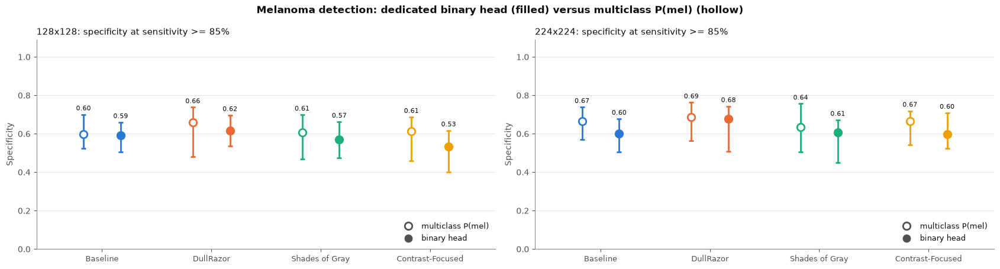

0 of 8 specificity differences between the two heads are distinguishable from 0. The multiclass model is trained with a different loss and class weights, so this compares complete systems, not just heads.


In [10]:
# 11.6 Binary versus multiclass for melanoma detection
rows, plot_data = [], {}
for res in sorted({k[1] for k in LATEST}):
    for p in PIPELINE_ORDER:
        if ("binary", res, p) not in LATEST or ("multiclass", res, p) not in LATEST:
            continue
        rb, rm = LATEST[("binary", res, p)], LATEST[("multiclass", res, p)]
        common, (db, dm) = aligned_preds([rb, rm])
        y = db["y_real_mel"].astype(int).to_numpy()
        if "prob_mel" not in dm.columns or not np.array_equal(y, (dm["clase_real"] == "mel").astype(int).to_numpy()):
            print(f"Skipping {res} {p}: validation labels of the two runs disagree.")
            continue
        p_bin, p_mc = db["p_mel"].to_numpy(dtype=float), dm["prob_mel"].to_numpy(dtype=float)
        groups, _ = lesion_groups(common, rb["config"])
        boots = boot_indices(groups)
        sb, sm = binary_summary(y, p_bin), binary_summary(y, p_mc)
        auc_b, spec_b = binary_boot(y, p_bin, boots)
        auc_m, spec_m = binary_boot(y, p_mc, boots)
        d_auc, v_auc = fmt_delta(sb["auc"] - sm["auc"], auc_b - auc_m)
        d_spec, v_spec = fmt_delta(sb["specificity"] - sm["specificity"], spec_b - spec_m)
        rows.append({"Input": f"{res}x{res}", "Pipeline": PIPELINE_LABELS[p],
                     "AUC binary": round(sb["auc"], 3), "AUC multiclass P(mel)": round(sm["auc"], 3),
                     "Δ AUC (bin - mc)": d_auc, "AUC verdict": v_auc,
                     "Spec. binary": round(sb["specificity"], 3), "Spec. multiclass": round(sm["specificity"], 3),
                     "Sens. binary / mc": f"{sb['sensitivity']:.2f} / {sm['sensitivity']:.2f}",
                     "Δ specificity (bin - mc)": d_spec, "Specificity verdict": v_spec})
        plot_data.setdefault(res, {})[p] = ((sb["specificity"], *ci95(spec_b)), (sm["specificity"], *ci95(spec_m)))

if not rows:
    print("No (resolution, pipeline) combination has both a binary and a multiclass run.")
else:
    display(pd.DataFrame(rows))
    fig, axes = plt.subplots(1, len(plot_data), figsize=(8.5 * len(plot_data), 4.6), squeeze=False)
    for ax, (res, d) in zip(axes[0], plot_data.items()):
        pipes = [p for p in PIPELINE_ORDER if p in d]
        paired_dot_plot(ax, [PIPELINE_LABELS[p] for p in pipes], [d[p][1] for p in pipes], [d[p][0] for p in pipes],
                        [PIPELINE_COLORS[p] for p in pipes], "multiclass P(mel)", "binary head",
                        f"{res}x{res}: specificity at sensitivity >= {TARGET_SENSITIVITY:.0%}", "Specificity", ylim=(0, 1.0))
    fig.suptitle("Melanoma detection: dedicated binary head (filled) versus multiclass P(mel) (hollow)", fontweight="bold")
    fig.tight_layout()
    fig.savefig(RUNS_ROOT / "comparison_binary_vs_multiclass.png", dpi=200, bbox_inches="tight")
    plt.show()
    n_dist = sum(r["Specificity verdict"] == "distinguishable" for r in rows)
    print(f"{n_dist} of {len(rows)} specificity differences between the two heads are distinguishable from 0. "
          "The multiclass model is trained with a different loss and class weights, so this compares complete systems, not just heads.")

<h2 style="color: #0066cc;"><b>### 11.7 Before versus after the leakage fix (optional)</b></h2>
Compares the earlier runs in `runs/` with the new ones at the same resolution. **This is not a paired or controlled comparison**: besides removing leakage, the validation set changed (a different split and size), so the two sets of numbers answer different questions. Use it as context, not as a measurement of how much leakage inflated the results.

In [11]:
# 11.7 Before versus after (descriptive only)
old_runs, _ = discover_runs(OLD_RUNS_DIR)
OLD_LATEST, _ = select_latest(old_runs)
if not old_runs:
    print(f"No earlier runs found under {OLD_RUNS_DIR.resolve()}; skipping.")
else:
    rows = []
    for (task, res, p), new in sorted(LATEST.items(), key=lambda kv: (kv[0][0], kv[0][1], PIPELINE_ORDER.index(kv[0][2]))):
        old = OLD_LATEST.get((task, res, p))
        if old is None:
            continue
        if task == "binary":
            so = binary_summary(old["preds"]["y_real_mel"].astype(int).to_numpy(), old["preds"]["p_mel"].to_numpy(dtype=float))
            sn = binary_summary(new["preds"]["y_real_mel"].astype(int).to_numpy(), new["preds"]["p_mel"].to_numpy(dtype=float))
            metrics_pairs = (("AUC", so["auc"], sn["auc"]), ("Specificity at sens. >= 85%", so["specificity"], sn["specificity"]))
        else:
            vals = []
            for r in (old, new):
                classes, y, pred, _ = mc_arrays(r["preds"])
                vals.append(mc_scores(confusion(y, pred, len(classes))))
            metrics_pairs = (("Macro-F1", vals[0]["macro_f1"], vals[1]["macro_f1"]),
                             ("Balanced accuracy", vals[0]["balanced_accuracy"], vals[1]["balanced_accuracy"]))
        for name, before, after in metrics_pairs:
            rows.append({"Task": task, "Input": f"{res}x{res}", "Pipeline": PIPELINE_LABELS[p], "Metric": name,
                         "Before": round(before, 3), "After": round(after, 3), "Change": f"{after - before:+.3f}",
                         "n_val before / after": f"{len(old['preds'])} / {len(new['preds'])}"})
    if rows:
        display(pd.DataFrame(rows))
        print("Reminder: before and after use different validation sets, so a change here mixes leakage removal with a new split.")
    else:
        print("The earlier runs do not match any (task, resolution, pipeline) of the new runs.")

,Task,Input,Pipeline,Metric,Before,After,Change,n_val before / after
0,binary,128x128,Baseline,AUC,0.826,0.813,-0.013,2024 / 1503
1,binary,128x128,Baseline,Specificity at sens. >= 85%,0.628,0.591,-0.037,2024 / 1503
2,binary,128x128,DullRazor,AUC,0.823,0.818,-0.005,2024 / 1503
3,binary,128x128,DullRazor,Specificity at sens. >= 85%,0.643,0.615,-0.028,2024 / 1503
4,binary,128x128,Shades of Gray,AUC,0.806,0.805,-0.001,2024 / 1503
5,binary,128x128,Shades of Gray,Specificity at sens. >= 85%,0.574,0.570,-0.003,2024 / 1503
6,binary,128x128,Contrast-Focused,AUC,0.820,0.782,-0.038,2024 / 1503
7,binary,128x128,Contrast-Focused,Specificity at sens. >= 85%,0.619,0.532,-0.087,2024 / 1503
8,binary,224x224,Baseline,AUC,0.833,0.826,-0.007,2024 / 1503
9,binary,224x224,Baseline,Specificity at sens. >= 85%,0.615,0.600,-0.015,2024 / 1503


Reminder: before and after use different validation sets, so a change here mixes leakage removal with a new split.


### 11.8 Summary
One line per task and resolution with the pipeline selected by the pre-declared rule, and whether its advantage over the baseline is distinguishable from noise.

In [12]:
# 11.8 Summary of the selections
if not SUMMARY:
    print("Run cells 11.3 and 11.4 first.")
else:
    summary = pd.DataFrame(SUMMARY).rename(columns={"input": "Input", "task": "Task", "criterion": "Selection criterion",
                                                    "selected": "Selected pipeline", "value": "Value",
                                                    "delta_vs_baseline": "Δ vs baseline [95% CI]", "verdict": "Verdict"})
    display(summary)
    noise = summary["Verdict"].eq("within noise").sum()
    base_wins = summary["Selected pipeline"].eq(PIPELINE_LABELS["baseline"]).sum()
    print(f"{base_wins} of {len(summary)} selections are the baseline itself, and {noise} selected pipelines beat the baseline only within noise.")
    print("Interpretation: a preprocessing pipeline is only supported by these data where its paired interval excludes 0.")
    print("Before reporting any of these numbers, evaluate the chosen configuration once on the untouched test/ split:")
    print("validation was used to pick the best epoch (and the binary threshold), so the values above are optimistic.")

Run cells 11.3 and 11.4 first.


<h2 style="color: #0066cc;"><b># **11.9 INDEPENDENT TEST SET EVALUATION**</b><h2>
# Multiclass classification — 224 x 224

In [ ]:
# 11.9 INDEPENDENT TEST SET EVALUATION
# Multiclass classification — 224 x 224


from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from preprocessing import preprocess_pipeline

/home/fabio-noriega/anaconda3/envs/ist_ML/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# 1. Configuration


TEST_DATASET_DIR = Path("Datasets_safe")
TEST_IMAGES_DIR = TEST_DATASET_DIR / "test"

TEST_METADATA_PATH = (
    TEST_DATASET_DIR / "test_metadata.csv"
)

TEST_RESOLUTION = 224

CLASSES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

PIPELINE_METHODS = {
    "baseline": "baseline",
    "dullrazor": "hair_removal",
    "shades_of_gray": "color_constancy",
    "dullrazor_clahe": "contrast_focused"
}

RESULTS_DIR = RUNS_ROOT / "independent_test_224"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert TEST_IMAGES_DIR.is_dir(), (
    "Independent test directory not found."
)

assert TEST_METADATA_PATH.exists(), (
    "Test metadata file not found."
)

In [ ]:

# 2. Verify dataset integrity


train_meta = pd.read_csv(
    TEST_DATASET_DIR / "training_metadata.csv"
)

val_meta = pd.read_csv(
    TEST_DATASET_DIR / "validation_metadata.csv"
)

test_meta = pd.read_csv(
    TEST_METADATA_PATH
)

assert test_meta["image_id"].is_unique

for previous_meta in [train_meta, val_meta]:

    assert set(
        previous_meta["lesion_id"]
    ).isdisjoint(
        set(test_meta["lesion_id"])
    ), "DATA LEAKAGE: overlapping lesion IDs!"

print("Dataset integrity: OK")
print("Independent test images:", len(test_meta))
print(
    "Independent test lesions:",
    test_meta["lesion_id"].nunique()
)

Dataset integrity: OK
Independent test images: 1510
Independent test lesions: 1121


In [ ]:

# 3. Locate the test images


test_paths = []

for row in test_meta.itertuples(index=False):

    image_path = (
        TEST_IMAGES_DIR /
        row.dx /
        f"{row.image_id}.jpg"
    )

    if not image_path.exists():
        raise FileNotFoundError(
            f"Missing test image: {image_path}"
        )

    test_paths.append(image_path)

assert len(test_paths) == len(test_meta)

y_true = np.array([
    CLASSES.index(label)
    for label in test_meta["dx"]
])

print("Test images located successfully.")


Test images located successfully.


In [ ]:

# 4. Image loading and preprocessing


def load_test_images(paths, method, image_size):

    """
    Load RGB test images.

    The preprocessing method must match the method
    used during model training.

    Assumes Datasets_safe contains baseline-prepared
    images, without preprocessing-specific transformations.
    """

    images = []

    for image_path in tqdm(
        paths,
        desc=f"Loading {method}"
    ):

        img = cv2.imread(str(image_path))

        if img is None:
            raise ValueError(
                f"Cannot read image: {image_path}"
            )

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        if method == "baseline":

            img = cv2.resize(
                img,
                (image_size, image_size),
                interpolation=cv2.INTER_AREA
            )

        else:

            img = preprocess_pipeline(
                img,
                target_size=(
                    image_size,
                    image_size
                ),
                method=method
            )

        images.append(img)

    return np.asarray(
        images,
        dtype=np.uint8
    )



Pipeline: Baseline
Run: Exp_MC_Baseline_20261020_151929


Loading baseline: 100%|██████████| 1510/1510 [00:00<00:00, 4569.46it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 27s 521ms/step

Classification report:
              precision    recall  f1-score   support

       akiec       0.44      0.26      0.33        53
         bcc       0.31      0.37      0.34        59
         bkl       0.48      0.66      0.55       186
          df       0.06      0.38      0.11         8
         mel       0.39      0.38      0.38       181
          nv       0.90      0.81      0.85       999
        vasc       0.67      0.67      0.67        24

    accuracy                           0.70      1510
   macro avg       0.46      0.50      0.46      1510
weighted avg       0.74      0.70      0.71      1510



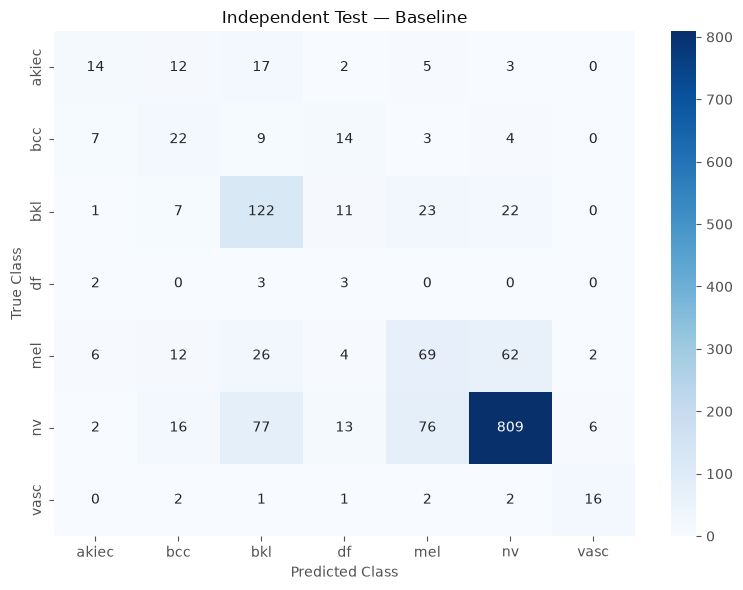


Pipeline: DullRazor
Run: Exp_MC_DullRazor_20261020_153728


Loading hair_removal: 100%|██████████| 1510/1510 [00:08<00:00, 173.94it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 555ms/step

Classification report:
              precision    recall  f1-score   support

       akiec       0.37      0.30      0.33        53
         bcc       0.38      0.36      0.37        59
         bkl       0.41      0.65      0.50       186
          df       0.10      0.38      0.15         8
         mel       0.50      0.37      0.42       181
          nv       0.91      0.85      0.88       999
        vasc       0.69      0.75      0.72        24

    accuracy                           0.72      1510
   macro avg       0.48      0.52      0.48      1510
weighted avg       0.75      0.72      0.73      1510



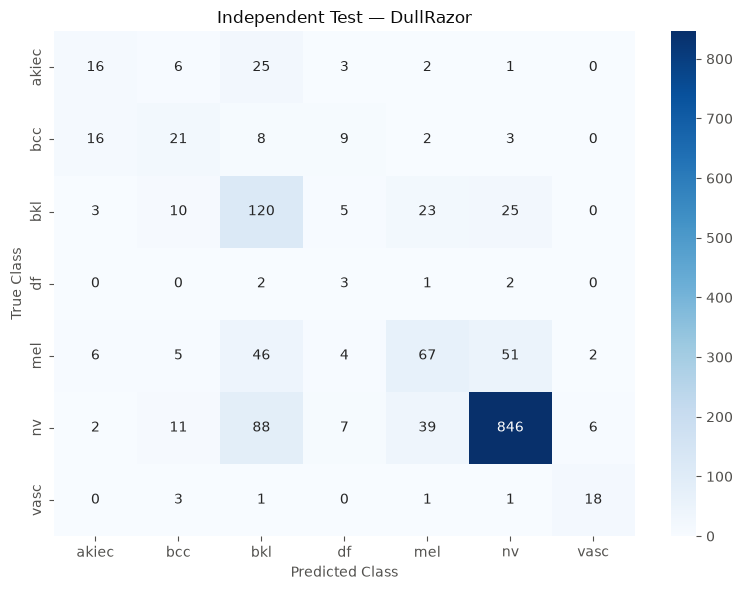


Pipeline: Shades of Gray
Run: Exp_MC_ShadesOfGray_20261020_155454


Loading color_constancy: 100%|██████████| 1510/1510 [00:02<00:00, 624.07it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 554ms/step

Classification report:
              precision    recall  f1-score   support

       akiec       0.73      0.36      0.48        53
         bcc       0.46      0.42      0.44        59
         bkl       0.46      0.66      0.54       186
          df       0.05      0.38      0.08         8
         mel       0.47      0.31      0.38       181
          nv       0.89      0.85      0.87       999
        vasc       0.76      0.79      0.78        24

    accuracy                           0.72      1510
   macro avg       0.55      0.54      0.51      1510
weighted avg       0.76      0.72      0.73      1510



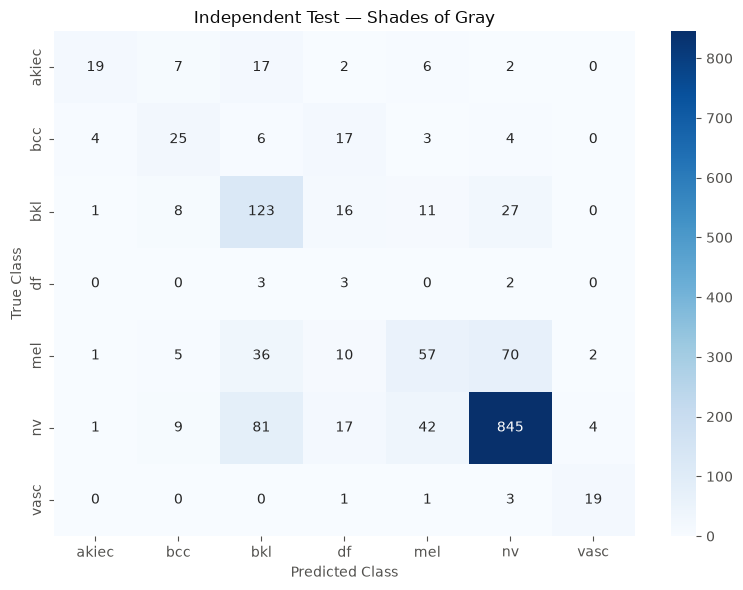


Pipeline: Contrast-Focused
Run: Exp_MC_ContrastFocused_20261020_161259


Loading contrast_focused: 100%|██████████| 1510/1510 [00:09<00:00, 156.74it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 545ms/step

Classification report:
              precision    recall  f1-score   support

       akiec       0.32      0.45      0.38        53
         bcc       0.39      0.41      0.40        59
         bkl       0.49      0.55      0.52       186
          df       0.06      0.25      0.10         8
         mel       0.35      0.35      0.35       181
          nv       0.90      0.84      0.87       999
        vasc       0.70      0.67      0.68        24

    accuracy                           0.71      1510
   macro avg       0.46      0.50      0.47      1510
weighted avg       0.74      0.71      0.72      1510



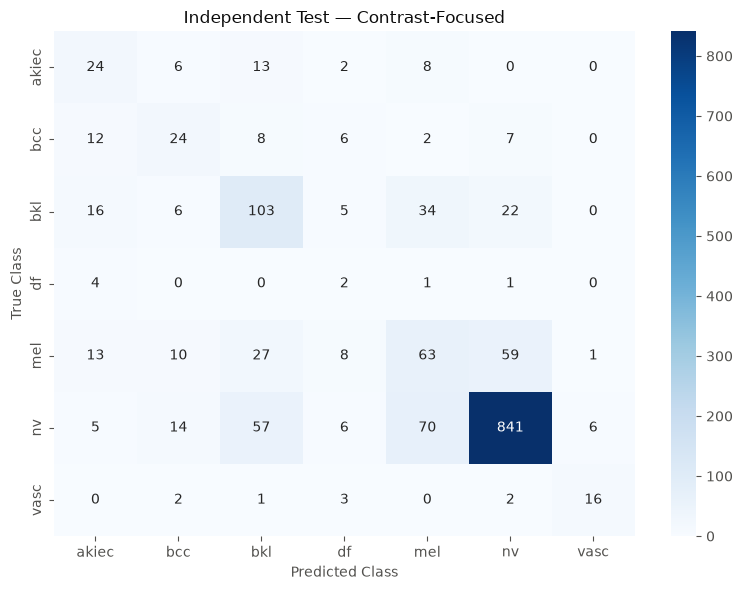

In [ ]:

# 5. Evaluate each trained model


all_results = []
all_predictions = {}

for pipeline in PIPELINE_ORDER:

    run_key = (
        "multiclass",
        TEST_RESOLUTION,
        pipeline
    )

    if run_key not in LATEST:
        raise RuntimeError(
            f"Missing experiment: {run_key}"
        )

    run = LATEST[run_key]
    run_dir = Path(run["dir"])

    print("\n" + "=" * 60)
    print("Pipeline:", PIPELINE_LABELS[pipeline])
    print("Run:", run_dir.name)
    print("=" * 60)

    # Find the trained multiclass model

    model_files = list(
        run_dir.glob("*_multiclass.keras")
    )

    if len(model_files) != 1:
        raise FileNotFoundError(
            f"Expected one multiclass .keras model "
            f"in {run_dir}, found {len(model_files)}."
        )

    model_path = model_files[0]

    # Load the configuration associated with this model

    json_path = model_path.with_suffix(".json")

    if not json_path.exists():
        raise FileNotFoundError(json_path)

    with open(
        json_path,
        "r",
        encoding="utf-8"
    ) as file:

        config = json.load(file)

    # Verify model configuration

    assert config["categories"] == CLASSES, (
        "Model class order does not match."
    )

    assert int(config["img_size"]) == 224

    assert config["preprocessing"] == (
        PIPELINE_METHODS[pipeline]
    ), "Preprocessing mismatch!"

    if not config.get("to_rgb", True):
        raise ValueError(
            "This evaluation expects RGB models."
        )

    if config.get("pad", False):
        raise ValueError(
            "Padding configuration differs."
        )

    # Load images with the correct preprocessing

    X_test = load_test_images(
        test_paths,
        PIPELINE_METHODS[pipeline],
        TEST_RESOLUTION
    )

    # Load trained model without recompiling

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # Generate predictions

    probabilities = model.predict(
        X_test,
        batch_size=32,
        verbose=1
    )

    assert probabilities.shape == (
        len(y_true),
        len(CLASSES)
    ), "Unexpected model output shape."

    assert np.isfinite(probabilities).all()

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    # Calculate performance metrics

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        average="macro",
        zero_division=0
    )

    class_recall = recall_score(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0
    )

    balanced_acc = float(
        np.mean(class_recall)
    )

    melanoma_recall = float(
        class_recall[CLASSES.index("mel")]
    )

    # Save summary metrics

    all_results.append({

        "Pipeline": PIPELINE_LABELS[pipeline],

        "Accuracy": accuracy,

        "Macro F1": macro_f1,

        "Balanced Accuracy": balanced_acc,

        "Melanoma Recall": melanoma_recall,

        "Test Images": len(y_true)

    })

    all_predictions[pipeline] = y_pred

    # Save per-image predictions

    predictions_df = pd.DataFrame({

        "image_id": test_meta["image_id"],

        "lesion_id": test_meta["lesion_id"],

        "true_class": test_meta["dx"],

        "predicted_class": [
            CLASSES[i] for i in y_pred
        ]

    })

    for class_index, class_name in enumerate(CLASSES):

        predictions_df[
            f"prob_{class_name}"
        ] = probabilities[:, class_index]

    predictions_df.to_csv(
        RESULTS_DIR /
        f"test_predictions_{pipeline}.csv",
        index=False
    )

    # Classification report

    print("\nClassification report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=range(len(CLASSES)),
            target_names=CLASSES,
            zero_division=0
        )
    )

    # Confusion matrix

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(CLASSES))
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES
    )

    plt.title(
        f"Independent Test — "
        f"{PIPELINE_LABELS[pipeline]}"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR /
        f"confusion_matrix_{pipeline}.png",
        dpi=200
    )

    plt.show()

    # Release model memory

    del model
    del X_test
    tf.keras.backend.clear_session()


In [ ]:

# 6. Final comparison table


results_df = pd.DataFrame(
    all_results
)

print("\n" + "=" * 60)
print("INDEPENDENT TEST — MULTICLASS 224 x 224")
print("=" * 60)

display(
    results_df.round(4)
)

results_df.to_csv(
    RESULTS_DIR / "test_results_224.csv",
    index=False
)



INDEPENDENT TEST — MULTICLASS 224 x 224


,Pipeline,Accuracy,Macro F1,Balanced Accuracy,Melanoma Recall,Test Images
0,Baseline,0.6987,0.4615,0.5037,0.3812,1510
1,DullRazor,0.7225,0.4826,0.5207,0.3702,1510
2,Shades of Gray,0.7225,0.5098,0.5387,0.3149,1510
3,Contrast-Focused,0.7106,0.4713,0.5028,0.3481,1510


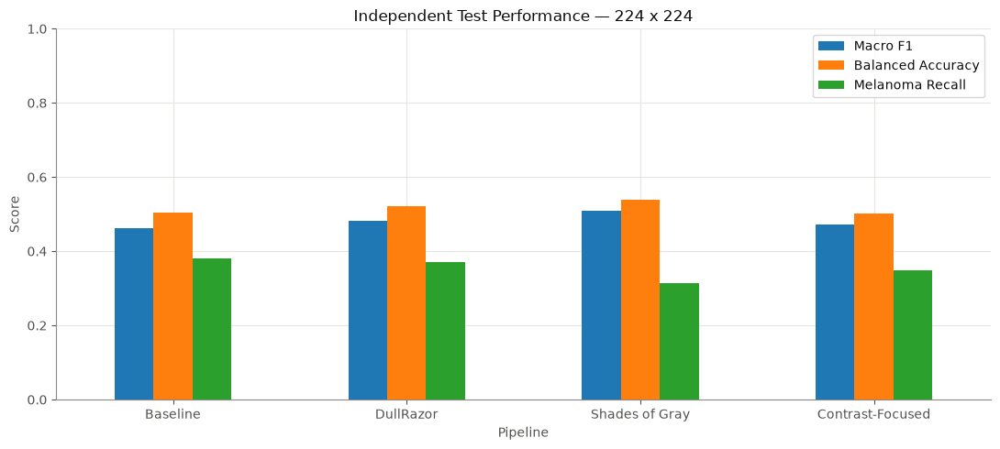


Evaluation completed successfully.
Results saved to: runs_dataleakage_fixed/independent_test_224


In [ ]:

# 7. Compare model performance


plot_df = results_df.set_index("Pipeline")[
    [
        "Macro F1",
        "Balanced Accuracy",
        "Melanoma Recall"
    ]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title(
    "Independent Test Performance — 224 x 224"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR /
    "test_comparison_224.png",
    dpi=200
)

plt.show()

print("\nEvaluation completed successfully.")
print("Results saved to:", RESULTS_DIR)

<h2 style="color: #0066cc;"><b># **11.10 INDEPENDENT TEST SET EVALUATION**</b><h2>
# Binary melanoma classification — 224 x 224

To run it:
1. Run Sections 11.1 and 11.2 to initialise the experiment information and verify dataset integrity.
2. Run Section 11.9 first, as the new code reuses its dataset paths and image preprocessing function.
3. Check that the four binary `.keras` models and their corresponding `.json` files are available in the experiment folders.
4. Run Section 11.10.

In [ ]:

# 11.10 INDEPENDENT TEST SET EVALUATION
# Binary melanoma classification — 224 x 224


from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)


In [ ]:

# 1. Configuration


BINARY_RESOLUTION = 224

BINARY_RESULTS_DIR = (
    RUNS_ROOT / "independent_test_binary_224"
)

BINARY_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Reuse the test metadata and preprocessing functions
# already defined and validated in Section 11.9.

required_variables = [
    "LATEST",
    "PIPELINE_ORDER",
    "PIPELINE_LABELS",
    "PIPELINE_METHODS",
    "CLASSES",
    "test_meta",
    "test_paths",
    "load_test_images"
]

missing_variables = []
for name in required_variables:
    if name not in globals():
        print(f"Falta la variable: {name}")
        missing_variables.append(name)

if missing_variables:
    raise RuntimeError(
        "Run Sections 11.1, 11.2 and 11.9 first. "
        f"Missing variables: {missing_variables}"
    )

# Verify the test set size and class labels.

assert len(test_meta) == len(test_paths)

assert len(test_meta) == 1510, (
    "Unexpected number of test images."
)

assert set(test_meta["dx"]).issubset(set(CLASSES))

# Binary ground truth: melanoma = 1, non-melanoma = 0.

y_binary_test = (
    test_meta["dx"] == "mel"
).astype(int).to_numpy()

assert y_binary_test.sum() == 181, (
    "Unexpected melanoma count in test data."
)

print("Independent binary test set")
print("Total images:", len(y_binary_test))
print("Melanoma images:", y_binary_test.sum())
print(
    "Non-melanoma images:",
    len(y_binary_test) - y_binary_test.sum()
)

Independent binary test set
Total images: 1510
Melanoma images: 181
Non-melanoma images: 1329


In [ ]:

# 2. Evaluation helper


def evaluate_binary_test(y_true, probabilities, threshold):
    """
    Calculate binary classification metrics using the
    decision threshold selected during validation.

    The test set is never used for threshold optimisation.
    """

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    metrics = {
        "ROC-AUC": roc_auc_score(
            y_true,
            probabilities
        ),

        "Average Precision": average_precision_score(
            y_true,
            probabilities
        ),

        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Melanoma F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Threshold": threshold,

        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }

    return metrics, predictions



Evaluating: Baseline
Experiment: Exp_Baseline_20261020_113903
Decision threshold: 0.51


Loading baseline: 100%|██████████| 1510/1510 [00:00<00:00, 4648.63it/s]
W0000 00:00:1792596624.144146  144328 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1792596624.182216  138685 dlopen_checker.cc:38] Could not load dynamic library 'libcudnn.so.9'; dlerror: libcudnn.so.9: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/fabio-noriega/anaconda3/envs/ist_ML/lib/python3.14/site-packages/cv2/../../lib64:
W0000 00:00:1792596624.182238  138685 gpu_device.cc:2359] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would 

48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 559ms/step

Test results:
ROC-AUC: 0.8219
Average Precision: 0.3420
Sensitivity: 0.3481
Specificity: 0.9248
Precision: 0.3865
Melanoma F1: 0.3663

Classification report:
              precision    recall  f1-score   support

Non-melanoma       0.91      0.92      0.92      1329
    Melanoma       0.39      0.35      0.37       181

    accuracy                           0.86      1510
   macro avg       0.65      0.64      0.64      1510
weighted avg       0.85      0.86      0.85      1510



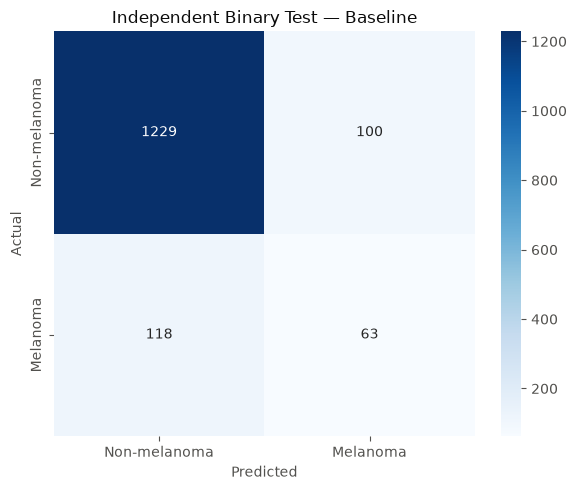

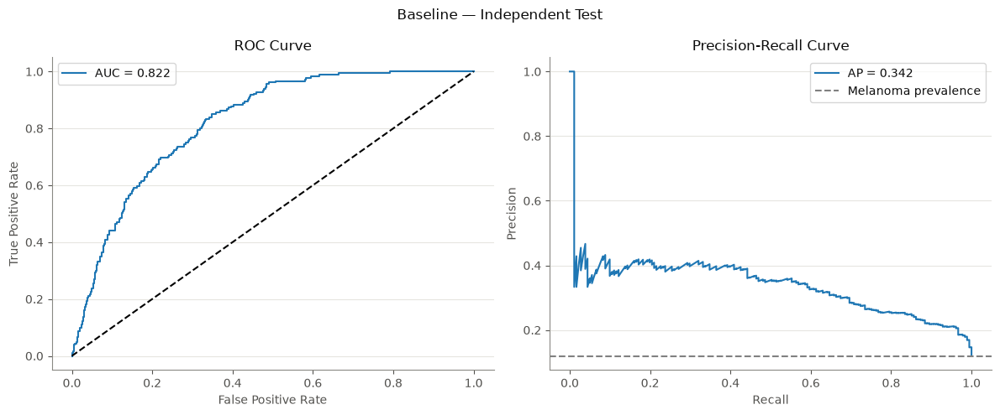


Evaluating: DullRazor
Experiment: Exp_DullRazor_20261020_114943
Decision threshold: 0.32


Loading hair_removal: 100%|██████████| 1510/1510 [00:08<00:00, 177.83it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 28s 546ms/step

Test results:
ROC-AUC: 0.8401
Average Precision: 0.4418
Sensitivity: 0.6354
Specificity: 0.8345
Precision: 0.3433
Melanoma F1: 0.4457

Classification report:
              precision    recall  f1-score   support

Non-melanoma       0.94      0.83      0.89      1329
    Melanoma       0.34      0.64      0.45       181

    accuracy                           0.81      1510
   macro avg       0.64      0.73      0.67      1510
weighted avg       0.87      0.81      0.83      1510



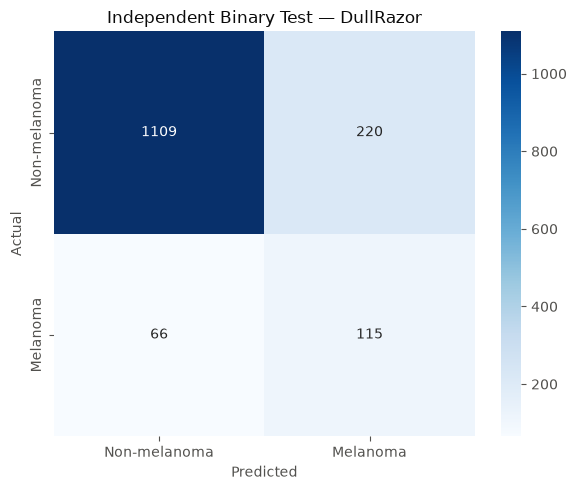

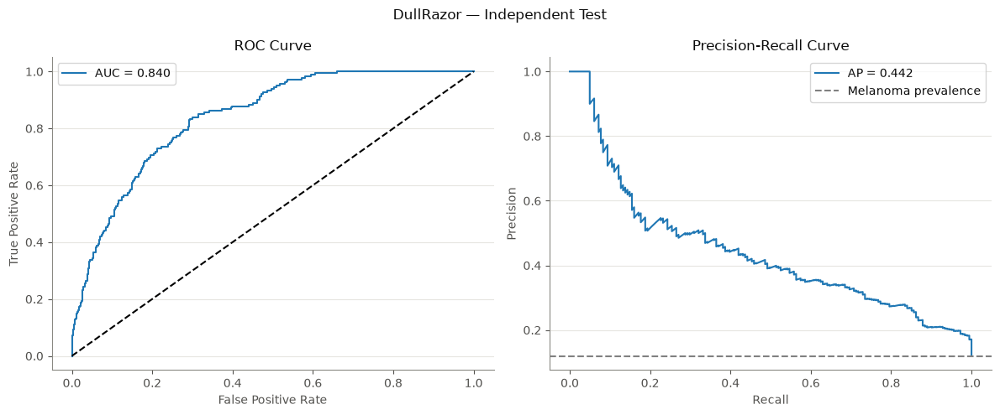


Evaluating: Shades of Gray
Experiment: Exp_ShadesOfGray_20261020_120629
Decision threshold: 0.52


Loading color_constancy: 100%|██████████| 1510/1510 [00:02<00:00, 618.31it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 44s 901ms/step

Test results:
ROC-AUC: 0.8153
Average Precision: 0.3539
Sensitivity: 0.3315
Specificity: 0.9338
Precision: 0.4054
Melanoma F1: 0.3647

Classification report:
              precision    recall  f1-score   support

Non-melanoma       0.91      0.93      0.92      1329
    Melanoma       0.41      0.33      0.36       181

    accuracy                           0.86      1510
   macro avg       0.66      0.63      0.64      1510
weighted avg       0.85      0.86      0.86      1510



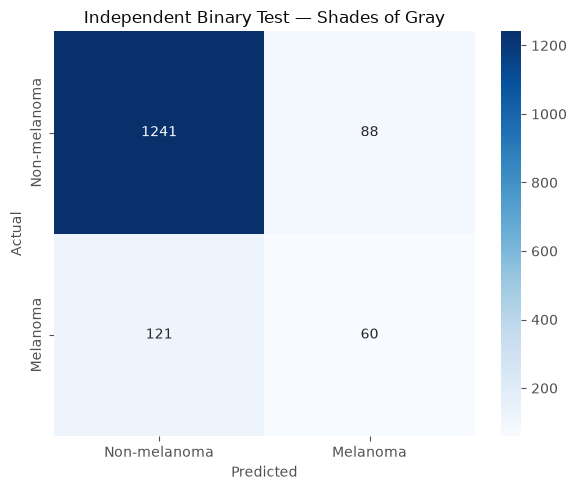

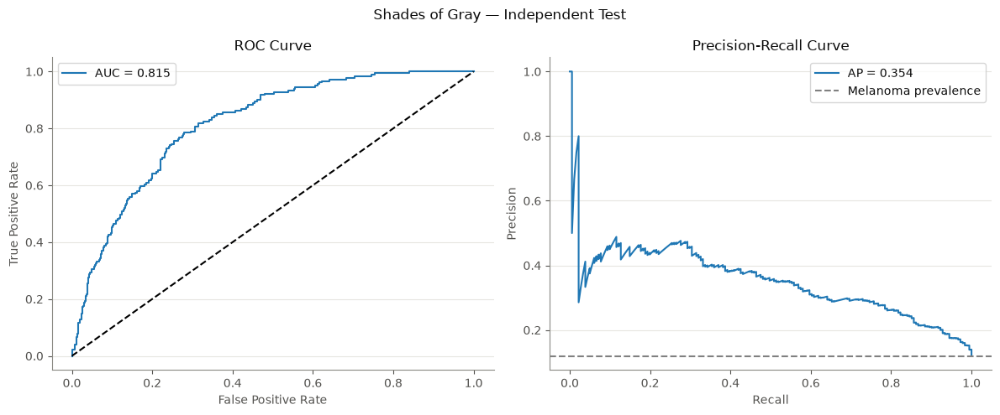


Evaluating: Contrast-Focused
(DullRazor + CLAHE)
Experiment: Exp_ContrastFocused_20261020_122019
Decision threshold: 0.37


Loading contrast_focused: 100%|██████████| 1510/1510 [00:12<00:00, 118.98it/s]


48/48 ━━━━━━━━━━━━━━━━━━━━ 27s 539ms/step

Test results:
ROC-AUC: 0.8128
Average Precision: 0.3643
Sensitivity: 0.4917
Specificity: 0.8548
Precision: 0.3156
Melanoma F1: 0.3844

Classification report:
              precision    recall  f1-score   support

Non-melanoma       0.93      0.85      0.89      1329
    Melanoma       0.32      0.49      0.38       181

    accuracy                           0.81      1510
   macro avg       0.62      0.67      0.64      1510
weighted avg       0.85      0.81      0.83      1510



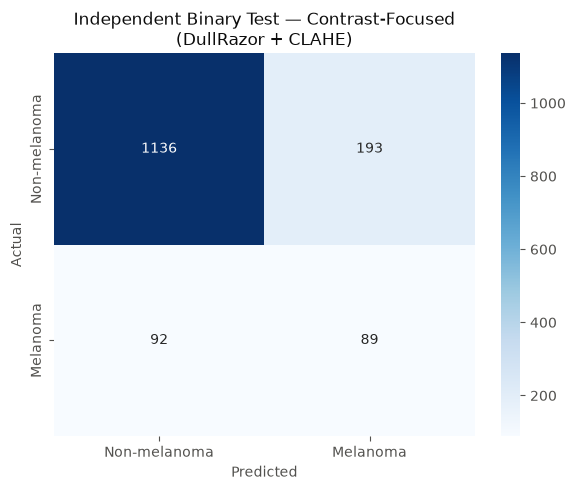

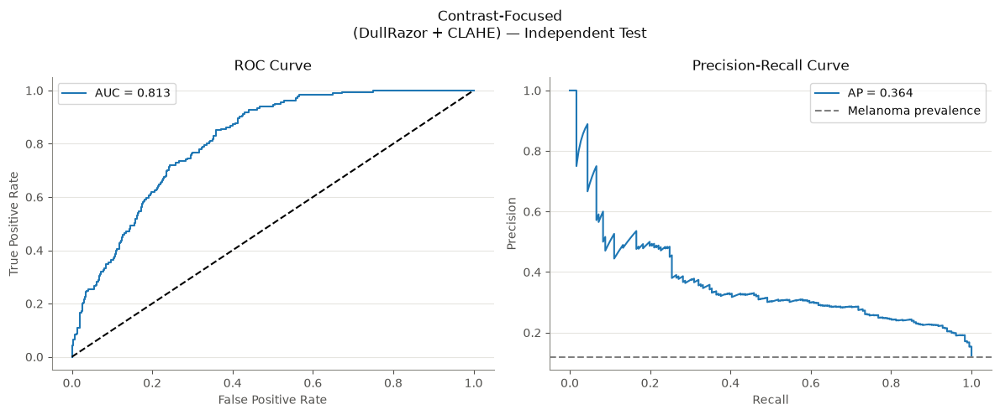

In [ ]:

# 3. Load and evaluate the four binary models


binary_test_results = []
binary_test_predictions = {}

for pipeline in PIPELINE_ORDER:

    run_key = (
        "binary",
        BINARY_RESOLUTION,
        pipeline
    )

    if run_key not in LATEST:
        raise RuntimeError(
            f"Binary experiment not found: {run_key}"
        )

    run = LATEST[run_key]
    run_dir = Path(run["dir"])

    print("\n" + "=" * 65)
    print("Evaluating:", PIPELINE_LABELS[pipeline])
    print("Experiment:", run_dir.name)
    print("=" * 65)

    # Locate saved binary model.

    model_files = list(
        run_dir.glob("*_stage1.keras")
    )

    if len(model_files) != 1:
        raise FileNotFoundError(
            f"Expected exactly one binary .keras model "
            f"in {run_dir}. Found: {len(model_files)}"
        )

    model_path = model_files[0]

    # Read model metadata.

    json_path = model_path.with_suffix(".json")

    if not json_path.exists():
        raise FileNotFoundError(
            f"Model metadata not found: {json_path}"
        )

    with open(
        json_path,
        "r",
        encoding="utf-8"
    ) as f:

        model_config = json.load(f)

    # Validate model configuration.

    if int(model_config["img_size"]) != BINARY_RESOLUTION:
        raise ValueError(
            "Model input resolution does not match."
        )

    if model_config["preprocessing"] != PIPELINE_METHODS[pipeline]:
        raise ValueError(
            "Preprocessing pipeline mismatch."
        )

    if not model_config.get("to_rgb", True):
        raise ValueError(
            "Expected an RGB model."
        )

    if model_config.get("pad", False):
        raise ValueError(
            "Padding configuration does not match."
        )

    # Use the saved validation-selected threshold.

    threshold = float(model_config["thr"])

    if not 0 <= threshold <= 1:
        raise ValueError(
            "Invalid saved decision threshold."
        )

    print("Decision threshold:", threshold)

    # Apply the SAME preprocessing used during training.
    # No data augmentation is applied during testing.
    #
    # IMPORTANT:
    # This assumes Datasets_safe/test contains baseline-
    # prepared images, as in Section 11.9.

    X_test_binary = load_test_images(
        test_paths,
        PIPELINE_METHODS[pipeline],
        BINARY_RESOLUTION
    )

    # Load trained model without recompilation.

    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # Predict melanoma probabilities.

    probabilities = model.predict(
        X_test_binary,
        batch_size=32,
        verbose=1
    ).reshape(-1)

    if len(probabilities) != len(y_binary_test):
        raise ValueError(
            "Prediction count does not match test set."
        )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            "Model produced non-finite probabilities."
        )

    # Calculate metrics.

    metrics, predictions = evaluate_binary_test(
        y_binary_test,
        probabilities,
        threshold
    )

    binary_test_results.append({
        "Pipeline": PIPELINE_LABELS[pipeline],
        **metrics
    })

    binary_test_predictions[pipeline] = {
        "probabilities": probabilities.copy(),
        "predictions": predictions.copy()
    }

    print("\nTest results:")
    for metric_name in [
        "ROC-AUC",
        "Average Precision",
        "Sensitivity",
        "Specificity",
        "Precision",
        "Melanoma F1"
    ]:
        print(
            f"{metric_name}: {metrics[metric_name]:.4f}"
        )

    print("\nClassification report:")
    print(
        classification_report(
            y_binary_test,
            predictions,
            labels=[0, 1],
            target_names=[
                "Non-melanoma",
                "Melanoma"
            ],
            zero_division=0
        )
    )

    
    # 4. Save per-image predictions
    

    predictions_df = pd.DataFrame({
        "image_id": test_meta["image_id"].to_numpy(),
        "lesion_id": test_meta["lesion_id"].to_numpy(),
        "true_class": test_meta["dx"].to_numpy(),
        "true_melanoma": y_binary_test,
        "melanoma_probability": probabilities,
        "predicted_melanoma": predictions
    })

    predictions_df.to_csv(
        BINARY_RESULTS_DIR /
        f"binary_predictions_{pipeline}.csv",
        index=False
    )

    
    # 5. Confusion matrix
    

    cm = confusion_matrix(
        y_binary_test,
        predictions,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-melanoma", "Melanoma"],
        yticklabels=["Non-melanoma", "Melanoma"],
        ax=ax
    )

    ax.set_title(
        f"Independent Binary Test — "
        f"{PIPELINE_LABELS[pipeline]}"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    fig.tight_layout()

    fig.savefig(
        BINARY_RESULTS_DIR /
        f"binary_confusion_{pipeline}.png",
        dpi=200
    )

    plt.show()
    plt.close(fig)

    
    # 6. ROC and Precision-Recall curves
    

    fpr, tpr, _ = roc_curve(
        y_binary_test,
        probabilities
    )

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_binary_test,
            probabilities
        )
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    axes[0].plot(
        fpr,
        tpr,
        label=f"AUC = {metrics['ROC-AUC']:.3f}"
    )

    axes[0].plot(
        [0, 1],
        [0, 1],
        "k--"
    )

    axes[0].set_title("ROC Curve")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].legend()

    axes[1].plot(
        recall_curve,
        precision_curve,
        label=(
            f"AP = {metrics['Average Precision']:.3f}"
        )
    )

    axes[1].axhline(
        y_binary_test.mean(),
        linestyle="--",
        color="gray",
        label="Melanoma prevalence"
    )

    axes[1].set_title("Precision-Recall Curve")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend()

    fig.suptitle(
        f"{PIPELINE_LABELS[pipeline]} — Independent Test"
    )

    fig.tight_layout()

    fig.savefig(
        BINARY_RESULTS_DIR /
        f"binary_curves_{pipeline}.png",
        dpi=200
    )

    plt.show()
    plt.close(fig)

    # Release memory before the next model.

    del model
    del X_test_binary

    tf.keras.backend.clear_session()
    gc.collect()




INDEPENDENT BINARY TEST RESULTS — 224 x 224


,Pipeline,ROC-AUC,Average Precision,Sensitivity,Specificity,Precision,Melanoma F1,Threshold,FN,FP
0,Baseline,0.8219,0.3420,0.3481,0.9248,0.3865,0.3663,0.51,118,100
1,DullRazor,0.8401,0.4418,0.6354,0.8345,0.3433,0.4457,0.32,66,220
2,Shades of Gray,0.8153,0.3539,0.3315,0.9338,0.4054,0.3647,0.52,121,88
3,Contrast-Focused\n(DullRazor + CLAHE),0.8128,0.3643,0.4917,0.8548,0.3156,0.3844,0.37,92,193


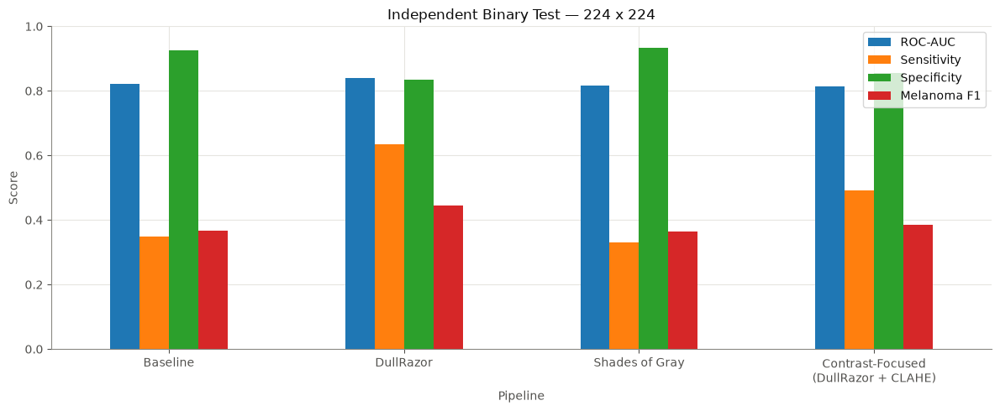


Binary independent test evaluation completed.
Results saved to: runs_dataleakage_fixed/independent_test_binary_224


In [ ]:

# 7. Final comparison table


binary_results_df = pd.DataFrame(
    binary_test_results
)

display_columns = [
    "Pipeline",
    "ROC-AUC",
    "Average Precision",
    "Sensitivity",
    "Specificity",
    "Precision",
    "Melanoma F1",
    "Threshold",
    "FN",
    "FP"
]

print("\n" + "=" * 65)
print("INDEPENDENT BINARY TEST RESULTS — 224 x 224")
print("=" * 65)

display(
    binary_results_df[
        display_columns
    ].round(4)
)

binary_results_df.to_csv(
    BINARY_RESULTS_DIR /
    "binary_test_results_224.csv",
    index=False
)



# 8. Comparison plot


comparison_metrics = [
    "ROC-AUC",
    "Sensitivity",
    "Specificity",
    "Melanoma F1"
]

plot_data = binary_results_df.set_index(
    "Pipeline"
)[comparison_metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 5),
    rot=0
)

ax.set_title(
    "Independent Binary Test — 224 x 224"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    BINARY_RESULTS_DIR /
    "binary_comparison_224.png",
    dpi=200
)

plt.show()
plt.close()


print("\nBinary independent test evaluation completed.")
print("Results saved to:", BINARY_RESULTS_DIR)

Independent test (224x224): 1510 images, 181 melanomas, 1121 lesions; 1000 lesion-level bootstrap resamples.
Threshold = highest specificity with sensitivity >= 85% on VALIDATION, frozen for test.


,Pipeline,Threshold (from val.),ROC-AUC [95% CI],Avg. precision,Sensitivity [95% CI],Specificity [95% CI],Precision,FN,FP
0,Baseline,0.200,"0.822 [0.788, 0.854]",0.342,"0.856 [0.796, 0.914]","0.634 [0.603, 0.662]",0.241,26,487
1,DullRazor,0.163,"0.840 [0.808, 0.874]",0.442,"0.851 [0.792, 0.911]","0.671 [0.640, 0.700]",0.261,27,437
2,Shades of Gray,0.119,"0.815 [0.775, 0.853]",0.354,"0.856 [0.795, 0.916]","0.607 [0.578, 0.636]",0.229,26,522
3,Contrast-Focused,0.149,"0.813 [0.779, 0.845]",0.364,"0.867 [0.818, 0.917]","0.603 [0.574, 0.631]",0.230,24,527


Paired differences versus Baseline (* = 95% interval excludes 0, i.e. distinguishable from noise)


,Pipeline,Δ AUC vs Baseline,Δ Sensitivity,Δ Specificity
0,DullRazor,"+0.018 [-0.007, +0.045]","-0.006 [-0.058, +0.043]","+0.038 [+0.011, +0.065] *"
1,Shades of Gray,"-0.007 [-0.028, +0.015]","+0.000 [-0.043, +0.042]","-0.026 [-0.054, +0.002]"
2,Contrast-Focused,"-0.009 [-0.035, +0.017]","+0.011 [-0.037, +0.062]","-0.030 [-0.057, -0.002] *"


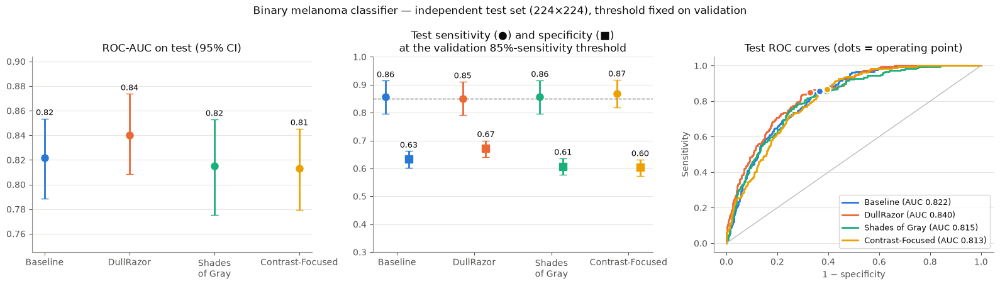

Saved: runs_dataleakage_fixed/independent_test_binary_224/binary_test_at_val_threshold_224.png


In [ ]:

# 11.11 Binary test set at the PRE-DECLARED operating point (sensitivity >= 85% on VALIDATION)
# ------------------------------------------------------------
# Section 11.10 applied the F1 threshold saved in each model's .json, so every pipeline was
# evaluated at a different threshold (0.51 / 0.32 / 0.52 / 0.37) and sensitivities on test were
# not comparable. Here:
#   1. the threshold is chosen on VALIDATION with the rule of section 11.3
#      (highest specificity with sensitivity >= 85%),
#   2. it is frozen and applied to TEST (the test set chooses nothing),
#   3. 95% lesion-level bootstrap intervals + paired differences versus Baseline are reported.
# No TensorFlow needed: it reads the per-image test predictions saved by 11.10
# (runs_dataleakage_fixed/independent_test_binary_224/binary_predictions_<pipeline>.csv).

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from IPython.display import display

RUNS_ROOT = Path("runs_dataleakage_fixed")
TEST_PRED_DIR = RUNS_ROOT / "independent_test_binary_224"
TARGET_SENSITIVITY = 0.85
N_BOOT, SEED = 1000, 42
ORDER = ["baseline", "dullrazor", "shades_of_gray", "dullrazor_clahe"]
LABELS = {"baseline": "Baseline", "dullrazor": "DullRazor", "shades_of_gray": "Shades of Gray",
          "dullrazor_clahe": "Contrast-Focused"}
COLORS = {"baseline": "#2a78d6", "dullrazor": "#eb6834", "shades_of_gray": "#1baf7a", "dullrazor_clahe": "#eda100"}
# 224x224 binary runs (same folders as 11.2); LATEST is used instead if it is in memory
VAL_RUNS = {"baseline": "Exp_Baseline_20261020_113903", "dullrazor": "Exp_DullRazor_20261020_114943",
            "shades_of_gray": "Exp_ShadesOfGray_20261020_120629",
            "dullrazor_clahe": "Exp_ContrastFocused_20261020_122019"}


def val_run_dir(p):
    if "LATEST" in globals() and ("binary", 224, p) in LATEST:
        return Path(LATEST[("binary", 224, p)]["dir"])
    hits = list(RUNS_ROOT.rglob(VAL_RUNS[p]))
    if not hits:
        raise FileNotFoundError(f"Validation run not found: {VAL_RUNS[p]}")
    return hits[0]


def threshold_at_sensitivity(y, p, target=TARGET_SENSITIVITY):
    # Same rule as 11.3: among thresholds with sensitivity >= target, the one with the highest specificity
    best = None
    for t in np.unique(np.r_[p, 1.0]):
        pred = p >= t
        sens = (pred & (y == 1)).sum() / max((y == 1).sum(), 1)
        spec = (~pred & (y == 0)).sum() / max((y == 0).sum(), 1)
        if sens >= target and (best is None or spec > best[1] or (spec == best[1] and t > best[0])):
            best = (float(t), spec)
    return best[0]


def point(y, p, t):
    pred = p >= t
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    return dict(auc=roc_auc_score(y, p), ap=average_precision_score(y, p), sens=tp / (tp + fn),
                spec=tn / (tn + fp), prec=tp / max(tp + fp, 1), tp=tp, fp=fp, fn=fn, tn=tn)


# 1. Thresholds from validation; test predictions from 11.10 
data, rows = {}, []
for p in ORDER:
    vdir = val_run_dir(p)
    vp = next((vdir / n for n in ("predicciones_validacion.csv", "validation_predictions.csv") if (vdir / n).exists()), None)
    if vp is None:
        raise FileNotFoundError(f"No validation predictions in {vdir}")
    v = pd.read_csv(vp).rename(columns={"y_actual_mel": "y_real_mel"})
    thr = threshold_at_sensitivity(v["y_real_mel"].to_numpy(int), v["p_mel"].to_numpy(float))
    t = pd.read_csv(TEST_PRED_DIR / f"binary_predictions_{p}.csv")
    data[p] = dict(thr=thr, y=t["true_melanoma"].to_numpy(int), p=t["melanoma_probability"].to_numpy(float),
                   lesion=t["lesion_id"].to_numpy(), image=t["image_id"].to_numpy())

ref = data["baseline"]
for p in ORDER:   # every pipeline must be scored on the same images in the same order (paired bootstrap)
    assert (data[p]["image"] == ref["image"]).all(), f"Image order differs for {p}"

# 2. Lesion-level bootstrap (same resamples for every pipeline -> paired differences) 
lesions = pd.Series(ref["lesion"])
groups = lesions.groupby(lesions).indices
keys = np.array(list(groups))
rng = np.random.default_rng(SEED)
boot_idx = []
while len(boot_idx) < N_BOOT:
    idx = np.concatenate([groups[k] for k in rng.choice(keys, len(keys), replace=True)])
    if 0 < ref["y"][idx].sum() < len(idx):
        boot_idx.append(idx)

boots = {}
for p in ORDER:
    d = data[p]
    boots[p] = pd.DataFrame([point(d["y"][i], d["p"][i], d["thr"]) for i in boot_idx])
    rows.append(dict(pipeline=p, **point(d["y"], d["p"], d["thr"]), thr=d["thr"]))
res = pd.DataFrame(rows).set_index("pipeline")


def ci(s):
    return np.percentile(s, [2.5, 97.5])


def fmt(v, s):
    lo, hi = ci(s)
    return f"{v:.3f} [{lo:.3f}, {hi:.3f}]"


def fmt_delta(s, v):
    lo, hi = ci(s)
    return f"{v:+.3f} [{lo:+.3f}, {hi:+.3f}]" + ("" if lo <= 0 <= hi else "  *")


table = pd.DataFrame({
    "Pipeline": [LABELS[p] for p in ORDER],
    "Threshold (from val.)": [round(res.loc[p, "thr"], 3) for p in ORDER],
    "ROC-AUC [95% CI]": [fmt(res.loc[p, "auc"], boots[p]["auc"]) for p in ORDER],
    "Avg. precision": [round(res.loc[p, "ap"], 3) for p in ORDER],
    "Sensitivity [95% CI]": [fmt(res.loc[p, "sens"], boots[p]["sens"]) for p in ORDER],
    "Specificity [95% CI]": [fmt(res.loc[p, "spec"], boots[p]["spec"]) for p in ORDER],
    "Precision": [round(res.loc[p, "prec"], 3) for p in ORDER],
    "FN": [res.loc[p, "fn"] for p in ORDER], "FP": [res.loc[p, "fp"] for p in ORDER],
})
print(f"Independent test (224x224): {len(ref['y'])} images, {ref['y'].sum()} melanomas, "
      f"{len(groups)} lesions; {N_BOOT} lesion-level bootstrap resamples.")
print(f"Threshold = highest specificity with sensitivity >= {TARGET_SENSITIVITY:.0%} on VALIDATION, frozen for test.")
display(table)

paired = pd.DataFrame({
    "Pipeline": [LABELS[p] for p in ORDER[1:]],
    "Δ AUC vs Baseline": [fmt_delta(boots[p]["auc"] - boots["baseline"]["auc"],
                                    res.loc[p, "auc"] - res.loc["baseline", "auc"]) for p in ORDER[1:]],
    "Δ Sensitivity": [fmt_delta(boots[p]["sens"] - boots["baseline"]["sens"],
                                res.loc[p, "sens"] - res.loc["baseline", "sens"]) for p in ORDER[1:]],
    "Δ Specificity": [fmt_delta(boots[p]["spec"] - boots["baseline"]["spec"],
                                res.loc[p, "spec"] - res.loc["baseline", "spec"]) for p in ORDER[1:]],
})
print("Paired differences versus Baseline (* = 95% interval excludes 0, i.e. distinguishable from noise)")
display(paired)
table.to_csv(TEST_PRED_DIR / "binary_test_at_val_threshold_224.csv", index=False)
paired.to_csv(TEST_PRED_DIR / "binary_test_paired_vs_baseline_224.csv", index=False)

# 3. Figure for the slide: AUC with CI | sensitivity & specificity with CI | ROC 
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
x = np.arange(len(ORDER))
for k, p in enumerate(ORDER):
    for ax, m in ((axes[0], "auc"), (axes[1], "sens"), (axes[1], "spec")):
        off = 0 if ax is axes[0] else (-0.15 if m == "sens" else 0.15)
        v, (lo, hi) = res.loc[p, m], ci(boots[p][m])
        ax.errorbar(k + off, v, yerr=[[v - lo], [hi - v]], fmt="o" if m != "spec" else "s", ms=8,
                    color=COLORS[p], capsize=4, lw=2)
        ax.annotate(f"{v:.2f}", (k + off, hi), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
for ax in axes[:2]:
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[p].replace(" ", "\n", 1) if p == "shades_of_gray" else LABELS[p] for p in ORDER])
auc_lo = min(ci(boots[p]["auc"])[0] for p in ORDER)
auc_hi = max(ci(boots[p]["auc"])[1] for p in ORDER)
axes[0].set(title="ROC-AUC on test (95% CI)", ylim=(auc_lo - 0.03, min(auc_hi + 0.03, 1.0)))
axes[1].axhline(TARGET_SENSITIVITY, color="gray", ls="--", lw=1)
axes[1].set(title="Test sensitivity (●) and specificity (■)\nat the validation 85%-sensitivity threshold", ylim=(0.3, 1.0))
for p in ORDER:
    fpr, tpr, _ = roc_curve(data[p]["y"], data[p]["p"])
    axes[2].plot(fpr, tpr, color=COLORS[p], lw=2, label=f"{LABELS[p]} (AUC {res.loc[p, 'auc']:.3f})")
    axes[2].scatter(1 - res.loc[p, "spec"], res.loc[p, "sens"], color=COLORS[p], s=60, zorder=3,
                    edgecolor="white", linewidth=1.5)
axes[2].plot([0, 1], [0, 1], color="#bbbbbb", lw=1)
axes[2].set(title="Test ROC curves (dots = operating point)", xlabel="1 − specificity", ylabel="Sensitivity")
axes[2].legend(loc="lower right", fontsize=9)
fig.suptitle("Binary melanoma classifier — independent test set (224×224), threshold fixed on validation", fontsize=12)
plt.tight_layout()
out = TEST_PRED_DIR / "binary_test_at_val_threshold_224.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", out)

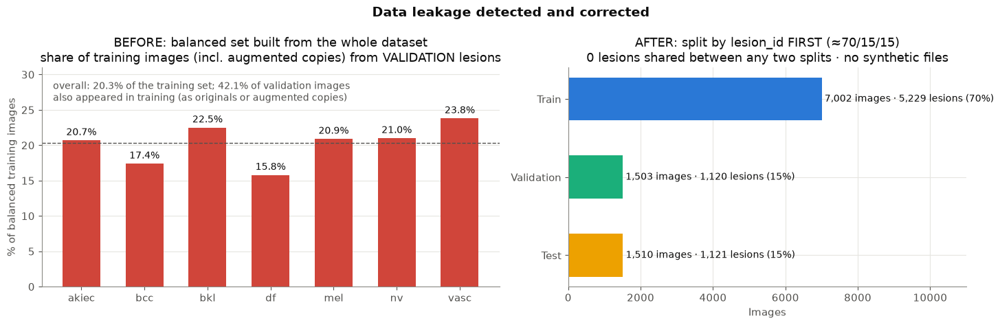

In [25]:
# Slide figure: the data leakage found in the first balancing approach, and the corrected split.
# All numbers come from the notebook outputs (section 7.5 and cell 11.2); no data files are needed.
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
                     "axes.edgecolor": "#8a8983", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

classes = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
leak_pct = [20.7, 17.4, 22.5, 15.8, 20.9, 21.0, 23.8]          # section 7.5
splits = ["Train", "Validation", "Test"]
images = [7002, 1503, 1510]                                      # cell 11.2
lesions = [5229, 1120, 1121]

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})

bars = a.bar(classes, leak_pct, color="#d0453a", width=0.6)
a.bar_label(bars, labels=[f"{v:.1f}%" for v in leak_pct], padding=3, fontsize=10)
a.axhline(20.3, color="#52514e", ls="--", lw=1)
a.text(-0.45, 27.5, "overall: 20.3% of the training set; 42.1% of validation images\nalso appeared in training (as originals or augmented copies)",
       ha="left", va="center", fontsize=10, color="#52514e")
a.set(ylim=(0, 31), ylabel="% of balanced training images",
      title="BEFORE: balanced set built from the whole dataset\n"
            "share of training images (incl. augmented copies) from VALIDATION lesions")
a.grid(axis="y", color="#e6e5e0")
a.set_axisbelow(True)

y = np.arange(len(splits))[::-1]
colors = ["#2a78d6", "#1baf7a", "#eda100"]
b.barh(y, images, color=colors, height=0.55)
for yi, n, l in zip(y, images, lesions):
    b.text(n + 80, yi, f"{n:,} images · {l:,} lesions ({100 * n / sum(images):.0f}%)", va="center", fontsize=10)
b.set_yticks(y)
b.set_yticklabels(splits)
b.set(xlim=(0, 11000), xlabel="Images",
      title="AFTER: split by lesion_id FIRST (≈70/15/15)\n"
            "0 lesions shared between any two splits · no synthetic files")
b.grid(axis="x", color="#e6e5e0")
b.set_axisbelow(True)

fig.suptitle("Data leakage detected and corrected", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig("leakage_before_after.png", dpi=200, bbox_inches="tight")
plt.show()